# Projeto - Análise e Preparação de Dados
## Inteligência Artificial e Ciência de Dados / PUCPR

**Prof. Jean Paul Barddal**

`Josué Telles Corrêa`

`Alexandre Hauffe`

`Nome aqui`

`Nome aqui`

`Nome aqui`

---
**Base de dados:** [IBM HR Analytics Employee Attrition & Performance](https://www.kaggle.com/datasets/pavansubhasht/ibm-hr-analytics-attrition-dataset) (Kaggle, 1.470 funcionários e 35 colunas originais). É um conjunto **fictício**, criado por cientistas de dados da IBM para estudar a rotatividade (*attrition*) de funcionários.

**Problema:** entender quais características dos funcionários estão associadas à saída da empresa (`Attrition = Yes`) e preparar os dados para modelos de aprendizado de máquina.

# Importe as bibliotecas necessárias

In [1]:
# Importe todos os pacotes necessários aqui
import os
import sys
import subprocess
import textwrap
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from scipy import stats
from IPython.display import display


warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold"})

RANDOM_STATE = 42          # semente única: garante resultados reproduzíveis
np.random.seed(RANDOM_STATE)

# Carregue os dados

Abaixo, carregue os dados utilizando o pandas e realize toda a limpeza necessária para garantir que os tipos de dados estejam corretos para as análises posteriores.

A função `carregar_base()` tenta, nesta ordem: (1) ler o arquivo CSV da pasta atual; (2) baixar a base do Kaggle com a biblioteca `kagglehub`; (3) pedir o upload manual do arquivo (somente no Google Colab). Assim, o notebook roda sem alterações no Colab ou no computador.

In [2]:
# carregue seus dados aqui
NOME_ARQUIVO = "WA_Fn-UseC_-HR-Employee-Attrition.csv"
KAGGLE_ID = "pavansubhasht/ibm-hr-analytics-attrition-dataset"


def carregar_base():
    """Carrega a base: arquivo local -> kagglehub -> upload manual (Colab)."""
    if os.path.exists(NOME_ARQUIVO):
        print("Lendo arquivo local:", NOME_ARQUIVO)
        return pd.read_csv(NOME_ARQUIVO)
    try:
        try:
            import kagglehub
        except ImportError:
            subprocess.run([sys.executable, "-m", "pip", "install", "-q", "kagglehub"], check=True)
            import kagglehub
        pasta = kagglehub.dataset_download(KAGGLE_ID)
        csvs = [f for f in os.listdir(pasta) if f.lower().endswith(".csv")]
        print("Base baixada do Kaggle em:", pasta)
        return pd.read_csv(os.path.join(pasta, csvs[0]))
    except Exception as erro:
        print("Download automático indisponível:", repr(erro))
    try:
        from google.colab import files
        print(f"Faça o upload do arquivo {NOME_ARQUIVO} "
              f"(https://www.kaggle.com/datasets/{KAGGLE_ID}).")
        enviado = files.upload()
        return pd.read_csv(next(iter(enviado)))
    except ImportError:
        raise FileNotFoundError(
            f"Coloque o arquivo {NOME_ARQUIVO} na mesma pasta do notebook "
            f"(download em https://www.kaggle.com/datasets/{KAGGLE_ID}).")


df_bruto = carregar_base()
df = df_bruto.copy()

print(f"Dimensões originais: {df.shape[0]} linhas x {df.shape[1]} colunas")
print("Valores ausentes (total):", int(df.isna().sum().sum()))
print("Linhas duplicadas:", int(df.duplicated().sum()))
display(df.head())
display(df.dtypes.astype(str).value_counts().rename("nº de colunas").to_frame())

Lendo arquivo local: WA_Fn-UseC_-HR-Employee-Attrition.csv
Dimensões originais: 1470 linhas x 35 colunas
Valores ausentes (total): 0
Linhas duplicadas: 0


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


,nº de colunas
int64,26
str,9


### Limpeza dos dados

Decisões de limpeza (todas verificadas por código na célula seguinte):

1. **Colunas constantes** (um único valor em todas as linhas) não carregam nenhuma informação e são removidas.
2. **Identificadores** (`EmployeeNumber`, único por linha) não são atributos preditivos e são removidos; mantê-los poderia fazer um modelo "memorizar" funcionários.
3. **Tipos:** variáveis de texto viram `category`. Variáveis ordinais codificadas como inteiros (satisfação, nível do cargo etc.) permanecem numéricas, porque a ordem importa, mas são tratadas como ordinais nos gráficos.
4. **Ausentes e duplicatas:** a base não tem valores ausentes nem linhas duplicadas, então não há imputação nem remoção de linhas.

In [3]:
# limpe e trate os dados aqui
constantes = [c for c in df.columns if df[c].nunique() == 1]
identificadores = [c for c in df.columns if df[c].nunique() == len(df) and c.lower().endswith("number")]
print("Colunas constantes removidas:", constantes)
print("Identificadores removidos:   ", identificadores)
df = df.drop(columns=constantes + identificadores)

# tipos: texto -> category (sem espaços sobrando)
colunas_texto = df.select_dtypes(exclude="number").columns.tolist()
for c in colunas_texto:
    df[c] = df[c].astype(str).str.strip().astype("category")

print(f"\nApós a limpeza: {df.shape[0]} linhas x {df.shape[1]} colunas")
print("Categóricas:", colunas_texto)

Colunas constantes removidas: ['EmployeeCount', 'Over18', 'StandardHours']
Identificadores removidos:    ['EmployeeNumber']

Após a limpeza: 1470 linhas x 31 colunas
Categóricas: ['Attrition', 'BusinessTravel', 'Department', 'EducationField', 'Gender', 'JobRole', 'MaritalStatus', 'OverTime']


In [4]:
# use quantas células de código e texto forem necessárias
# Engenharia de atributos: variáveis derivadas com significado de negócio.
# O "+ 1" nos denominadores evita divisão por zero (funcionários com 0 anos de empresa/carreira).
df["IncomePerYearExp"] = df["MonthlyIncome"] / (df["TotalWorkingYears"] + 1)           # renda por ano de carreira
df["CompanyTenureRatio"] = df["YearsAtCompany"] / (df["TotalWorkingYears"] + 1)        # fração da carreira na empresa
df["YearsPerCompany"] = df["TotalWorkingYears"] / (df["NumCompaniesWorked"] + 1)       # permanência média por empresa
df["SatisfactionIndex"] = df[["EnvironmentSatisfaction", "JobSatisfaction",
                              "RelationshipSatisfaction", "WorkLifeBalance"]].mean(axis=1)
df["PromotionRatio"] = df["YearsSinceLastPromotion"] / (df["YearsAtCompany"] + 1)      # tempo parado / tempo de casa
df["ManagerStability"] = df["YearsWithCurrManager"] / (df["YearsAtCompany"] + 1)       # tempo com o gestor / tempo de casa
df["LongCommute"] = (df["DistanceFromHome"] > 10).astype(int)                          # deslocamento longo (> 10 km)
df["AgeGroup"] = pd.cut(df["Age"], bins=[0, 29, 39, 49, 120],
                        labels=["<30", "30-39", "40-49", "50+"], ordered=True)

# Verificações de qualidade e dos requisitos do projeto
assert not df.isna().any().any(), "Há valores ausentes após a engenharia de atributos"
assert not np.isinf(df.select_dtypes("number")).any().any(), "Há valores infinitos"
n_atributos = df.shape[1] - 1            # todas as colunas, exceto o alvo (Attrition)
print(f"Instâncias: {df.shape[0]} (mínimo exigido: 500)")
print(f"Atributos (sem o alvo): {n_atributos} (mínimo exigido: 30)")
assert df.shape[0] >= 500 and n_atributos >= 30

df.to_csv("ibm_hr_attrition_tratado.csv", index=False)
print("Base tratada salva em: ibm_hr_attrition_tratado.csv")
display(df.head())

Instâncias: 1470 (mínimo exigido: 500)
Atributos (sem o alvo): 38 (mínimo exigido: 30)
Base tratada salva em: ibm_hr_attrition_tratado.csv


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EnvironmentSatisfaction,Gender,...,YearsSinceLastPromotion,YearsWithCurrManager,IncomePerYearExp,CompanyTenureRatio,YearsPerCompany,SatisfactionIndex,PromotionRatio,ManagerStability,LongCommute,AgeGroup
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,2,Female,...,0,5,665.888889,0.666667,0.888889,2.00,0.000000,0.714286,0,40-49
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,3,Male,...,1,7,466.363636,0.909091,5.000000,3.00,0.090909,0.636364,0,40-49
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,4,Male,...,0,0,261.250000,0.000000,1.000000,3.00,0.000000,0.000000,0,30-39
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,4,Female,...,3,0,323.222222,0.888889,4.000000,3.25,0.333333,0.000000,0,30-39
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,Male,...,2,2,495.428571,0.285714,0.600000,2.50,0.666667,0.666667,0,<30


**Atributos criados (8):** `IncomePerYearExp`, `CompanyTenureRatio`, `YearsPerCompany`, `SatisfactionIndex`, `PromotionRatio`, `ManagerStability`, `LongCommute` e `AgeGroup`. Eles resumem relações que o cérebro humano usa para julgar um funcionário (por exemplo, "ganha bem para o tempo de carreira?" ou "está há muito tempo sem promoção em relação ao tempo de casa?"). Após a limpeza (-4 colunas) e a engenharia (+8 colunas), a base final tem **1.470 instâncias e 38 atributos preditivos + 1 alvo**, acima dos mínimos de 500 instâncias e 30 atributos.

# Descrição Estatística

Nesta seção, você deve reportar as principais características do conjunto de dados, incluindo, mas não se limitando a:
* Número de instâncias;
* Número de atributos;
* Número de classes;
* Distribuição das classes.

Número de instâncias: 1470
Número de atributos (sem o alvo): 38  ->  30 numéricos e 8 categóricos
Número de classes: 2  ['No', 'Yes']


,instâncias,proporção (%)
Attrition,,
No,1233,83.88
Yes,237,16.12


Razão de desbalanceamento (maioria/minoria): 5.20 : 1


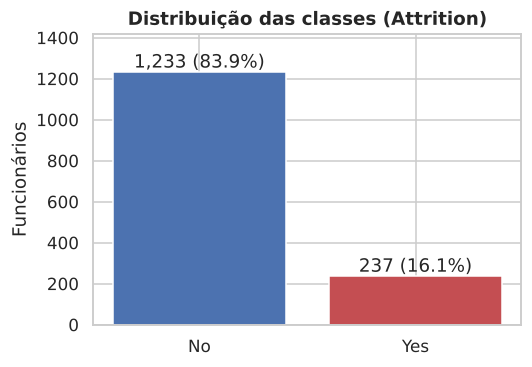

In [5]:
# use quantas células de código e texto forem necessárias
ALVO = "Attrition"
cols_num = df.select_dtypes("number").columns.tolist()
cols_cat = df.select_dtypes(exclude="number").columns.tolist()
cols_cat_sem_alvo = [c for c in cols_cat if c != ALVO]

print(f"Número de instâncias: {df.shape[0]}")
print(f"Número de atributos (sem o alvo): {df.shape[1] - 1}  ->  {len(cols_num)} numéricos e {len(cols_cat_sem_alvo)} categóricos")
print(f"Número de classes: {df[ALVO].nunique()}  {sorted(df[ALVO].unique())}")

dist = df[ALVO].value_counts().rename("instâncias").to_frame()
dist["proporção (%)"] = (dist["instâncias"] / len(df) * 100).round(2)
display(dist)
print(f"Razão de desbalanceamento (maioria/minoria): {dist['instâncias'].max() / dist['instâncias'].min():.2f} : 1")

fig, ax = plt.subplots(figsize=(5, 3.5))
barras = ax.bar(dist.index.astype(str), dist["instâncias"], color=["#4C72B0", "#C44E52"])
ax.bar_label(barras, labels=[f"{v:,} ({p:.1f}%)" for v, p in zip(dist["instâncias"], dist["proporção (%)"])])
ax.set_title("Distribuição das classes (Attrition)")
ax.set_ylabel("Funcionários")
ax.set_ylim(0, dist["instâncias"].max() * 1.15)
plt.tight_layout()
plt.show()

In [6]:
# Estatísticas descritivas dos atributos numéricos e categóricos
display(df[cols_num].describe().T.round(2))
display(df[cols_cat].describe().T)

,count,mean,std,min,25%,50%,75%,max
Age,1470.0,36.92,9.14,18.00,30.00,36.00,43.00,60.00
DailyRate,1470.0,802.49,403.51,102.00,465.00,802.00,1157.00,1499.00
DistanceFromHome,1470.0,9.19,8.11,1.00,2.00,7.00,14.00,29.00
Education,1470.0,2.91,1.02,1.00,2.00,3.00,4.00,5.00
EnvironmentSatisfaction,1470.0,2.72,1.09,1.00,2.00,3.00,4.00,4.00
HourlyRate,1470.0,65.89,20.33,30.00,48.00,66.00,83.75,100.00
JobInvolvement,1470.0,2.73,0.71,1.00,2.00,3.00,3.00,4.00
JobLevel,1470.0,2.06,1.11,1.00,1.00,2.00,3.00,5.00
JobSatisfaction,1470.0,2.73,1.10,1.00,2.00,3.00,4.00,4.00
MonthlyIncome,1470.0,6502.93,4707.96,1009.00,2911.00,4919.00,8379.00,19999.00


,count,unique,top,freq
Attrition,1470,2,No,1233
BusinessTravel,1470,3,Travel_Rarely,1043
Department,1470,3,Research & Development,961
EducationField,1470,6,Life Sciences,606
Gender,1470,2,Male,882
JobRole,1470,9,Sales Executive,326
MaritalStatus,1470,3,Married,673
OverTime,1470,2,No,1054
AgeGroup,1470,4,30-39,622


**Resumo:** a base tem **1.470 instâncias** e **38 atributos preditivos** (30 numéricos, incluindo 9 ordinais codificados como inteiros, e 8 categóricos), mais o alvo binário `Attrition`. São **2 classes** e o problema é **desbalanceado**: apenas cerca de 16% dos funcionários saíram (237 contra 1.233), uma razão próxima de 5 para 1. Isso terá consequências no pipeline: a divisão treino/teste precisa ser **estratificada** e a acurácia sozinha não é uma boa métrica (um modelo que sempre prevê "No" acertaria ~84%).

# Análise Univariada

Nesta seção, você deve realizar a análise univariada em pelo menos **20 variáveis**.

Ao final, você deve descrever as principais variáveis de interesse, que deverão ser consideradas nas próximas seções do relatório.
A definição de cada variável escolhida deve ser justificada; portanto, seleções arbitrárias **não** são aceitas neste ponto.

Para cada variável plotada, certifique-se de determinar:
1. A distribuição dos dados (Gaussiana, binomial, exponencial, etc.);
2. Assimetria (*skewness*);
3. Curtose (*kurtosis*);
4. Média, desvio padrão e o que representam no contexto do conjunto de dados.

Certifique-se de que cada variável seja **plotada corretamente** de acordo com seu tipo. Por exemplo, gráficos de dispersão não devem ser usados para dados categóricos, e assim por diante.

### Como as variáveis foram escolhidas (sem arbitrariedade)

A seleção combina dois critérios:

1. **Evidência nos dados:** calculamos a *informação mútua* entre cada atributo e o alvo `Attrition` (quanto saber o atributo reduz a incerteza sobre a saída). Valores próximos de zero indicam pouca relação. O cálculo é feito com `pandas` e `numpy`: as variáveis numéricas com mais de 10 valores distintos são divididas em 5 faixas (quintis) e comparamos a tabela de contagem observada com a esperada caso o atributo e a saída fossem independentes.
2. **Cobertura dos temas de negócio** que a literatura de rotatividade aponta: *remuneração, tempo de carreira, mobilidade, satisfação, carga de trabalho e perfil/estrutura da empresa*. Uma variável pode ser escolhida mesmo com informação mútua baixa se ela é necessária para testar uma hipótese (por exemplo, `DailyRate`, para checar se a taxa diária reflete a renda).

O ranking abaixo fundamenta a escolha; a justificativa por variável está no texto "Pergunta/Hipótese" de cada análise.

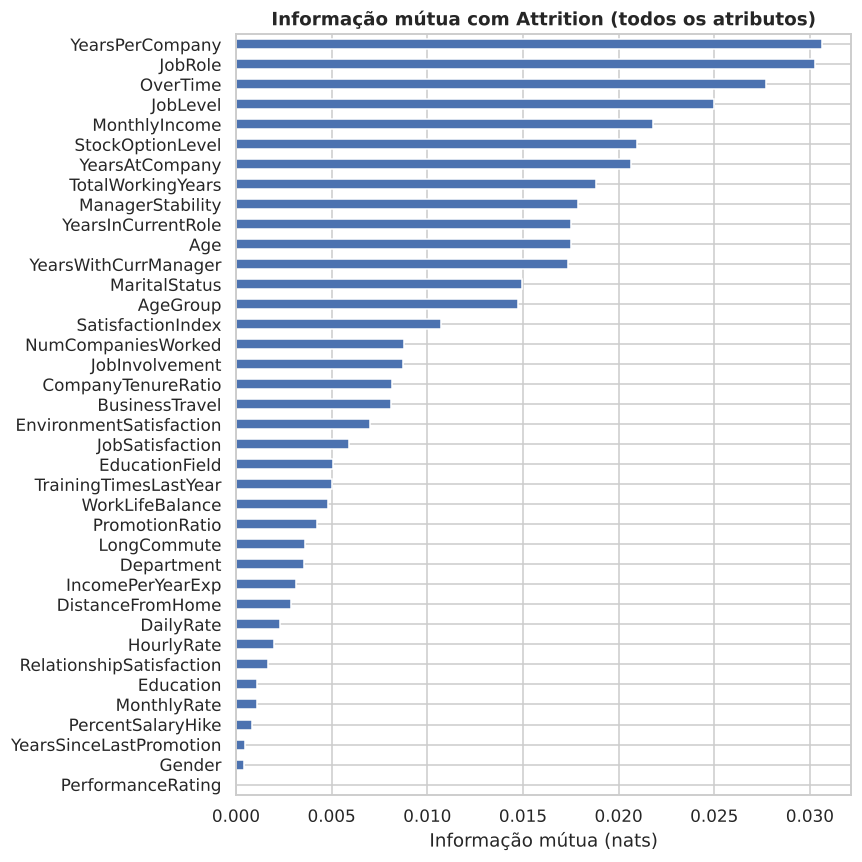

In [7]:
# Informação mútua entre cada atributo e o alvo (apenas para fundamentar a escolha das variáveis).
# Calculada "na mão" com pandas: variáveis numéricas com mais de 10 valores distintos são divididas em 5 faixas (quintis);
# depois comparamos a tabela de contagem observada (atributo x alvo) com a esperada se fossem independentes.
y_bin = (df[ALVO] == "Yes").astype(int)

def informacao_mutua(x, y, faixas=5):
    if pd.api.types.is_numeric_dtype(x) and x.nunique() > 10:
        x = pd.qcut(x, faixas, duplicates="drop")
    p = pd.crosstab(x, y, normalize=True)                           # probabilidade conjunta P(x, y)
    esperado = np.outer(p.sum(axis=1), p.sum(axis=0))                # P(x) * P(y), caso fossem independentes
    mascara = p.values > 0
    return float((p.values[mascara] * np.log(p.values[mascara] / esperado[mascara])).sum())

mi = pd.Series({c: informacao_mutua(df[c], y_bin) for c in df.columns if c != ALVO}).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(8, 8))
mi.sort_values().plot(kind="barh", ax=ax, color="#4C72B0")
ax.set_title("Informação mútua com Attrition (todos os atributos)")
ax.set_xlabel("Informação mútua (nats)")
plt.tight_layout()
plt.show()

In [8]:
# Variáveis escolhidas para a análise univariada (e únicas permitidas na análise multivariada)
VARS_NUM = ["Age", "MonthlyIncome", "DailyRate", "DistanceFromHome", "TotalWorkingYears", "YearsAtCompany", "YearsInCurrentRole", "YearsSinceLastPromotion", "YearsWithCurrManager", "PercentSalaryHike", "NumCompaniesWorked", "TrainingTimesLastYear", "IncomePerYearExp", "SatisfactionIndex"]
VARS_ORD = ["JobLevel", "StockOptionLevel", "JobSatisfaction", "EnvironmentSatisfaction", "WorkLifeBalance", "JobInvolvement"]
VARS_CAT = ["Attrition", "OverTime", "BusinessTravel", "Department", "MaritalStatus", "JobRole", "AgeGroup"]
VARS_NUM_ORD = VARS_NUM + VARS_ORD
print(f"{len(VARS_NUM)} numéricas + {len(VARS_ORD)} ordinais + {len(VARS_CAT)} categóricas = "
      f"{len(VARS_NUM) + len(VARS_ORD) + len(VARS_CAT)} variáveis")

14 numéricas + 6 ordinais + 7 categóricas = 27 variáveis


| Tema | Variáveis | Por que entram |
|---|---|---|
| Alvo | `Attrition` | Variável que queremos entender. |
| Remuneração | `MonthlyIncome`, `DailyRate`, `PercentSalaryHike`, `IncomePerYearExp`, `StockOptionLevel` | `MonthlyIncome` está entre as cinco maiores informações mútuas. `DailyRate` entra para testar se as "taxas" refletem a renda real (informação mútua quase nula). `PercentSalaryHike` testa se o reajuste importa. `IncomePerYearExp` é uma variável criada para medir a renda ajustada à experiência. |
| Perfil / carreira | `Age`, `AgeGroup`, `TotalWorkingYears`, `JobLevel`, `JobRole`, `MaritalStatus` | `JobRole`, `JobLevel`, `TotalWorkingYears` e `Age` estão entre os maiores valores de informação mútua. |
| Tempo e mobilidade | `YearsAtCompany`, `YearsInCurrentRole`, `YearsSinceLastPromotion`, `YearsWithCurrManager`, `NumCompaniesWorked`, `TrainingTimesLastYear` | Medem estabilidade, estagnação e mobilidade. `YearsAtCompany`, `YearsInCurrentRole` e `YearsWithCurrManager` têm informação mútua entre as maiores; `NumCompaniesWorked` tem valor intermediário (e uma relação não monotônica com a saída, vista na análise multivariada). |
| Satisfação e carga | `JobSatisfaction`, `EnvironmentSatisfaction`, `WorkLifeBalance`, `JobInvolvement`, `SatisfactionIndex`, `OverTime`, `BusinessTravel`, `DistanceFromHome` | Tema central da literatura de rotatividade. `OverTime` está entre as maiores informações mútuas; `WorkLifeBalance` e `DistanceFromHome` têm informação mútua muito baixa e servem para testar se a intuição "mais distância/pior equilíbrio, mais saídas" resiste aos dados. |
| Estrutura | `Department` | Permite comparar áreas e separar o efeito do departamento do efeito da função (`JobRole`). |

Ficaram de fora, de propósito: `HourlyRate` e `MonthlyRate` (redundantes com `DailyRate`, mesmo tipo de "taxa"), `PerformanceRating` (apenas 2 valores observados, 3 e 4), `Education`/`EducationField`/`Gender`/`RelationshipSatisfaction` (informação mútua baixa e sem hipótese de negócio específica) e os demais atributos derivados, que são combinações das variáveis já escolhidas.

In [9]:
# ---------- Funções auxiliares da análise univariada ----------
RESUMO_UNI = []          # tabela-resumo preenchida a cada variável analisada
VARS_UNIVARIADAS = []    # variáveis já analisadas (usada para validar a análise multivariada)


def _registrar(col, tipo, media, desvio, assimetria, curtose, distribuicao):
    VARS_UNIVARIADAS.append(col)
    RESUMO_UNI.append({"Variável": col, "Tipo": tipo, "Média": media, "Desvio padrão": desvio,
                       "Assimetria": assimetria, "Curtose": curtose, "Distribuição": distribuicao})


def descrever_assimetria(s):
    mag = "aproximadamente simétrica" if abs(s) < 0.5 else ("moderadamente assimétrica" if abs(s) < 1 else "fortemente assimétrica")
    lado = "" if abs(s) < 0.5 else (" à direita (cauda longa de valores altos)" if s > 0 else " à esquerda (cauda longa de valores baixos)")
    return mag + lado


def descrever_curtose(k):
    if k > 0.5:
        return "leptocúrtica (caudas pesadas e pico mais agudo que a normal)"
    if k < -0.5:
        return "platicúrtica (caudas leves e distribuição mais achatada que a normal)"
    return "mesocúrtica (semelhante à normal)"


def ks_discreta(x, cdf):
    """Distância máxima entre a FDA empírica e a teórica nos pontos do suporte (versão para dados discretos)."""
    valores = np.arange(x.min(), x.max() + 1)
    emp = np.array([(x <= v).mean() for v in valores])
    return float(np.max(np.abs(emp - cdf(valores))))


def ajustar_distribuicoes(x):
    """Ajusta distribuições candidatas e ordena pela estatística de Kolmogorov-Smirnov (menor = melhor).
    Variáveis inteiras com poucos valores são tratadas como contagens (Poisson, geométrica...);
    as demais, como contínuas (normal, log-normal, exponencial, gama, uniforme)."""
    x = np.asarray(x, dtype=float)
    inteira = np.allclose(x, np.round(x)) and len(np.unique(x)) <= 20
    linhas = []
    if inteira:
        k = x - x.min()                                   # suporte deslocado para começar em 0
        mu, dp = k.mean(), k.std()
        candidatas = {
            "Poisson": lambda v: stats.poisson.cdf(v, mu),
            "Geométrica": lambda v: 1 - (1 - 1 / (mu + 1)) ** (v + 1),
            "Normal (arredondada)": lambda v: stats.norm.cdf(v + 0.5, mu, dp),
            "Uniforme discreta": lambda v: (v + 1) / (k.max() + 1),
        }
        for nome, cdf in candidatas.items():
            linhas.append((nome, ks_discreta(k, cdf)))
    else:
        positivo = x - x.min() + 1 if x.min() <= 0 else x     # log-normal e gama exigem valores > 0
        sufixo = " (deslocada)" if x.min() <= 0 else ""
        candidatas = {"Normal": (stats.norm, x), "Log-normal" + sufixo: (stats.lognorm, positivo),
                      "Exponencial": (stats.expon, x), "Gama" + sufixo: (stats.gamma, positivo),
                      "Uniforme": (stats.uniform, x)}
        for nome, (dist_, dados) in candidatas.items():
            try:
                params = dist_.fit(dados, floc=0) if dist_ in (stats.lognorm, stats.gamma) else dist_.fit(dados)
                linhas.append((nome, stats.kstest(dados, dist_.cdf, args=params).statistic))
            except Exception:
                continue
    return pd.DataFrame(linhas, columns=["Distribuição", "KS"]).sort_values("KS").reset_index(drop=True)


def contar_outliers(x):
    q1, q3 = x.quantile([0.25, 0.75])
    iqr = q3 - q1
    return int(((x < q1 - 1.5 * iqr) | (x > q3 + 1.5 * iqr)).sum())


def analisar_numerica(col, rotulo=None):
    """Histograma + KDE + boxplot, e estatísticas: média, desvio, assimetria, curtose e ajuste de distribuição."""
    x = df[col].dropna()
    rotulo = rotulo or col
    media, mediana, dp = x.mean(), x.median(), x.std()
    assim, curt = stats.skew(x), stats.kurtosis(x)           # curtose em excesso (normal = 0)
    p_norm = stats.normaltest(x).pvalue
    ajustes = ajustar_distribuicoes(x)
    melhor = ajustes.iloc[0]
    fig, ax = plt.subplots(1, 3, figsize=(15, 3.8), gridspec_kw={"width_ratios": [3, 1.3, 1.8]})
    inteira = bool(np.allclose(x, np.round(x)))
    sns.histplot(x, kde=x.nunique() > 20, discrete=inteira, bins="auto" if not inteira else 10, ax=ax[0], color="#4C72B0")
    ax[0].axvline(media, color="crimson", ls="--", label=f"média = {media:,.2f}")
    ax[0].axvline(mediana, color="darkgreen", ls=":", label=f"mediana = {mediana:,.2f}")
    ax[0].legend()
    ax[0].set_title(f"Distribuição de {col}")
    ax[0].set_xlabel(rotulo)
    ax[0].set_ylabel("Frequência")
    sns.boxplot(x=x, ax=ax[1], color="#9ecae1")
    ax[1].set_title("Boxplot")
    ax[1].set_xlabel(rotulo)
    stats.probplot(x, dist="norm", plot=ax[2])
    ax[2].get_lines()[0].set(markersize=3, color="#4C72B0")
    ax[2].set_title("Q-Q plot (normal)")
    ax[2].set_xlabel("Quantis teóricos")
    ax[2].set_ylabel("Quantis observados")
    plt.tight_layout()
    plt.show()
    print(f"Média = {media:,.2f} | mediana = {mediana:,.2f} | desvio padrão = {dp:,.2f} | "
          f"mín = {x.min():,.2f} | máx = {x.max():,.2f}")
    print(f"Assimetria (skewness) = {assim:.2f} -> distribuição {descrever_assimetria(assim)}")
    print(f"Curtose em excesso (kurtosis) = {curt:.2f} -> {descrever_curtose(curt)}")
    print(f"Teste de normalidade (D'Agostino): p = {p_norm:.2e} -> "
          f"{'não rejeita' if p_norm > 0.05 else 'rejeita'} a normalidade (5%)")
    print("Melhor ajuste (Kolmogorov-Smirnov; apenas indicativo): "
          + " | ".join(f"{r['Distribuição']} (KS={r['KS']:.3f})" for _, r in ajustes.head(3).iterrows()))
    print(f"Outliers pela regra do IQR: {contar_outliers(x)} de {len(x)}")
    rotulo_dist = "Normal" if p_norm > 0.05 else f"{melhor['Distribuição']} (KS={melhor['KS']:.2f})"
    _registrar(col, "Numérica", media, dp, assim, curt, rotulo_dist)


def analisar_ordinal(col, rotulos=None):
    """Gráfico de barras (proporção por nível) para variáveis discretas ordinais."""
    x = df[col]
    cont = x.value_counts().sort_index()
    prop = cont / len(x)
    media, dp = x.mean(), x.std()
    assim, curt = stats.skew(x), stats.kurtosis(x)
    chi = stats.chisquare(cont.values)
    nomes = [f"{i}\n{rotulos[i]}" if rotulos else str(i) for i in cont.index]
    fig, ax = plt.subplots(figsize=(7, 3.6))
    barras = ax.bar(range(len(cont)), prop.values, color="#4C72B0")
    ax.bar_label(barras, labels=[f"{p:.1%}" for p in prop.values])
    ax.set_xticks(range(len(cont)))
    ax.set_xticklabels(nomes)
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
    ax.set_ylim(0, prop.max() * 1.15)
    ax.set_title(f"Distribuição de {col}")
    ax.set_ylabel("Proporção de funcionários")
    plt.tight_layout()
    plt.show()
    print(f"Moda = {x.mode().iloc[0]} | média = {media:.2f} | mediana = {x.median():.1f} | desvio padrão = {dp:.2f}")
    print(f"Assimetria (skewness) = {assim:.2f} -> distribuição {descrever_assimetria(assim)}")
    print(f"Curtose em excesso (kurtosis) = {curt:.2f} -> {descrever_curtose(curt)}")
    print(f"Qui-quadrado contra uniforme discreta: p = {chi.pvalue:.2e} -> "
          f"{'compatível' if chi.pvalue > 0.05 else 'incompatível'} com níveis equiprováveis")
    _registrar(col, "Ordinal", media, dp, assim, curt, "Discreta ordinal (multinomial)")


def analisar_categorica(col, rotulo=None, ordem=None):
    """Gráfico de barras para variáveis categóricas, com moda, proporções e entropia normalizada."""
    cont = df[col].value_counts()
    if ordem is not None:
        cont = cont.reindex(ordem)
    prop = cont / len(df)
    k = len(cont)
    entropia = stats.entropy(prop.values) / np.log(k)         # 1 = categorias perfeitamente equilibradas
    chi = stats.chisquare(cont.values)
    horizontal = k > 4
    fig, ax = plt.subplots(figsize=(8, 0.5 * k + 2) if horizontal else (6, 3.6))
    if horizontal:
        cont_plot = prop.iloc[::-1]
        barras = ax.barh(cont_plot.index.astype(str), cont_plot.values, color="#4C72B0")
        ax.bar_label(barras, labels=[f"{p:.1%}" for p in cont_plot.values], padding=3)
        ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
        ax.set_xlim(0, prop.max() * 1.15)
        ax.set_xlabel("Proporção de funcionários")
    else:
        barras = ax.bar(prop.index.astype(str), prop.values, color="#4C72B0")
        ax.bar_label(barras, labels=[f"{p:.1%}" for p in prop.values])
        ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
        ax.set_ylim(0, prop.max() * 1.15)
        ax.set_ylabel("Proporção de funcionários")
    ax.set_title(f"Distribuição de {col}")
    plt.tight_layout()
    plt.show()
    print(f"Nº de categorias = {k} | moda = {cont.idxmax()} ({prop.max():.1%}) | "
          f"entropia normalizada = {entropia:.2f} (1 = perfeitamente equilibrada)")
    print("Proporções: " + " | ".join(f"{i}: {p:.1%}" for i, p in prop.items()))
    print(f"Qui-quadrado contra categorias equiprováveis: p = {chi.pvalue:.2e}")
    dist_ = f"Bernoulli (p={prop.iloc[-1]:.2f})" if k == 2 else "Categórica (multinomial)"
    _registrar(col, "Categórica", np.nan, np.nan, np.nan, np.nan, dist_)


ROTULOS = {
    "JobSatisfaction": {1: "Baixa", 2: "Média", 3: "Alta", 4: "Muito alta"},
    "EnvironmentSatisfaction": {1: "Baixa", 2: "Média", 3: "Alta", 4: "Muito alta"},
    "WorkLifeBalance": {1: "Ruim", 2: "Bom", 3: "Melhor", 4: "Ótimo"},
    "JobInvolvement": {1: "Baixo", 2: "Médio", 3: "Alto", 4: "Muito alto"},
    "JobLevel": None,
    "StockOptionLevel": None,
}

#### `Age` (numérica)
**Pergunta:** Qual é a faixa etária predominante e como a idade se distribui?

**Hipótese:** A idade segue aproximadamente uma distribuição normal, centrada em torno dos 35-40 anos, pois a empresa recruta em várias faixas e o quadro é maduro.

**O que representa:** Idade do funcionário em anos completos.

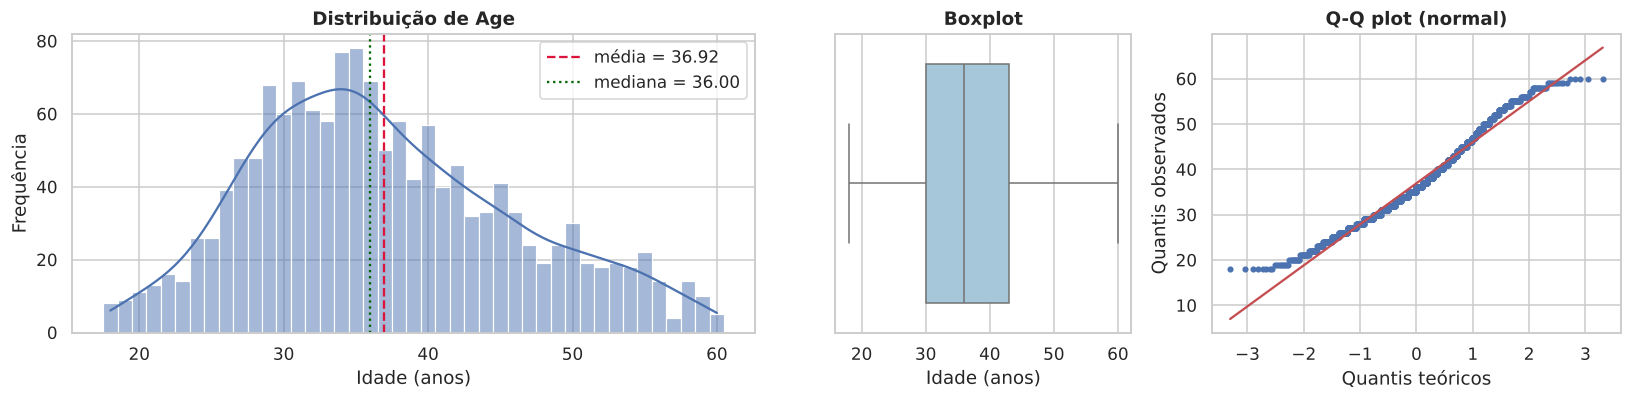

Média = 36.92 | mediana = 36.00 | desvio padrão = 9.14 | mín = 18.00 | máx = 60.00
Assimetria (skewness) = 0.41 -> distribuição aproximadamente simétrica
Curtose em excesso (kurtosis) = -0.41 -> mesocúrtica (semelhante à normal)
Teste de normalidade (D'Agostino): p = 1.33e-12 -> rejeita a normalidade (5%)
Melhor ajuste (Kolmogorov-Smirnov; apenas indicativo): Log-normal (KS=0.034) | Gama (KS=0.051) | Normal (KS=0.083)
Outliers pela regra do IQR: 0 de 1470


In [10]:
analisar_numerica("Age", "Idade (anos)")

**Discussão:** A idade média é de **36,9 anos** (desvio padrão 9,1; mediana 36), com valores entre 18 e 60. A assimetria é pequena (**0,41**, leve cauda à direita) e a curtose é **-0,41** (mesocúrtica, pouco mais achatada que a normal). O teste de D'Agostino rejeita a normalidade (p ≈ 1e-12), mas com n = 1.470 esse teste detecta desvios mínimos; o Q-Q plot mostra bom alinhamento no centro e desvios apenas nas pontas (truncadas em 18 e 60 anos). Na comparação por Kolmogorov-Smirnov, a log-normal/gama ajusta melhor que a normal. A hipótese se confirma em parte: o formato é de sino, mas levemente assimétrico, e cerca de 59% do quadro tem entre 30 e 45 anos. Não há outliers pela regra do IQR.

#### `MonthlyIncome` (numérica)
**Pergunta:** Como a renda mensal se distribui? Existem poucos salários muito altos puxando a média?

**Hipótese:** Distribuição assimétrica à direita (tipo log-normal): muitos salários baixos/médios e poucos salários altos de cargos de gestão.

**O que representa:** Salário mensal bruto do funcionário.

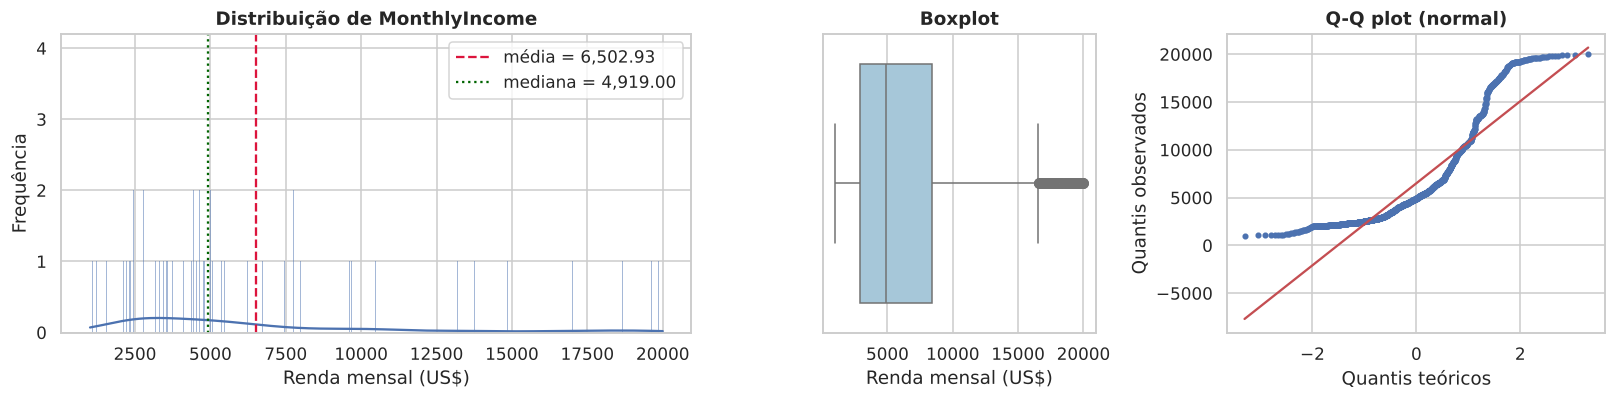

Média = 6,502.93 | mediana = 4,919.00 | desvio padrão = 4,707.96 | mín = 1,009.00 | máx = 19,999.00
Assimetria (skewness) = 1.37 -> distribuição fortemente assimétrica à direita (cauda longa de valores altos)
Curtose em excesso (kurtosis) = 1.00 -> leptocúrtica (caudas pesadas e pico mais agudo que a normal)
Teste de normalidade (D'Agostino): p = 4.98e-67 -> rejeita a normalidade (5%)
Melhor ajuste (Kolmogorov-Smirnov; apenas indicativo): Log-normal (KS=0.064) | Gama (KS=0.093) | Exponencial (KS=0.143)
Outliers pela regra do IQR: 114 de 1470


In [11]:
analisar_numerica("MonthlyIncome", "Renda mensal (US$)")

**Discussão:** A renda média é de **US$ 6.503**, bem acima da mediana de **US$ 4.919** (diferença de 32%), com desvio padrão de US$ 4.708. A assimetria é **1,37** (forte, à direita) e a curtose **1,00** (caudas pesadas). O melhor ajuste é a **log-normal** (KS = 0,064), o que confirma a hipótese: a maioria ganha pouco (51% recebe menos de US$ 5.000) e uma minoria de cargos altos (9% recebe mais de US$ 15.000) puxa a média para cima. Por isso a mediana representa melhor o funcionário típico, e testes não paramétricos são mais adequados. São 114 outliers (7,8%), tratados na seção de limpeza.

#### `DailyRate` (numérica)
**Pergunta:** A taxa diária tem uma estrutura própria (por exemplo, concentra-se em torno de algum valor) ou se espalha de forma indiscriminada?

**Hipótese:** Distribuição aproximadamente uniforme, sem estrutura, sugerindo que a variável tem pouco vínculo com características reais dos cargos (será testado na análise multivariada contra a renda mensal).

**O que representa:** Taxa diária ("daily rate") registrada na base. Não está documentado se é um valor de faturamento ou de remuneração.

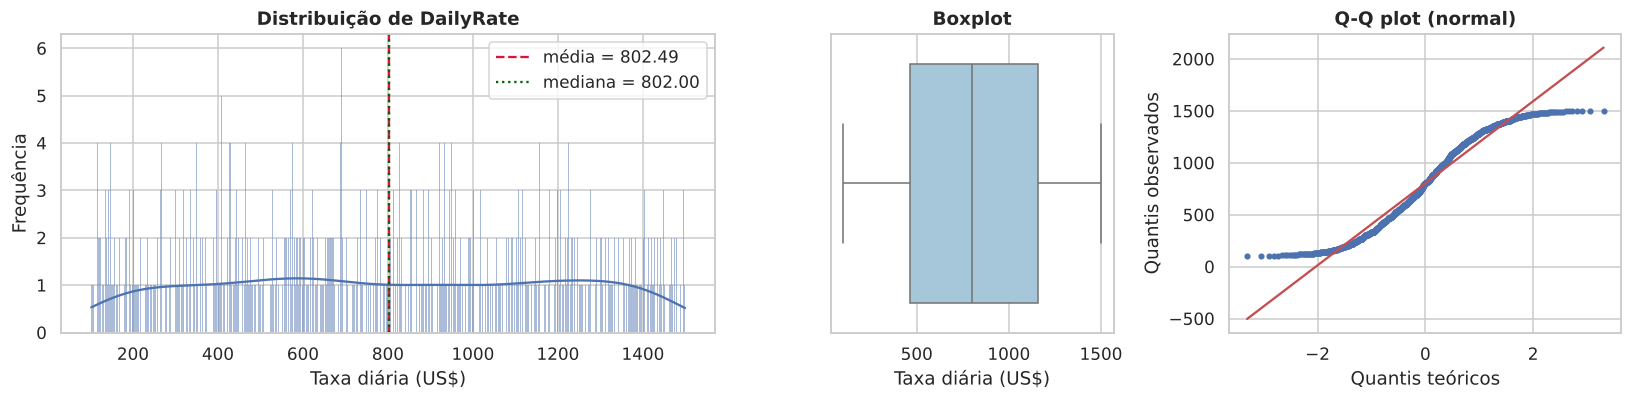

Média = 802.49 | mediana = 802.00 | desvio padrão = 403.51 | mín = 102.00 | máx = 1,499.00
Assimetria (skewness) = -0.00 -> distribuição aproximadamente simétrica
Curtose em excesso (kurtosis) = -1.20 -> platicúrtica (caudas leves e distribuição mais achatada que a normal)
Teste de normalidade (D'Agostino): p = 8.82e-257 -> rejeita a normalidade (5%)
Melhor ajuste (Kolmogorov-Smirnov; apenas indicativo): Uniforme (KS=0.016) | Normal (KS=0.071) | Gama (KS=0.087)
Outliers pela regra do IQR: 0 de 1470


In [12]:
analisar_numerica("DailyRate", "Taxa diária (US$)")

**Discussão:** A taxa diária tem média de US$ 802 (mediana 802), assimetria **0,00** e curtose em excesso de **-1,20**, valor idêntico ao da distribuição uniforme contínua teórica. O melhor ajuste é a **uniforme** (KS = 0,016), e o histograma é praticamente plano entre 102 e 1.499. A hipótese se confirma: não há nenhuma concentração, que seria esperada em uma grandeza ligada a cargos reais. Isso sugere uma variável gerada de forma aleatória (a base é fictícia), o que será testado na análise multivariada contra a renda mensal.

#### `DistanceFromHome` (numérica)
**Pergunta:** A maioria dos funcionários mora perto do trabalho? Há muita gente com deslocamentos longos?

**Hipótese:** Distribuição assimétrica à direita, com muitos funcionários morando a poucos quilômetros e uma cauda de deslocamentos longos.

**O que representa:** Distância entre a residência e o local de trabalho.

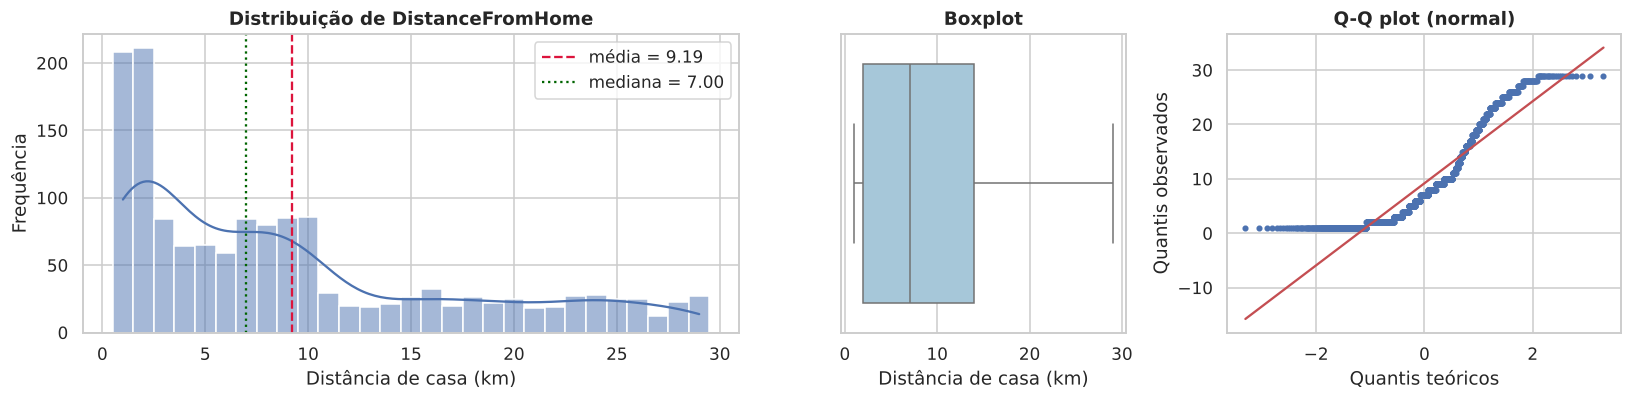

Média = 9.19 | mediana = 7.00 | desvio padrão = 8.11 | mín = 1.00 | máx = 29.00
Assimetria (skewness) = 0.96 -> distribuição moderadamente assimétrica à direita (cauda longa de valores altos)
Curtose em excesso (kurtosis) = -0.23 -> mesocúrtica (semelhante à normal)
Teste de normalidade (D'Agostino): p = 2.34e-37 -> rejeita a normalidade (5%)
Melhor ajuste (Kolmogorov-Smirnov; apenas indicativo): Log-normal (KS=0.124) | Gama (KS=0.126) | Normal (KS=0.158)
Outliers pela regra do IQR: 0 de 1470


In [13]:
analisar_numerica("DistanceFromHome", "Distância de casa (km)")

**Discussão:** A distância média é de **9,2 km** (mediana 7; desvio padrão 8,1), variando de 1 a 29 km. A assimetria é **0,96** (moderada, à direita) e a curtose **-0,23** (sem caudas pesadas). Cerca de 70% moram a até 10 km e 43% a até 5 km, enquanto 14% moram a mais de 20 km. A hipótese se confirma, com uma ressalva: a cauda é limitada (máximo de 29 km) e longa o bastante para que 30% do quadro tenha deslocamentos acima de 10 km, o que motivou a variável derivada `LongCommute`. Sem outliers pelo IQR.

#### `TotalWorkingYears` (numérica)
**Pergunta:** Qual é o perfil de experiência da força de trabalho?

**Hipótese:** Assimetria positiva: muitos profissionais no início/meio de carreira e poucos com mais de 25 anos de experiência.

**O que representa:** Total de anos de experiência profissional, incluindo outras empresas.

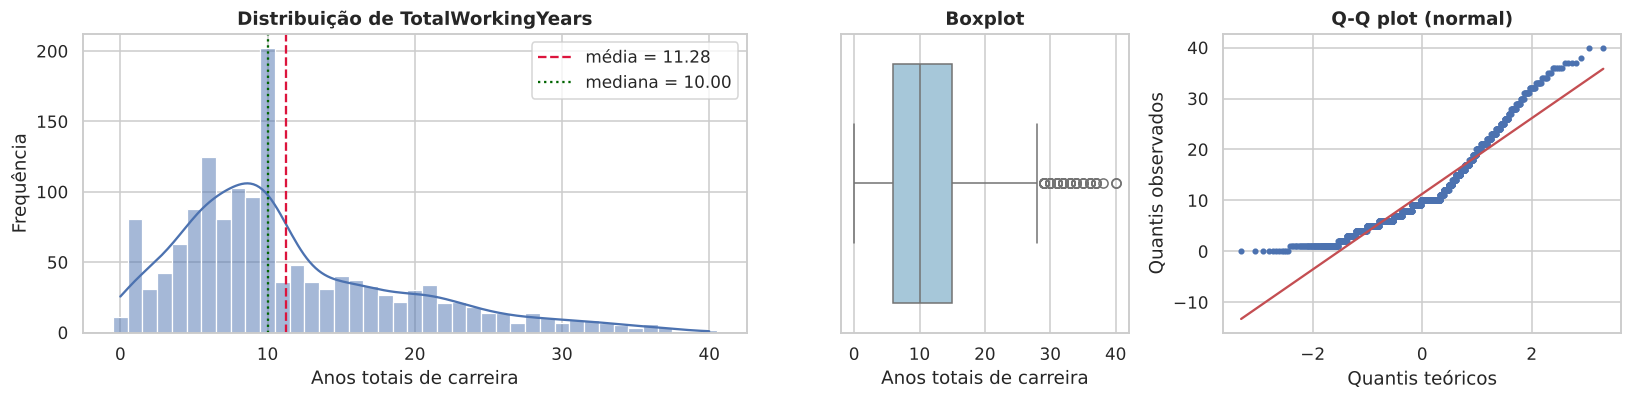

Média = 11.28 | mediana = 10.00 | desvio padrão = 7.78 | mín = 0.00 | máx = 40.00
Assimetria (skewness) = 1.12 -> distribuição fortemente assimétrica à direita (cauda longa de valores altos)
Curtose em excesso (kurtosis) = 0.91 -> leptocúrtica (caudas pesadas e pico mais agudo que a normal)
Teste de normalidade (D'Agostino): p = 1.76e-51 -> rejeita a normalidade (5%)
Melhor ajuste (Kolmogorov-Smirnov; apenas indicativo): Log-normal (deslocada) (KS=0.094) | Gama (deslocada) (KS=0.110) | Normal (KS=0.193)
Outliers pela regra do IQR: 63 de 1470


In [14]:
analisar_numerica("TotalWorkingYears", "Anos totais de carreira")

**Discussão:** A experiência média é de **11,3 anos** (mediana 10; desvio padrão 7,8), de 0 a 40 anos. Assimetria **1,12** (forte, à direita) e curtose **0,91** (caudas pesadas). O melhor ajuste é a log-normal deslocada (KS = 0,094). Cerca de 63% têm até 10 anos de carreira e apenas 7,6% têm 25 anos ou mais, confirmando a hipótese. Os 63 outliers (4,3%) são profissionais seniores com carreiras longas, valores plausíveis.

#### `YearsAtCompany` (numérica)
**Pergunta:** O quadro é majoritariamente novo ou antigo? A rotatividade deixa marcas no tempo de casa?

**Hipótese:** Forte assimetria à direita (tipo exponencial): grande parte do quadro tem poucos anos de casa, o que é típico de ambientes com rotatividade.

**O que representa:** Tempo de casa, em anos.

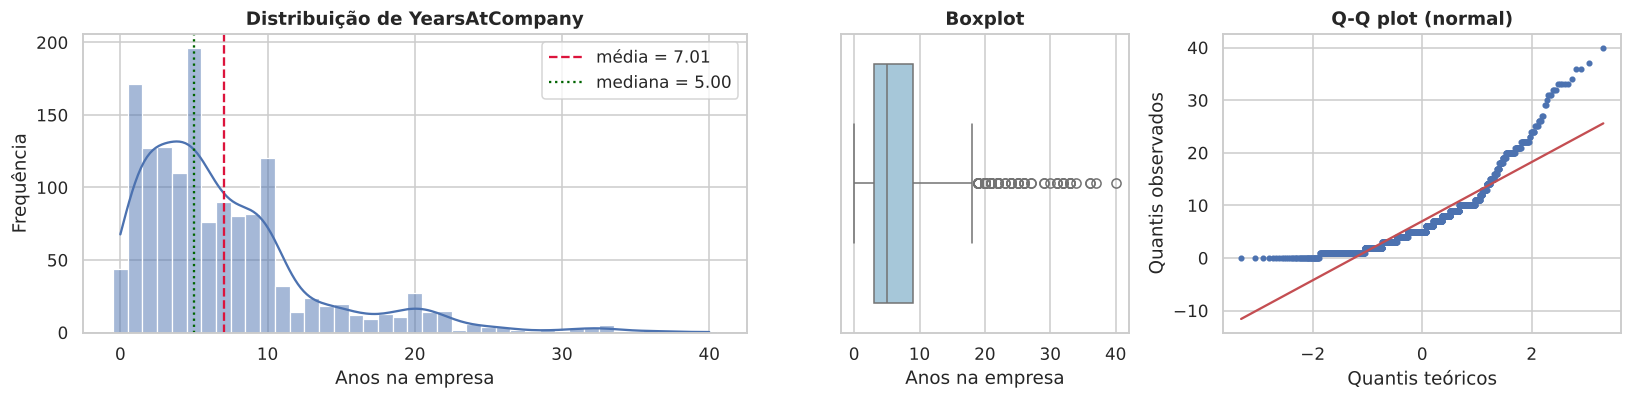

Média = 7.01 | mediana = 5.00 | desvio padrão = 6.13 | mín = 0.00 | máx = 40.00
Assimetria (skewness) = 1.76 -> distribuição fortemente assimétrica à direita (cauda longa de valores altos)
Curtose em excesso (kurtosis) = 3.92 -> leptocúrtica (caudas pesadas e pico mais agudo que a normal)
Teste de normalidade (D'Agostino): p = 3.00e-113 -> rejeita a normalidade (5%)
Melhor ajuste (Kolmogorov-Smirnov; apenas indicativo): Gama (deslocada) (KS=0.087) | Log-normal (deslocada) (KS=0.095) | Exponencial (KS=0.116)
Outliers pela regra do IQR: 104 de 1470


In [15]:
analisar_numerica("YearsAtCompany", "Anos na empresa")

**Discussão:** O tempo de casa médio é de **7,0 anos**, com mediana de **5** (desvio padrão 6,1), assimetria **1,76** e curtose **3,92**, a mais pesada entre as variáveis numéricas. Metade do quadro (52,8%) tem até 5 anos de casa, 23% tem até 2 anos e só 6,3% tem 20 anos ou mais. Os melhores ajustes são gama deslocada (KS = 0,087) e exponencial (KS = 0,116), compatíveis com a hipótese de uma massa de pessoas recentes e cauda longa de veteranos. Os 104 outliers (7,1%) são esses veteranos.

#### `YearsInCurrentRole` (numérica)
**Pergunta:** Quanto tempo as pessoas permanecem no mesmo cargo? Existe algum padrão além da simples assimetria?

**Hipótese:** Assimetria à direita, possivelmente com mais de um "pico" (ex.: logo após a entrada e depois de alguns anos), refletindo ciclos de promoção ou troca de função.

**O que representa:** Anos que o funcionário está no cargo atual.

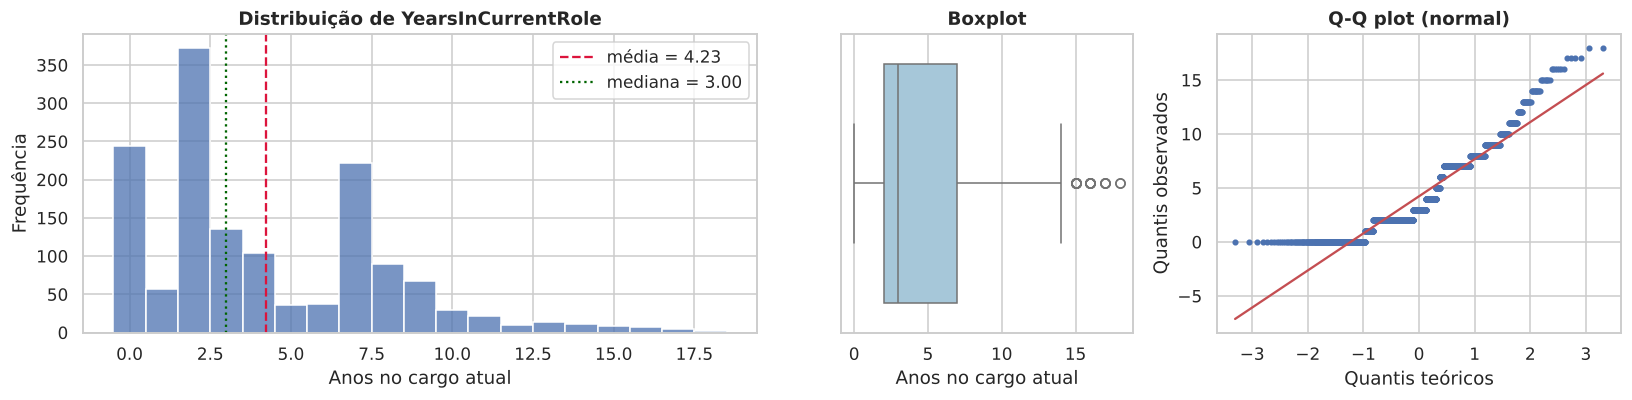

Média = 4.23 | mediana = 3.00 | desvio padrão = 3.62 | mín = 0.00 | máx = 18.00
Assimetria (skewness) = 0.92 -> distribuição moderadamente assimétrica à direita (cauda longa de valores altos)
Curtose em excesso (kurtosis) = 0.47 -> mesocúrtica (semelhante à normal)
Teste de normalidade (D'Agostino): p = 2.36e-36 -> rejeita a normalidade (5%)
Melhor ajuste (Kolmogorov-Smirnov; apenas indicativo): Geométrica (KS=0.141) | Normal (arredondada) (KS=0.141) | Poisson (KS=0.251)
Outliers pela regra do IQR: 21 de 1470


In [16]:
analisar_numerica("YearsInCurrentRole", "Anos no cargo atual")

**Discussão:** A média é de **4,2 anos** no cargo atual (mediana 3; desvio padrão 3,6), assimetria **0,92** e curtose **0,47**. O histograma mostra o comportamento que a hipótese previa: **três picos**, em 0 (16,6%), em 2 anos (25,3%) e em 7 anos (15,1%), em vez de um decaimento suave. Esses padrões sugerem ciclos de troca de função (logo após a entrada, aos 2 anos e aos 7 anos) e explicam por que nenhuma distribuição teórica simples ajusta bem (a geométrica e a normal empatam, KS = 0,141). Há 21 outliers (1,4%), todos acima de 14 anos no mesmo cargo.

#### `YearsSinceLastPromotion` (numérica)
**Pergunta:** A maioria dos funcionários foi promovida recentemente? A cauda de pessoas "estagnadas" é longa?

**Hipótese:** Distribuição concentrada em valores baixos (0-2) com cauda longa à direita, semelhante a uma exponencial/geométrica.

**O que representa:** Anos desde a última promoção (0 = promovido no último ano ou nunca promovido).

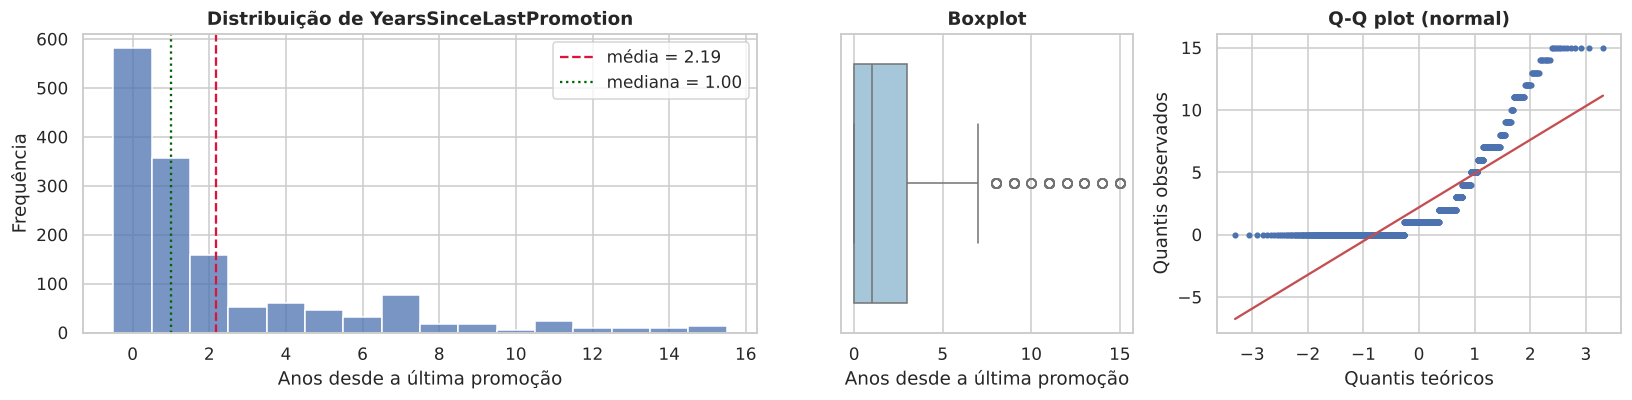

Média = 2.19 | mediana = 1.00 | desvio padrão = 3.22 | mín = 0.00 | máx = 15.00
Assimetria (skewness) = 1.98 -> distribuição fortemente assimétrica à direita (cauda longa de valores altos)
Curtose em excesso (kurtosis) = 3.60 -> leptocúrtica (caudas pesadas e pico mais agudo que a normal)
Teste de normalidade (D'Agostino): p = 2.88e-123 -> rejeita a normalidade (5%)
Melhor ajuste (Kolmogorov-Smirnov; apenas indicativo): Geométrica (KS=0.109) | Normal (arredondada) (KS=0.223) | Poisson (KS=0.283)
Outliers pela regra do IQR: 107 de 1470


In [17]:
analisar_numerica("YearsSinceLastPromotion", "Anos desde a última promoção")

**Discussão:** A média é de **2,2 anos** desde a última promoção, com mediana de apenas **1** (desvio padrão 3,2), assimetria **1,98** e curtose **3,60**. Destaca-se pela concentração em valores baixos: 74,6% foram promovidos há até 2 anos (39,5% com valor 0), mas há uma cauda longa, com 12,4% sem promoção há 7 anos ou mais. A geométrica é a melhor distribuição de contagem (KS = 0,109), confirmando a hipótese. Os 107 outliers (7,3%) são esses funcionários "estagnados", informação de negócio relevante, e por isso foram mantidos.

#### `YearsWithCurrManager` (numérica)
**Pergunta:** Qual a estabilidade da relação com os gestores?

**Hipótese:** Distribuição parecida com a de anos no cargo atual (assimétrica à direita), pois gestor e cargo tendem a mudar juntos.

**O que representa:** Anos de trabalho sob o gestor atual.

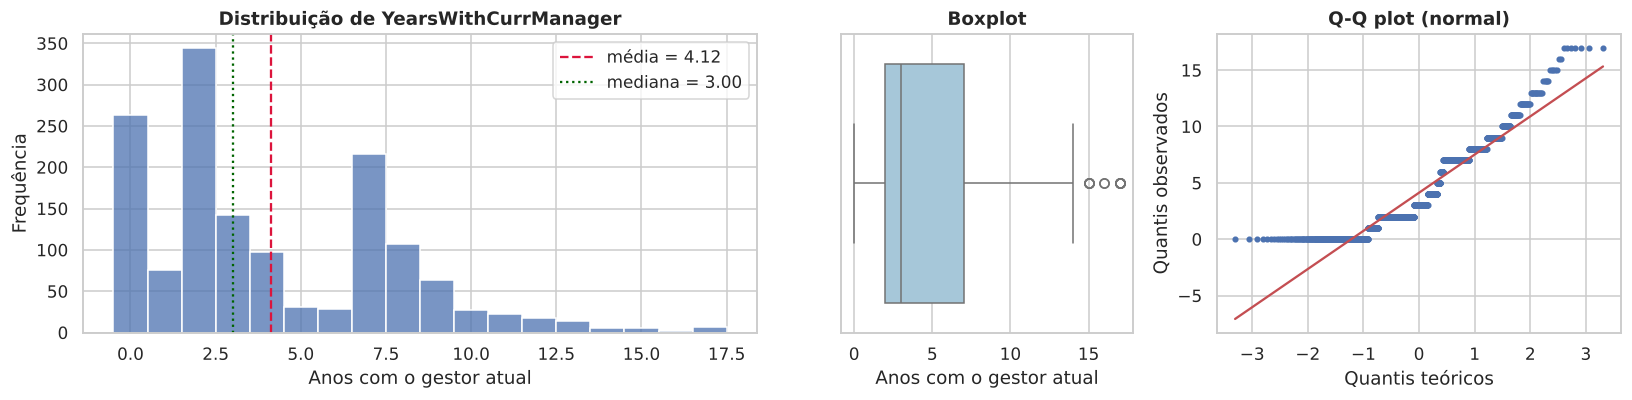

Média = 4.12 | mediana = 3.00 | desvio padrão = 3.57 | mín = 0.00 | máx = 17.00
Assimetria (skewness) = 0.83 -> distribuição moderadamente assimétrica à direita (cauda longa de valores altos)
Curtose em excesso (kurtosis) = 0.17 -> mesocúrtica (semelhante à normal)
Teste de normalidade (D'Agostino): p = 6.71e-30 -> rejeita a normalidade (5%)
Melhor ajuste (Kolmogorov-Smirnov; apenas indicativo): Geométrica (KS=0.122) | Normal (arredondada) (KS=0.140) | Poisson (KS=0.244)
Outliers pela regra do IQR: 14 de 1470


In [18]:
analisar_numerica("YearsWithCurrManager", "Anos com o gestor atual")

**Discussão:** A média é de **4,1 anos** com o gestor atual (mediana 3; desvio padrão 3,6), assimetria **0,83** e curtose **0,17**. A distribuição é parecida com a de anos no cargo atual, inclusive nos picos em 0 (17,9%), 2 (23,4%) e 7 anos (14,7%), o que confirma a hipótese de que gestor e cargo mudam juntos (a correlação entre as duas será confirmada na análise multivariada). Melhor ajuste: geométrica (KS = 0,122). Apenas 14 outliers (1,0%).

#### `PercentSalaryHike` (numérica)
**Pergunta:** Os reajustes variam muito entre funcionários ou são concentrados numa faixa estreita?

**Hipótese:** Variável limitada a uma faixa estreita (cerca de 11 a 25%), assimétrica à direita, com maior concentração nos reajustes menores.

**O que representa:** Percentual de aumento salarial no último reajuste.

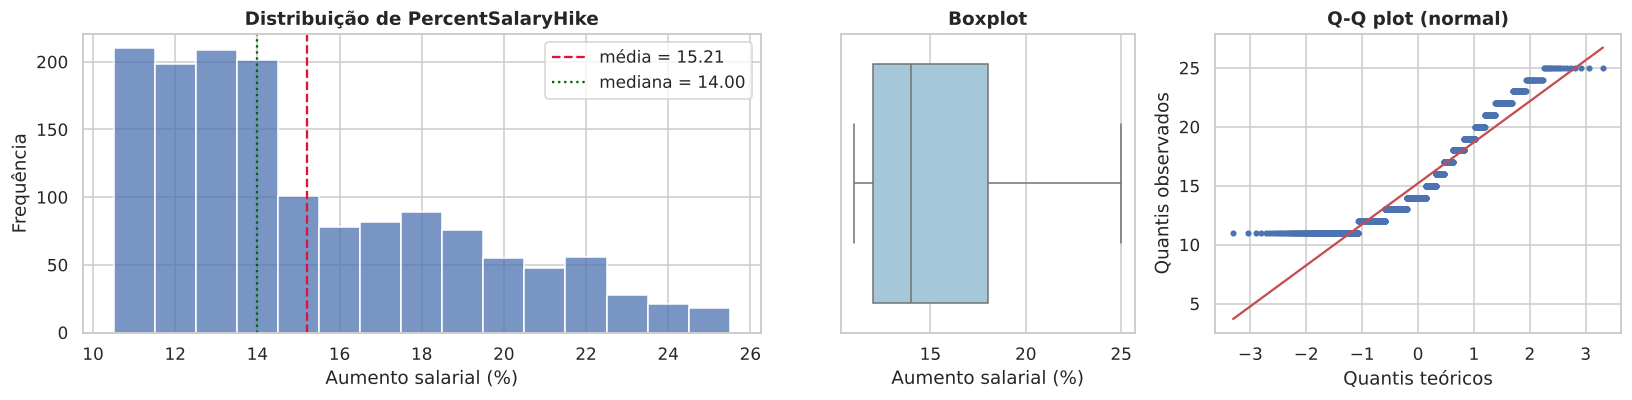

Média = 15.21 | mediana = 14.00 | desvio padrão = 3.66 | mín = 11.00 | máx = 25.00
Assimetria (skewness) = 0.82 -> distribuição moderadamente assimétrica à direita (cauda longa de valores altos)
Curtose em excesso (kurtosis) = -0.30 -> mesocúrtica (semelhante à normal)
Teste de normalidade (D'Agostino): p = 1.80e-30 -> rejeita a normalidade (5%)
Melhor ajuste (Kolmogorov-Smirnov; apenas indicativo): Geométrica (KS=0.070) | Normal (arredondada) (KS=0.133) | Poisson (KS=0.211)
Outliers pela regra do IQR: 0 de 1470


In [19]:
analisar_numerica("PercentSalaryHike", "Aumento salarial (%)")

**Discussão:** O aumento médio é de **15,2%** (mediana 14; desvio padrão 3,7), entre 11% e 25%, com assimetria **0,82** e curtose **-0,30**. A faixa é estreita e concentrada nos reajustes menores: 55,6% receberam até 14%, e 15,4% receberam 20% ou mais. A distribuição de contagem que melhor se ajusta é a geométrica, aplicada à diferença em relação ao mínimo (KS = 0,070). A hipótese se confirma. Não há outliers pelo IQR.

#### `NumCompaniesWorked` (numérica)
**Pergunta:** Quão "móvel" é o perfil do quadro? A maioria é fiel a poucas empresas?

**Hipótese:** Distribuição tipo geométrica/Poisson assimétrica: maior parte com 0-2 empresas anteriores e poucos "saltadores" com 6 ou mais.

**O que representa:** Número de empresas em que o funcionário trabalhou antes.

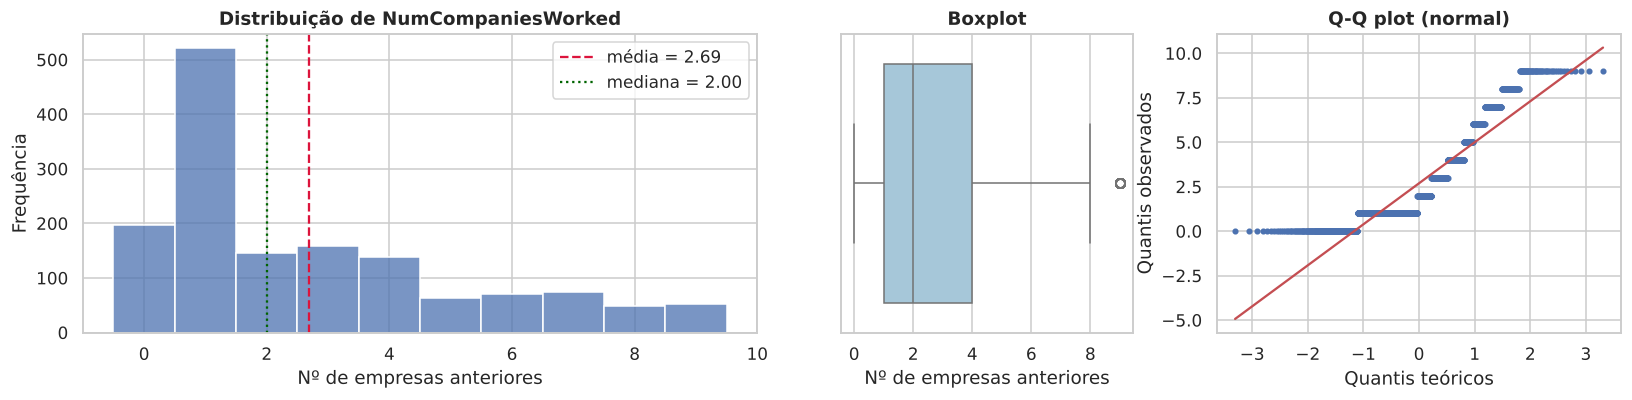

Média = 2.69 | mediana = 2.00 | desvio padrão = 2.50 | mín = 0.00 | máx = 9.00
Assimetria (skewness) = 1.03 -> distribuição fortemente assimétrica à direita (cauda longa de valores altos)
Curtose em excesso (kurtosis) = 0.01 -> mesocúrtica (semelhante à normal)
Teste de normalidade (D'Agostino): p = 1.77e-40 -> rejeita a normalidade (5%)
Melhor ajuste (Kolmogorov-Smirnov; apenas indicativo): Geométrica (KS=0.137) | Normal (arredondada) (KS=0.172) | Poisson (KS=0.239)
Outliers pela regra do IQR: 52 de 1470


In [20]:
analisar_numerica("NumCompaniesWorked", "Nº de empresas anteriores")

**Discussão:** A média é de **2,7 empresas anteriores** (mediana 2; desvio padrão 2,5), de 0 a 9, assimetria **1,03** e curtose **0,01**. O valor mais comum é 1 (35,4%) e 58,8% do quadro passou por no máximo 2 empresas; porém 16,7% passou por 6 ou mais, um grupo maior do que o "poucos" previsto na hipótese. O melhor ajuste é a geométrica (KS = 0,137), que captura a queda a partir de 1. O valor 0 (13,4%) é menor que o valor 1, o que indica que a distribuição não decai monotonicamente. Os 52 outliers (3,5%) correspondem aos que trabalharam em 9 empresas.

#### `TrainingTimesLastYear` (numérica)
**Pergunta:** A empresa investe em treinamento de forma homogênea?

**Hipótese:** Distribuição discreta aproximadamente simétrica em torno de 2-3 treinamentos (tipo Poisson).

**O que representa:** Quantidade de treinamentos realizados no último ano.

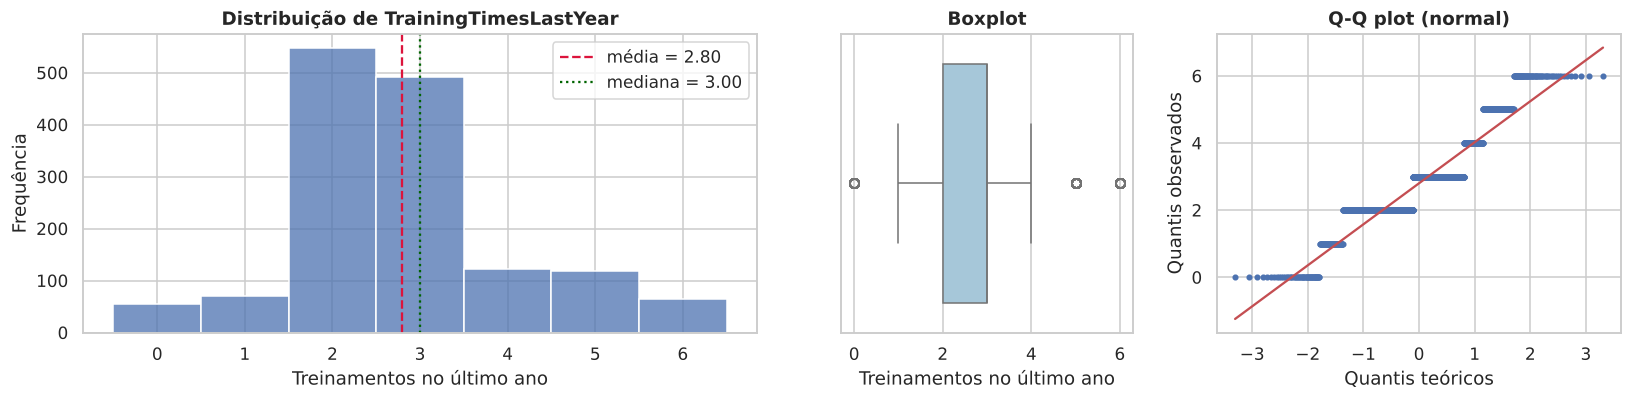

Média = 2.80 | mediana = 3.00 | desvio padrão = 1.29 | mín = 0.00 | máx = 6.00
Assimetria (skewness) = 0.55 -> distribuição moderadamente assimétrica à direita (cauda longa de valores altos)
Curtose em excesso (kurtosis) = 0.49 -> mesocúrtica (semelhante à normal)
Teste de normalidade (D'Agostino): p = 2.19e-17 -> rejeita a normalidade (5%)
Melhor ajuste (Kolmogorov-Smirnov; apenas indicativo): Normal (arredondada) (KS=0.084) | Poisson (KS=0.146) | Uniforme discreta (KS=0.220)
Outliers pela regra do IQR: 238 de 1470


In [21]:
analisar_numerica("TrainingTimesLastYear", "Treinamentos no último ano")

**Discussão:** A média é de **2,8 treinamentos** (mediana 3; desvio padrão 1,3), de 0 a 6, com assimetria **0,55** e curtose **0,49**. Os valores 2 e 3 concentram 70,6% do quadro, e valores extremos (0 ou 6) somam 8,1%, o que confirma a hipótese de investimento homogêneo. O melhor ajuste é a normal arredondada (KS = 0,084), melhor que a de Poisson. Os 238 "outliers" (16,2%) pelo IQR são apenas os valores 0, 5 e 6, que são perfeitamente plausíveis; a regra do IQR é pouco adequada a variáveis discretas com poucos valores.

#### `IncomePerYearExp` (numérica)
**Pergunta:** Como a remuneração se distribui depois de descontar a experiência? Há quem ganhe muito para pouca experiência?

**Hipótese:** Assimetria positiva, com uma cauda de pessoas que ganham muito para o tempo de carreira (profissionais jovens em cargos altos) e uma massa concentrada em valores moderados.

**O que representa:** Variável criada: MonthlyIncome / (TotalWorkingYears + 1). Mede quanto o salário "vale" por ano de carreira.

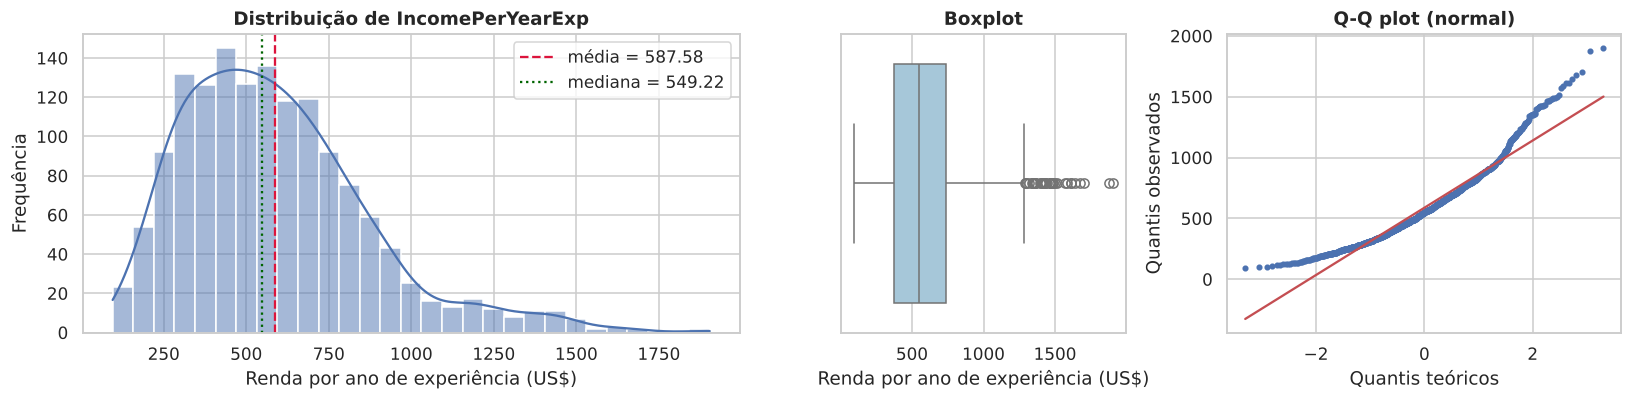

Média = 587.58 | mediana = 549.22 | desvio padrão = 284.65 | mín = 95.29 | máx = 1,904.00
Assimetria (skewness) = 1.05 -> distribuição fortemente assimétrica à direita (cauda longa de valores altos)
Curtose em excesso (kurtosis) = 1.48 -> leptocúrtica (caudas pesadas e pico mais agudo que a normal)
Teste de normalidade (D'Agostino): p = 8.13e-53 -> rejeita a normalidade (5%)
Melhor ajuste (Kolmogorov-Smirnov; apenas indicativo): Gama (KS=0.017) | Log-normal (KS=0.043) | Normal (KS=0.066)
Outliers pela regra do IQR: 43 de 1470


In [22]:
analisar_numerica("IncomePerYearExp", "Renda por ano de experiência (US$)")

**Discussão:** Em média, cada ano de carreira "vale" **US$ 588** de renda mensal (mediana 549; desvio padrão 285), com assimetria **1,05** e curtose **1,48**. A distribuição **gama** é a que melhor se ajusta (KS = 0,017, o melhor de todo o estudo), compatível com uma razão entre variáveis positivas. A cauda à direita (43 outliers, 2,9%) reúne quem alcançou cargo alto com pouca experiência. A hipótese se confirma, e a variável tem correlação apenas moderada com a renda (ρ ≈ 0,3) e negativa com a experiência (ρ ≈ -0,34), o que a torna um indicador complementar.

#### `SatisfactionIndex` (numérica)
**Pergunta:** Qual o nível geral de satisfação e ele varia muito entre pessoas?

**Hipótese:** Por ser uma média de quatro notas, tende a se aproximar de uma normal (Teorema Central do Limite), centrada em torno de 2,7.

**O que representa:** Variável criada: média de EnvironmentSatisfaction, JobSatisfaction, RelationshipSatisfaction e WorkLifeBalance (escala 1-4).

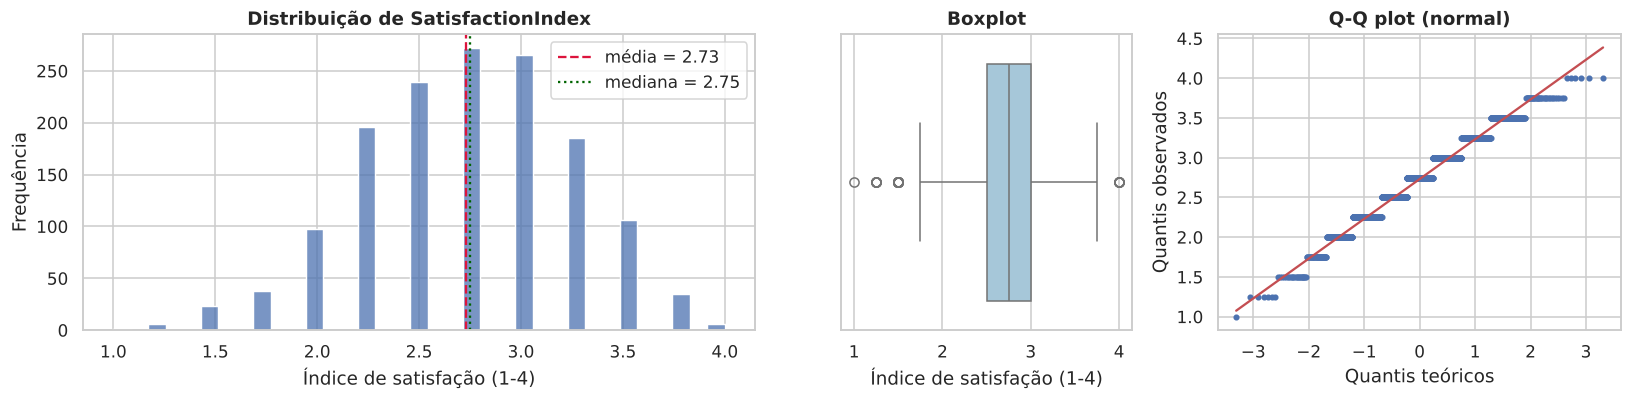

Média = 2.73 | mediana = 2.75 | desvio padrão = 0.51 | mín = 1.00 | máx = 4.00
Assimetria (skewness) = -0.20 -> distribuição aproximadamente simétrica
Curtose em excesso (kurtosis) = -0.19 -> mesocúrtica (semelhante à normal)
Teste de normalidade (D'Agostino): p = 2.42e-03 -> rejeita a normalidade (5%)
Melhor ajuste (Kolmogorov-Smirnov; apenas indicativo): Normal (KS=0.109) | Gama (KS=0.131) | Log-normal (KS=0.143)
Outliers pela regra do IQR: 36 de 1470


In [23]:
analisar_numerica("SatisfactionIndex", "Índice de satisfação (1-4)")

**Discussão:** O índice médio é de **2,73** (mediana 2,75; desvio padrão 0,51), com assimetria **-0,20** e curtose **-0,19**, ou seja, praticamente simétrico e mesocúrtico. A média de quatro notas se aproxima de uma normal, como previsto: o melhor ajuste é a normal (KS = 0,109). O teste de D'Agostino rejeita a normalidade (p = 0,002), mas está muito mais próximo de 0,05 do que as demais variáveis numéricas (todas com p < 1e-12). Há 36 valores extremos (2,4%), nas pontas da escala.

#### `JobLevel` (ordinal)
**Pergunta:** A pirâmide organizacional é típica, com base larga e topo estreito?

**Hipótese:** Distribuição decrescente: aproximadamente 70% da força de trabalho nos níveis 1 e 2 e poucos nos níveis 4 e 5.

**O que representa:** Nível hierárquico do cargo (1 = júnior ... 5 = executivo).

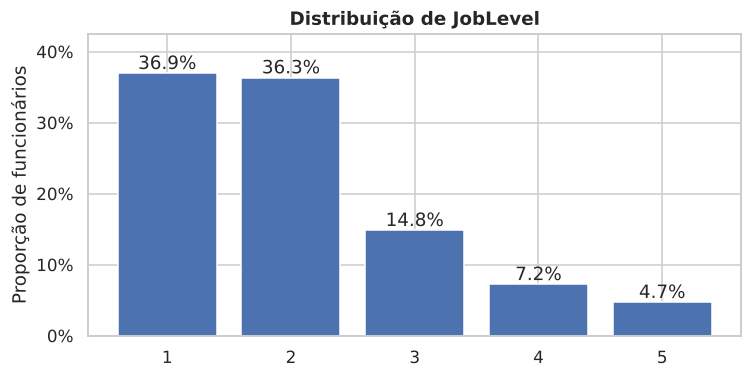

Moda = 1 | média = 2.06 | mediana = 2.0 | desvio padrão = 1.11
Assimetria (skewness) = 1.02 -> distribuição fortemente assimétrica à direita (cauda longa de valores altos)
Curtose em excesso (kurtosis) = 0.39 -> mesocúrtica (semelhante à normal)
Qui-quadrado contra uniforme discreta: p = 2.87e-154 -> incompatível com níveis equiprováveis


In [24]:
analisar_ordinal("JobLevel", ROTULOS["JobLevel"])

**Discussão:** A distribuição é decrescente: nível 1 (36,9%), nível 2 (36,3%), nível 3 (14,8%), nível 4 (7,2%) e nível 5 (4,7%). Os dois primeiros níveis somam **73,2%** do quadro, confirmando a pirâmide típica de base larga. Média de 2,06, mediana 2, assimetria **1,02** e curtose **0,39**. O teste qui-quadrado rejeita níveis equiprováveis (p ≈ 1e-154).

#### `StockOptionLevel` (ordinal)
**Pergunta:** Qual fração do quadro tem alguma participação acionária?

**Hipótese:** A maioria não tem ou tem apenas o nível mais baixo de opções; níveis altos são raros.

**O que representa:** Nível de participação em opções de ações (0 = nenhuma ... 3 = mais alta).

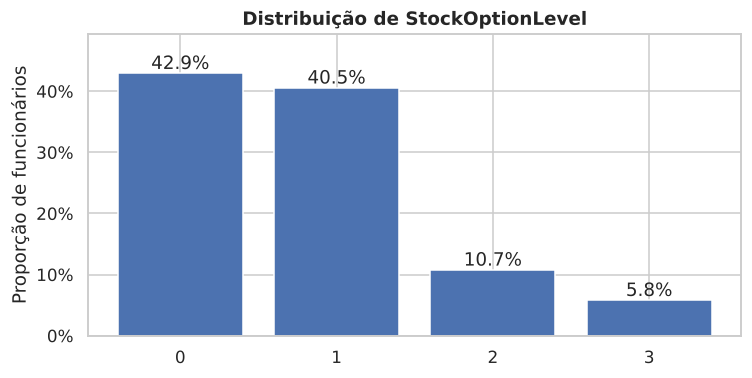

Moda = 0 | média = 0.79 | mediana = 1.0 | desvio padrão = 0.85
Assimetria (skewness) = 0.97 -> distribuição moderadamente assimétrica à direita (cauda longa de valores altos)
Curtose em excesso (kurtosis) = 0.36 -> mesocúrtica (semelhante à normal)
Qui-quadrado contra uniforme discreta: p = 2.23e-144 -> incompatível com níveis equiprováveis


In [25]:
analisar_ordinal("StockOptionLevel", ROTULOS["StockOptionLevel"])

**Discussão:** A maioria tem pouca ou nenhuma participação: **42,9%** não têm opções (nível 0) e **40,5%** têm o nível 1, somando 83,4%; os níveis 2 e 3 representam apenas 10,7% e 5,8%. Média de 0,79, assimetria **0,97** e curtose **0,36**. A hipótese se confirma, e a escassez de níveis altos precisa ser lembrada ao interpretar resultados dessa variável (poucos casos no nível 3).

#### `JobSatisfaction` (ordinal)
**Pergunta:** Os funcionários estão, em geral, satisfeitos com o trabalho?

**Hipótese:** Distribuição deslocada para notas altas (3 e 4), com minoria insatisfeita (1 e 2).

**O que representa:** Satisfação com o trabalho (1 = baixa ... 4 = muito alta).

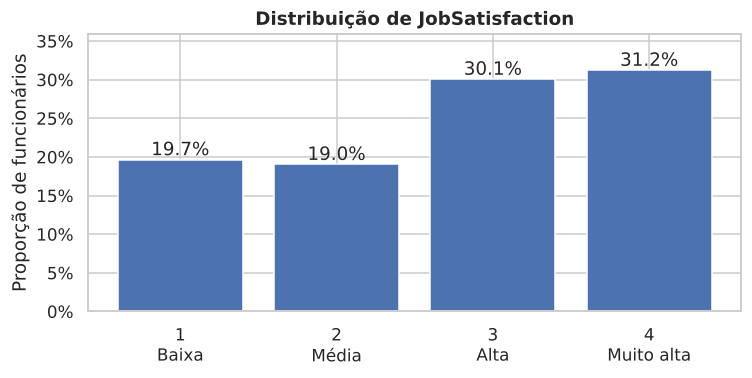

Moda = 4 | média = 2.73 | mediana = 3.0 | desvio padrão = 1.10
Assimetria (skewness) = -0.33 -> distribuição aproximadamente simétrica
Curtose em excesso (kurtosis) = -1.22 -> platicúrtica (caudas leves e distribuição mais achatada que a normal)
Qui-quadrado contra uniforme discreta: p = 2.85e-16 -> incompatível com níveis equiprováveis


In [26]:
analisar_ordinal("JobSatisfaction", ROTULOS["JobSatisfaction"])

**Discussão:** A satisfação com o trabalho tem média de **2,73** (moda 4; desvio padrão 1,10). As notas 3 e 4 somam 61,3% (30,1% e 31,2%), mas 38,7% dão nota 1 ou 2 (19,7% e 19,0%), uma minoria considerável, e não desprezível. Assimetria **-0,33** e curtose **-1,22** (platicúrtica): a distribuição é achatada, com muitas notas em todos os níveis, e não concentrada em torno de uma nota. A hipótese se confirma, com a ressalva de que o grupo insatisfeito é grande.

#### `EnvironmentSatisfaction` (ordinal)
**Pergunta:** A satisfação com o ambiente é parecida com a satisfação com o trabalho?

**Hipótese:** Padrão semelhante ao da satisfação com o trabalho: predominância de notas 3 e 4.

**O que representa:** Satisfação com o ambiente de trabalho (1 = baixa ... 4 = muito alta).

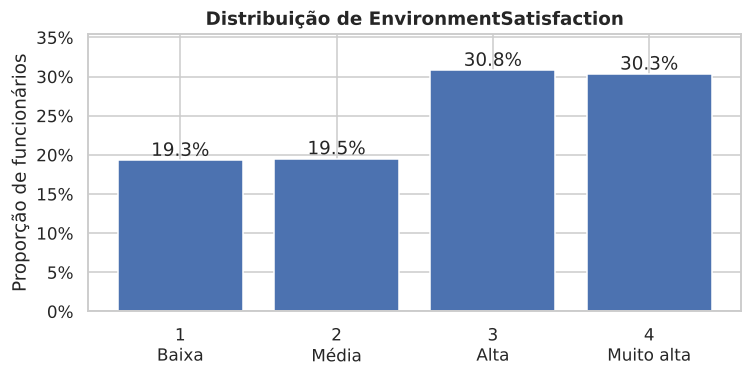

Moda = 3 | média = 2.72 | mediana = 3.0 | desvio padrão = 1.09
Assimetria (skewness) = -0.32 -> distribuição aproximadamente simétrica
Curtose em excesso (kurtosis) = -1.20 -> platicúrtica (caudas leves e distribuição mais achatada que a normal)
Qui-quadrado contra uniforme discreta: p = 8.53e-16 -> incompatível com níveis equiprováveis


In [27]:
analisar_ordinal("EnvironmentSatisfaction", ROTULOS["EnvironmentSatisfaction"])

**Discussão:** Padrão quase idêntico ao da satisfação com o trabalho: média **2,72**, 61,1% de notas 3 e 4 (30,8% e 30,3%) e 38,9% de notas 1 e 2 (19,3% e 19,5%). Assimetria **-0,32** e curtose **-1,20** (platicúrtica). A hipótese se confirma. A análise multivariada verificará se as diferentes satisfações se relacionam entre si e com as demais variáveis.

#### `WorkLifeBalance` (ordinal)
**Pergunta:** Como os funcionários avaliam o equilíbrio entre vida pessoal e trabalho?

**Hipótese:** Concentração na nota 3 ("Better"), com poucas avaliações extremas (1 e 4).

**O que representa:** Equilíbrio entre trabalho e vida pessoal (1 = ruim ... 4 = ótimo).

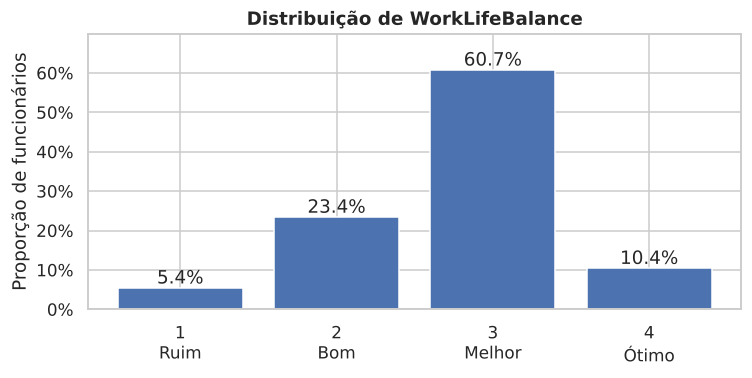

Moda = 3 | média = 2.76 | mediana = 3.0 | desvio padrão = 0.71
Assimetria (skewness) = -0.55 -> distribuição moderadamente assimétrica à esquerda (cauda longa de valores baixos)
Curtose em excesso (kurtosis) = 0.41 -> mesocúrtica (semelhante à normal)
Qui-quadrado contra uniforme discreta: p = 7.95e-239 -> incompatível com níveis equiprováveis


In [28]:
analisar_ordinal("WorkLifeBalance", ROTULOS["WorkLifeBalance"])

**Discussão:** A nota 3 ("Melhor") concentra **60,7%** das respostas, seguida de 23,4% (nota 2), 10,4% (nota 4) e apenas 5,4% (nota 1). Média de 2,76, desvio padrão 0,71, assimetria **-0,55** (leve cauda para notas baixas) e curtose **0,41**. A hipótese se confirma: é uma distribuição em torno de um valor central. Os 5,4% com equilíbrio "Ruim" são um grupo pequeno, mas de interesse para a análise de rotatividade.

#### `JobInvolvement` (ordinal)
**Pergunta:** Qual o nível típico de envolvimento dos funcionários?

**Hipótese:** Concentração na nota 3, com poucas notas extremas, similar ao equilíbrio trabalho-vida.

**O que representa:** Nível de envolvimento com o trabalho (1 = baixo ... 4 = muito alto).

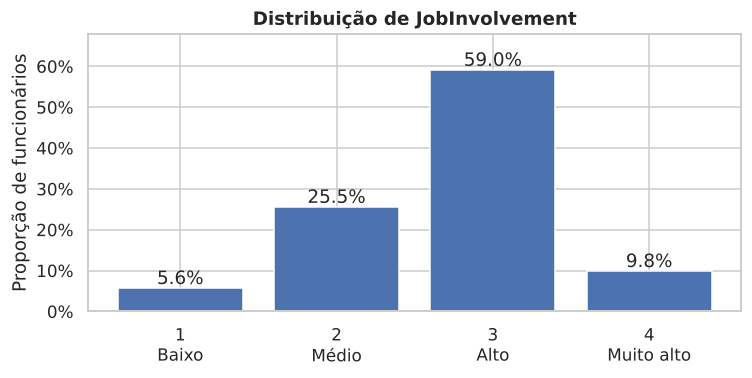

Moda = 3 | média = 2.73 | mediana = 3.0 | desvio padrão = 0.71
Assimetria (skewness) = -0.50 -> distribuição aproximadamente simétrica
Curtose em excesso (kurtosis) = 0.27 -> mesocúrtica (semelhante à normal)
Qui-quadrado contra uniforme discreta: p = 1.05e-224 -> incompatível com níveis equiprováveis


In [29]:
analisar_ordinal("JobInvolvement", ROTULOS["JobInvolvement"])

**Discussão:** A nota 3 ("Alto") reúne **59,0%** dos funcionários; as notas 2 e 4 somam 25,5% e 9,8%, e a nota 1 (envolvimento baixo) apenas 5,6%. Média de 2,73, desvio padrão 0,71, assimetria **-0,50** e curtose **0,27**. A hipótese se confirma, com perfil muito semelhante ao do equilíbrio trabalho-vida, e o grupo de baixo envolvimento é pequeno.

#### `Attrition` (categórica)
**Pergunta:** Qual a proporção de funcionários que saíram? O problema é desbalanceado?

**Hipótese:** Classes desbalanceadas: a classe "Yes" é minoritária (algo entre 10% e 20%).

**O que representa:** Variável alvo: "Yes" se o funcionário saiu da empresa; "No" caso contrário.

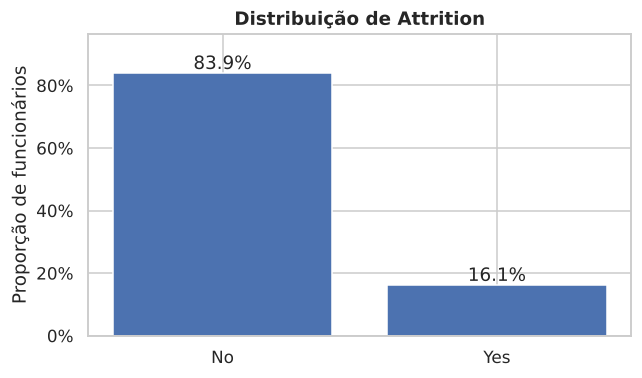

Nº de categorias = 2 | moda = No (83.9%) | entropia normalizada = 0.64 (1 = perfeitamente equilibrada)
Proporções: No: 83.9% | Yes: 16.1%
Qui-quadrado contra categorias equiprováveis: p = 8.85e-149


In [30]:
analisar_categorica("Attrition", "Attrition (saiu da empresa)")

**Discussão:** **83,9%** ficaram (1.233) e **16,1%** saíram (237): uma Bernoulli com p ≈ 0,16 e razão de desbalanceamento de **5,2 : 1**. A entropia normalizada é 0,64, bem abaixo de 1 (perfeito equilíbrio). A hipótese se confirma, e as consequências estão na seção de Pipeline: divisão estratificada, uso de métricas apropriadas (ROC-AUC, recall da classe positiva) e eventual ponderação de classes.

#### `OverTime` (categórica)
**Pergunta:** Quantos funcionários fazem hora extra?

**Hipótese:** A minoria faz hora extra (menos de 1/3 do quadro).

**O que representa:** Indica se o funcionário faz hora extra.

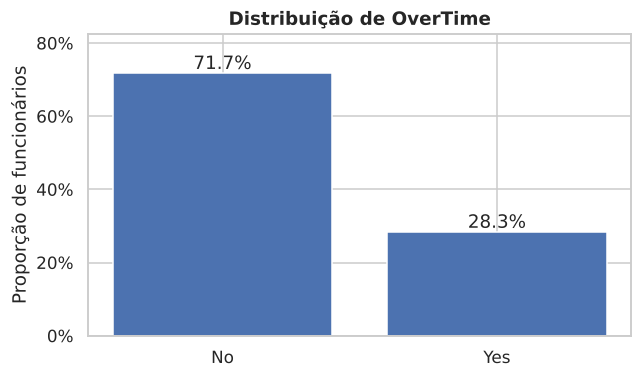

Nº de categorias = 2 | moda = No (71.7%) | entropia normalizada = 0.86 (1 = perfeitamente equilibrada)
Proporções: No: 71.7% | Yes: 28.3%
Qui-quadrado contra categorias equiprováveis: p = 3.56e-62


In [31]:
analisar_categorica("OverTime", "Faz hora extra?")

**Discussão:** **71,7%** não fazem hora extra e **28,3%** fazem (cerca de 1 em cada 3,5 funcionários), confirmando a hipótese. Distribuição Bernoulli com p ≈ 0,28 e entropia normalizada de 0,86. Quase 3 em cada 10 funcionários fazem hora extra, um grupo grande o bastante para que as comparações com `Attrition` tenham poder estatístico.

#### `BusinessTravel` (categórica)
**Pergunta:** Com que frequência as pessoas viajam a trabalho?

**Hipótese:** A maioria viaja raramente; viajar frequentemente é minoritário.

**O que representa:** Frequência de viagens a trabalho.

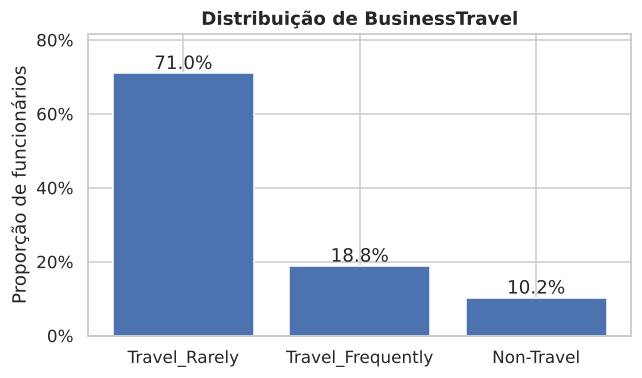

Nº de categorias = 3 | moda = Travel_Rarely (71.0%) | entropia normalizada = 0.72 (1 = perfeitamente equilibrada)
Proporções: Travel_Rarely: 71.0% | Travel_Frequently: 18.8% | Non-Travel: 10.2%
Qui-quadrado contra categorias equiprováveis: p = 1.39e-207


In [32]:
analisar_categorica("BusinessTravel", "Frequência de viagens a trabalho")

**Discussão:** **71,0%** viajam raramente (`Travel_Rarely`), **18,8%** viajam com frequência e **10,2%** não viajam. A hipótese se confirma. A categoria `Travel_Frequently` é minoritária, mas tem tamanho suficiente (cerca de 276 pessoas) para comparações. Entropia normalizada de 0,72 (categorias desbalanceadas).

#### `Department` (categórica)
**Pergunta:** Como o quadro se divide entre os departamentos?

**Hipótese:** P&D concentra a maior parte do quadro, seguido de Vendas, e RH é bem menor.

**O que representa:** Departamento do funcionário.

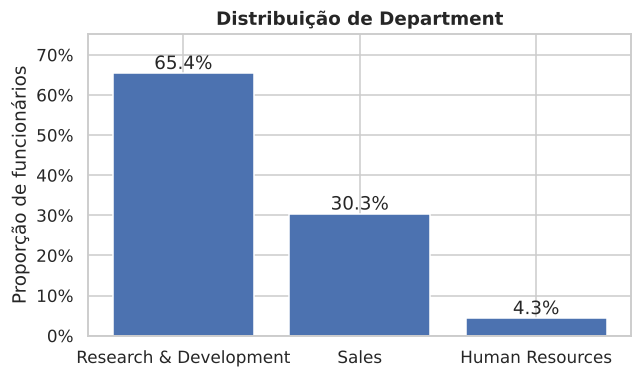

Nº de categorias = 3 | moda = Research & Development (65.4%) | entropia normalizada = 0.71 (1 = perfeitamente equilibrada)
Proporções: Research & Development: 65.4% | Sales: 30.3% | Human Resources: 4.3%
Qui-quadrado contra categorias equiprováveis: p = 1.07e-180


In [33]:
analisar_categorica("Department", "Departamento")

**Discussão:** **P&D concentra 65,4%** do quadro, **Vendas** tem 30,3% e **RH** apenas 4,3% (63 pessoas). A hipótese se confirma. O pequeno tamanho de RH torna as taxas desse departamento instáveis, o que deve ser considerado nas comparações. Entropia normalizada de 0,71.

#### `MaritalStatus` (categórica)
**Pergunta:** Qual o perfil de estado civil dos funcionários?

**Hipótese:** Casados formam o maior grupo, seguidos por solteiros e divorciados.

**O que representa:** Estado civil do funcionário.

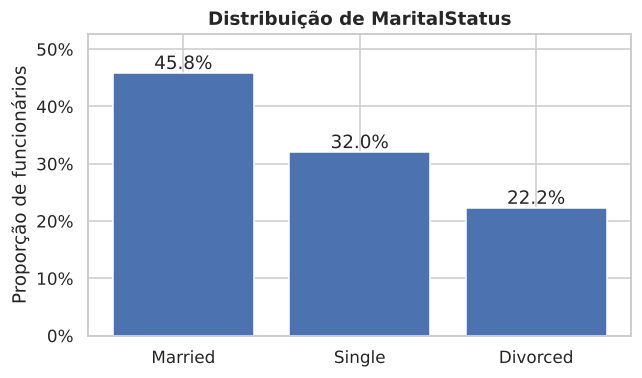

Nº de categorias = 3 | moda = Married (45.8%) | entropia normalizada = 0.96 (1 = perfeitamente equilibrada)
Proporções: Married: 45.8% | Single: 32.0% | Divorced: 22.2%
Qui-quadrado contra categorias equiprováveis: p = 1.61e-27


In [34]:
analisar_categorica("MaritalStatus", "Estado civil")

**Discussão:** **Casados** formam 45,8%, **solteiros** 32,0% e **divorciados** 22,2%, confirmando a hipótese. É uma das variáveis mais equilibradas da base (entropia normalizada de 0,96), o que facilita as comparações entre grupos.

#### `JobRole` (categórica)
**Pergunta:** Quais funções concentram o quadro? Há funções muito pequenas?

**Hipótese:** Poucas funções (executivo de vendas, cientista de pesquisa, técnico de laboratório) concentram a maior parte do quadro; funções de gestão e RH são pequenas.

**O que representa:** Função/cargo do funcionário (9 categorias).

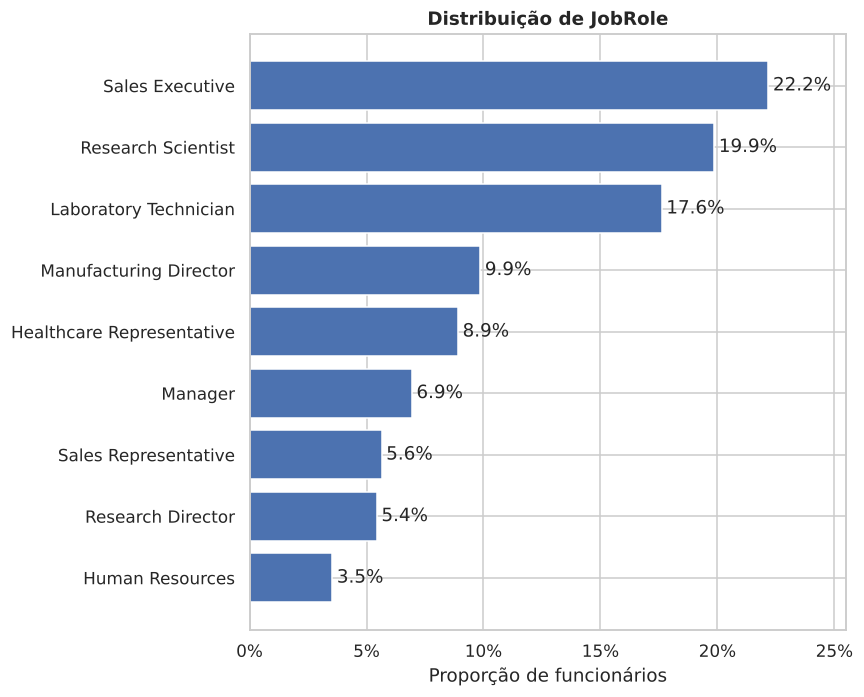

Nº de categorias = 9 | moda = Sales Executive (22.2%) | entropia normalizada = 0.92 (1 = perfeitamente equilibrada)
Proporções: Sales Executive: 22.2% | Research Scientist: 19.9% | Laboratory Technician: 17.6% | Manufacturing Director: 9.9% | Healthcare Representative: 8.9% | Manager: 6.9% | Sales Representative: 5.6% | Research Director: 5.4% | Human Resources: 3.5%
Qui-quadrado contra categorias equiprováveis: p = 9.10e-105


In [35]:
analisar_categorica("JobRole", "Função (cargo)")

**Discussão:** Três funções concentram **59,7%** do quadro: Sales Executive (22,2%), Research Scientist (19,9%) e Laboratory Technician (17,6%). Funções de gestão e especialistas são pequenas: Manager (6,9%), Research Director (5,4%) e Human Resources (3,5%), e Sales Representative representa 5,6%. A hipótese se confirma. Os grupos pequenos (por exemplo, RH com 52 pessoas) exigem cautela ao interpretar taxas de saída por função.

#### `AgeGroup` (categórica)
**Pergunta:** Como o quadro se distribui por faixa etária?

**Hipótese:** Predominância das faixas de 30-39 anos; menor presença nas faixas extremas (<30 e 50+).

**O que representa:** Variável criada: Age categorizada em <30, 30-39, 40-49 e 50+.

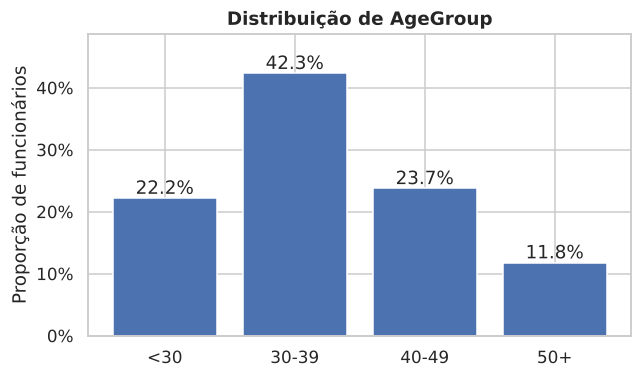

Nº de categorias = 4 | moda = 30-39 (42.3%) | entropia normalizada = 0.93 (1 = perfeitamente equilibrada)
Proporções: <30: 22.2% | 30-39: 42.3% | 40-49: 23.7% | 50+: 11.8%
Qui-quadrado contra categorias equiprováveis: p = 1.93e-61


In [36]:
analisar_categorica("AgeGroup", "Faixa etária", ordem=["<30", "30-39", "40-49", "50+"])

**Discussão:** A faixa de **30 a 39 anos** é a maior (42,3%), seguida de 40-49 (23,7%), <30 (22,2%) e 50+ (11,8%). A hipótese se confirma em parte: as faixas extremas são menores, mas a faixa de menos de 30 anos tem peso quase igual ao da de 40-49. Entropia normalizada de 0,93.

### Limpezas adicionais: valores extremos (outliers)

Na célula abaixo, contamos os valores extremos pela regra do IQR (1,5 × amplitude interquartil) em todas as variáveis numéricas analisadas e verificamos se são erros ou valores plausíveis.

In [37]:
# caso perceba a necessidade de realizar limpezas adicionais nos dados aqui, não há problema,
# mas certifique-se de descrever todo o processo e a justificativa
# por trás das suas escolhas
tab_out = pd.DataFrame({"outliers (IQR)": {c: contar_outliers(df[c]) for c in VARS_NUM},
                        "% da base": {c: round(100 * contar_outliers(df[c]) / len(df), 1) for c in VARS_NUM}})
display(tab_out[tab_out["outliers (IQR)"] > 0].sort_values("outliers (IQR)", ascending=False))

# Os valores extremos de renda são plausíveis? Verificamos o nível do cargo de quem os possui.
q1, q3 = df["MonthlyIncome"].quantile([0.25, 0.75])
limite = q3 + 1.5 * (q3 - q1)
extremos = df[df["MonthlyIncome"] > limite]
print(f"\nRenda acima de US$ {limite:,.0f}: {len(extremos)} funcionários")
print("Nível do cargo desses funcionários:", extremos["JobLevel"].value_counts().sort_index().to_dict())
print("Cargos:", {k: v for k, v in extremos["JobRole"].value_counts().items() if v > 0})

,outliers (IQR),% da base
TrainingTimesLastYear,238,16.2
MonthlyIncome,114,7.8
YearsSinceLastPromotion,107,7.3
YearsAtCompany,104,7.1
TotalWorkingYears,63,4.3
NumCompaniesWorked,52,3.5
IncomePerYearExp,43,2.9
SatisfactionIndex,36,2.4
YearsInCurrentRole,21,1.4
YearsWithCurrManager,14,1.0



Renda acima de US$ 16,581: 114 funcionários
Nível do cargo desses funcionários: {4: 45, 5: 69}
Cargos: {'Manager': 74, 'Research Director': 40}


**Decisão:** os valores extremos **foram mantidos**. Os de renda pertencem a funcionários de cargos altos (níveis 4 e 5, ou de funções de gestão), ou seja, são **valores reais e plausíveis**, não erros de digitação. Já os extremos dos "anos de..." correspondem a funcionários realmente antigos na empresa. Remover essas pessoas apagaria justamente o segmento sênior, que tem comportamento distinto. Em vez de excluí-los, o pipeline trata a assimetria com uma transformação (logarítmica (log(1 + x))) para as variáveis mais assimétricas.

In [38]:
# Tabela-resumo de todas as variáveis analisadas
resumo_uni = pd.DataFrame(RESUMO_UNI).set_index("Variável")
display(resumo_uni.round(2))
assert len(VARS_UNIVARIADAS) >= 20, "São exigidas ao menos 20 variáveis na análise univariada"
print(f"{len(VARS_UNIVARIADAS)} variáveis analisadas ({len(VARS_NUM_ORD)} numéricas/ordinais com assimetria e curtose).")

,Tipo,Média,Desvio padrão,Assimetria,Curtose,Distribuição
Variável,,,,,,
Age,Numérica,36.92,9.14,0.41,-0.41,Log-normal (KS=0.03)
MonthlyIncome,Numérica,6502.93,4707.96,1.37,1.00,Log-normal (KS=0.06)
DailyRate,Numérica,802.49,403.51,-0.00,-1.20,Uniforme (KS=0.02)
DistanceFromHome,Numérica,9.19,8.11,0.96,-0.23,Log-normal (KS=0.12)
TotalWorkingYears,Numérica,11.28,7.78,1.12,0.91,Log-normal (deslocada) (KS=0.09)
YearsAtCompany,Numérica,7.01,6.13,1.76,3.92,Gama (deslocada) (KS=0.09)
YearsInCurrentRole,Numérica,4.23,3.62,0.92,0.47,Geométrica (KS=0.14)
YearsSinceLastPromotion,Numérica,2.19,3.22,1.98,3.60,Geométrica (KS=0.11)
YearsWithCurrManager,Numérica,4.12,3.57,0.83,0.17,Geométrica (KS=0.12)


27 variáveis analisadas (20 numéricas/ordinais com assimetria e curtose).


### Principais variáveis de interesse (levadas para a análise multivariada)

A tabela anterior e o ranking de informação mútua permitem destacar as variáveis que serão exploradas na análise multivariada:

- **`OverTime`**, **`JobRole`**, **`JobLevel`**, **`MonthlyIncome`**, **`Age`**/**`AgeGroup`**, **`TotalWorkingYears`** e **`MaritalStatus`**: as de maior informação mútua com `Attrition` e também as de formas de distribuição mais claras (renda log-normal, anos de carreira assimétricos). São o centro da análise multivariada.
- **`DailyRate`**: distribuição uniforme com curtose em excesso de exatamente -1,2, indício de uma variável aleatória sem relação com a realidade; será testada contra `MonthlyIncome`.
- **`YearsInCurrentRole`** e **`YearsWithCurrManager`**: picos em 0, 2 e 7 anos, um comportamento além da simples assimetria, e fortemente associadas a `YearsAtCompany`.
- **`YearsSinceLastPromotion`**, **`PercentSalaryHike`** e **`DistanceFromHome`**: parecem importantes pela intuição de negócio, mas tinham informação mútua ~0. Serão testadas.
- **`SatisfactionIndex`** (e suas componentes): distribuição próxima da normal; resume o tema de satisfação em uma única variável.
- **`Attrition`**: desbalanceada (16,1% de saídas), o que condiciona a análise e o pipeline.
- Estruturais, de contexto: `Department`, `BusinessTravel`, `StockOptionLevel` e as demais ordinais (satisfação, envolvimento e equilíbrio).

# Análise Multivariada

Nesta seção, você deve plotar pelo menos **10 visualizações multivariadas**. O objetivo é investigar correlações e comportamentos subjacentes no conjunto de dados.
Naturalmente, algumas visualizações podem revelar resultados esperados; no entanto, você deve identificar pelo menos **UM** comportamento não óbvio nos dados.

Siga estas etapas ao criar suas visualizações:
1. Formule uma hipótese. Explique por que você escolheu essas variáveis específicas e o que espera descobrir por meio de sua relação;
2. Determine qual tipo de visualização é mais adequado;
3. Relate as descobertas e discuta se elas corroboram ou não a hipótese formulada.


### Dicas

Nesta seção, vá além de explorações simples. Por exemplo, considere aplicar técnicas como PCA, t-SNE, ou outras não abordadas nas aulas. O objetivo é cultivar um pensamento crítico em relação à análise de dados e ao nosso trabalho.

### Importante

É estritamente proibido criar visualizações multivariadas utilizando variáveis que não foram incluídas na seção anterior (análise univariada).

In [39]:
# novamente, fique à vontade para inserir quantas células forem necessárias para plotar as visualizações
# e descrever as principais descobertas
PAL = {"No": "#4C72B0", "Yes": "#C44E52"}      # cores fixas: azul = ficou, vermelho = saiu


def checar_vars(*cols):
    """Garante que só usamos variáveis analisadas na seção univariada (regra do projeto)."""
    fora = [c for c in cols if c not in VARS_UNIVARIADAS]
    assert not fora, f"Variáveis fora da análise univariada: {fora}"


def cramers_v(tabela):
    """V de Cramér: força da associação entre duas variáveis categóricas (0 a 1)."""
    chi2 = stats.chi2_contingency(tabela, correction=False)[0]
    return float(np.sqrt(chi2 / (tabela.values.sum() * (min(tabela.shape) - 1))))


def mapa_calor_taxa(linhas, colunas, ax, titulo, ordem_linhas=None, ordem_colunas=None, min_n=0):
    """Mapa de calor da taxa de saída por duas variáveis, anotando taxa e tamanho do grupo."""
    checar_vars(linhas, colunas)
    g = y_bin.groupby([df[linhas], df[colunas]], observed=True)
    taxa = g.mean().unstack()
    n = g.size().unstack()
    if ordem_linhas is not None:
        taxa, n = taxa.reindex(ordem_linhas), n.reindex(ordem_linhas)
    if ordem_colunas is not None:
        taxa, n = taxa[ordem_colunas], n[ordem_colunas]
    notas = taxa.copy().astype(object)
    for i in taxa.index:
        for j in taxa.columns:
            notas.loc[i, j] = f"{taxa.loc[i, j]:.0%}\n(n={int(n.loc[i, j])})"
    sns.heatmap(taxa, annot=notas, fmt="", cmap="Reds", vmin=0, ax=ax, cbar_kws={"label": "Taxa de saída"})
    ax.grid(False)
    ax.set_title(titulo)
    return taxa, n

### Visualização 1: `OverTime` × `Attrition`
**Pergunta:** fazer hora extra está associado à saída do funcionário?

**Hipótese:** sim. Jornadas mais longas aumentam o desgaste e a vontade de sair, então a taxa de saída deve ser bem maior entre quem faz hora extra.

**Escolha do gráfico:** duas variáveis categóricas -> barras empilhadas em 100% (comparam proporções entre grupos de tamanhos diferentes). O teste qui-quadrado e o V de Cramér medem a significância e a força da associação.

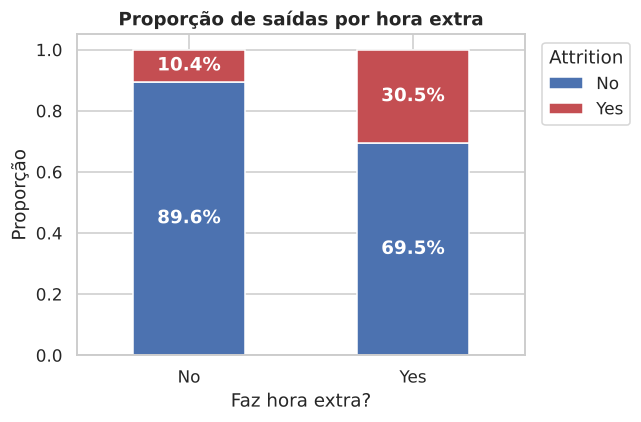

Taxa de saída sem hora extra = 10.4% | com hora extra = 30.5% (razão = 2.9x)
Qui-quadrado = 87.6 | p-valor = 8.16e-21 | V de Cramér = 0.25


In [40]:
checar_vars("OverTime", "Attrition")
tab_abs = pd.crosstab(df["OverTime"], df["Attrition"])
tab = pd.crosstab(df["OverTime"], df["Attrition"], normalize="index")
ax = tab.plot(kind="bar", stacked=True, color=[PAL["No"], PAL["Yes"]], figsize=(6, 4), rot=0)
for cont in ax.containers:
    ax.bar_label(cont, labels=[f"{v:.1%}" for v in cont.datavalues], label_type="center", color="white", fontweight="bold")
ax.set_title("Proporção de saídas por hora extra")
ax.set_xlabel("Faz hora extra?")
ax.set_ylabel("Proporção")
ax.legend(title="Attrition", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()
chi2, p, _, _ = stats.chi2_contingency(tab_abs)
print(f"Taxa de saída sem hora extra = {tab.loc['No', 'Yes']:.1%} | com hora extra = {tab.loc['Yes', 'Yes']:.1%} "
      f"(razão = {tab.loc['Yes', 'Yes'] / tab.loc['No', 'Yes']:.1f}x)")
print(f"Qui-quadrado = {chi2:.1f} | p-valor = {p:.2e} | V de Cramér = {cramers_v(tab_abs):.2f}")

**Discussão:** A hipótese se confirma com folga. Entre quem faz hora extra, **30,5%** saíram, contra **10,4%** de quem não faz (2,9 vezes mais). O qui-quadrado é 87,6 (p ≈ 8e-21) e o V de Cramér é 0,25, um efeito de tamanho moderado, o maior entre as variáveis categóricas estudadas. Isto é associação, não causa: quem faz hora extra pode ser também quem está em cargos de base ou mais sobrecarregado, o que as próximas análises investigam.

### Visualização 2: `JobRole` × `Attrition`
**Pergunta:** algumas funções têm taxa de saída muito diferente das outras?

**Hipótese:** sim. Funções de entrada, com menor remuneração e mais pressão por metas (como vendas), devem perder mais gente que funções de gestão.

**Escolha do gráfico:** uma variável categórica com 9 níveis e nomes longos -> barras horizontais ordenadas pela taxa de saída, com o tamanho de cada grupo ao lado (taxas de grupos pequenos são instáveis) e a média geral como referência.

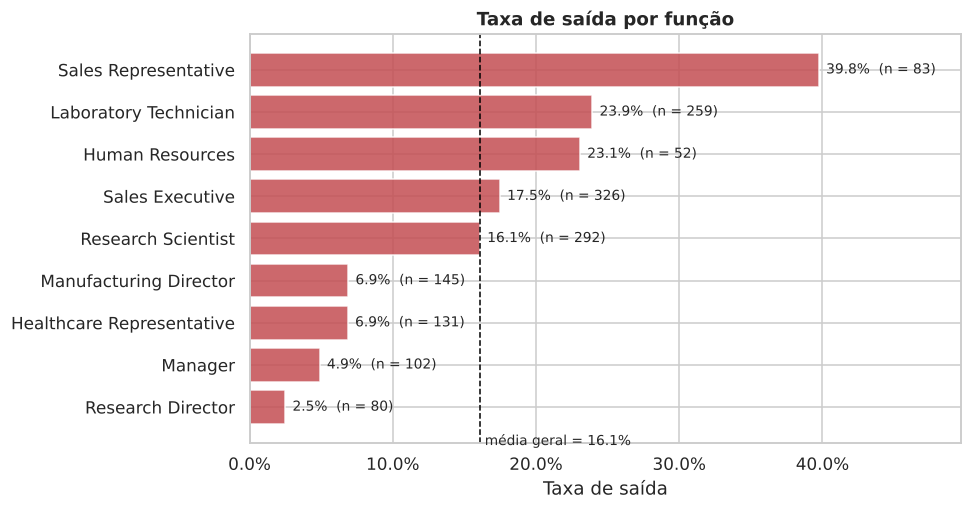

Qui-quadrado = 86.2 | p-valor = 2.75e-15 | V de Cramér = 0.24


In [41]:
checar_vars("JobRole", "Attrition")
taxa = y_bin.groupby(df["JobRole"], observed=True).agg(["mean", "size"]).sort_values("mean")
fig, ax = plt.subplots(figsize=(9, 4.8))
ax.barh(taxa.index.astype(str), taxa["mean"], color=PAL["Yes"], alpha=0.85)
ax.axvline(y_bin.mean(), color="black", ls="--", lw=1)
ax.text(y_bin.mean() + 0.003, -0.9, f"média geral = {y_bin.mean():.1%}", fontsize=9)
for i, (m, n) in enumerate(zip(taxa["mean"], taxa["size"])):
    ax.text(m + 0.005, i, f"{m:.1%}  (n = {n})", va="center", fontsize=9)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_xlim(0, taxa["mean"].max() * 1.25)
ax.set_title("Taxa de saída por função")
ax.set_xlabel("Taxa de saída")
plt.tight_layout()
plt.show()
tab_abs = pd.crosstab(df["JobRole"], df["Attrition"])
chi2, p, _, _ = stats.chi2_contingency(tab_abs)
print(f"Qui-quadrado = {chi2:.1f} | p-valor = {p:.2e} | V de Cramér = {cramers_v(tab_abs):.2f}")

**Discussão:** A hipótese se confirma: a taxa de saída varia de **2,5%** (Research Director) a **39,8%** (Sales Representative, n = 83), uma diferença de 16 vezes (χ² = 86,2; V = 0,24). Depois dos representantes de vendas vêm Laboratory Technician (23,9%) e Human Resources (23,1%, n = 52, amostra pequena); as funções de gestão (Manager 4,9%, Research Director 2,5%) e Manufacturing Director e Healthcare Representative (6,9% cada) ficam muito abaixo da média de 16,1%. O padrão sugere que funções de entrada e operacionais perdem mais gente do que as de liderança.

### Visualização 3: `MonthlyIncome` × `Attrition`
**Pergunta:** quem sai ganha menos?

**Hipótese:** sim. A remuneração é o principal motivo "racional" para trocar de empresa, então a renda de quem saiu deve ser menor.

**Escolha do gráfico:** variável numérica assimétrica contra uma categórica binária -> violino com quartis (mostra a forma da distribuição, não só a mediana). Como a renda não é normal, usamos o teste não paramétrico de Mann-Whitney.

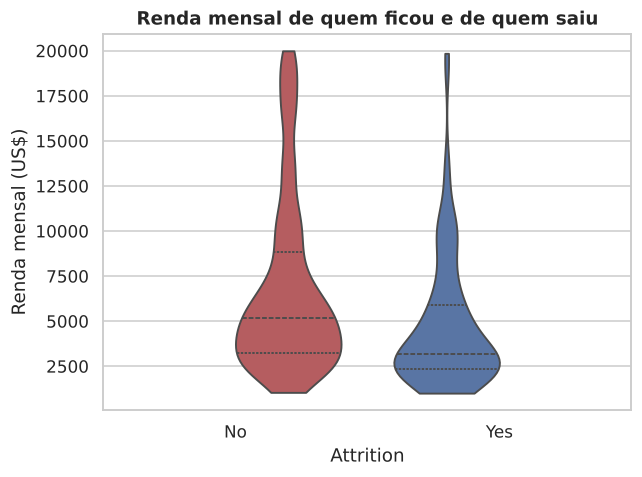

Mediana de quem saiu = US$ 3,202 | de quem ficou = US$ 5,204 (diferença de -38%)
Mann-Whitney: p = 2.95e-14 | probabilidade de superioridade (quem sai ganha mais que quem fica) = 0.34


In [42]:
checar_vars("MonthlyIncome", "Attrition")
fig, ax = plt.subplots(figsize=(6, 4.5))
sns.violinplot(data=df, x="Attrition", y="MonthlyIncome", hue="Attrition", palette=PAL, inner="quartile",
               cut=0, legend=False, ax=ax)
ax.set_title("Renda mensal de quem ficou e de quem saiu")
ax.set_xlabel("Attrition")
ax.set_ylabel("Renda mensal (US$)")
plt.tight_layout()
plt.show()
sai, fica = df.loc[df["Attrition"] == "Yes", "MonthlyIncome"], df.loc[df["Attrition"] == "No", "MonthlyIncome"]
u = stats.mannwhitneyu(sai, fica)
print(f"Mediana de quem saiu = US$ {sai.median():,.0f} | de quem ficou = US$ {fica.median():,.0f} "
      f"(diferença de {100 * (sai.median() / fica.median() - 1):.0f}%)")
print(f"Mann-Whitney: p = {u.pvalue:.2e} | probabilidade de superioridade (quem sai ganha mais que quem fica) = "
      f"{u.statistic / (len(sai) * len(fica)):.2f}")

**Discussão:** A hipótese se confirma: a mediana de renda de quem saiu é de **US$ 3.202**, contra **US$ 5.204** de quem ficou (38% menos), e o teste de Mann-Whitney rejeita a igualdade (p ≈ 3e-14). A probabilidade de superioridade é 0,34: sorteando um funcionário que saiu e outro que ficou, o que ficou ganha mais em 66% das vezes. O violino mostra que quem sai está concentrado em rendas baixas, mas há saídas em toda a faixa. Renda aqui está misturada com cargo e tempo de carreira, o que a próxima visualização separa.

### Visualização 4: `MonthlyIncome` × `JobLevel` × `Attrition` (comportamento não óbvio)
**Pergunta:** a diferença de renda entre quem sai e quem fica persiste quando comparamos pessoas **do mesmo nível de cargo**?

**Hipótese:** a diferença é grande no conjunto da base, mas pode ser em boa parte um efeito de composição: o nível 1 tem renda baixa e muitas saídas, o que "puxa" a renda média de quem sai para baixo. Se for assim, dentro de cada nível a diferença deve encolher.

**Escolha do gráfico:** renda (numérica) por nível (ordinal) e por grupo (binária) -> boxplots agrupados lado a lado, com teste por nível.

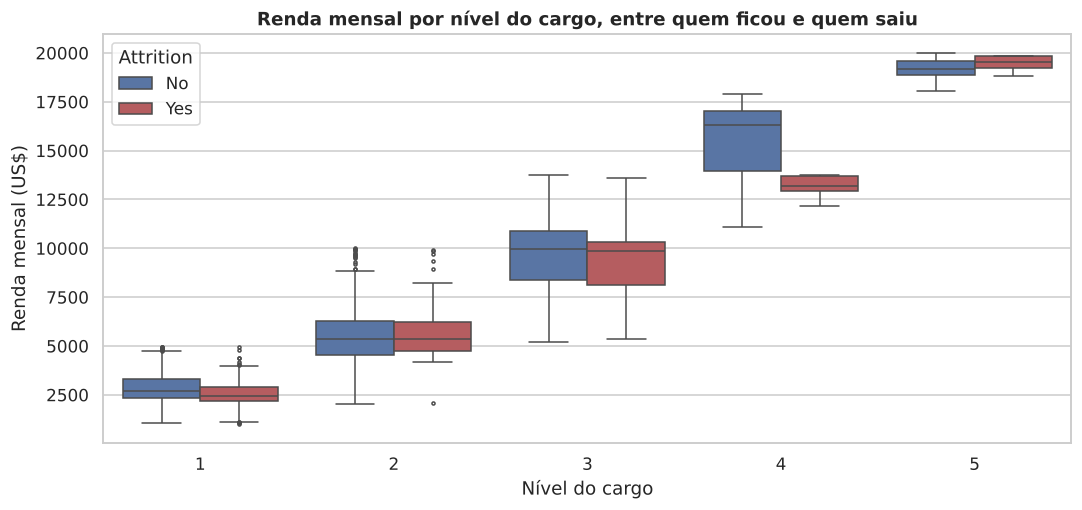

,n saíram,n ficaram,mediana saíram,mediana ficaram,diferença (%),p-valor (Mann-Whitney)
JobLevel,,,,,,
1,143,400,2437.0,2719.0,-10.4,4.1e-04
2,52,482,5346.0,5334.5,0.2,3.1e-01
3,32,186,9887.0,9982.5,-1.0,1.6e-01
4,5,101,13194.0,16307.0,-19.1,4.0e-03
5,5,64,19545.0,19199.5,1.8,2.1e-01


Base toda: mediana de quem saiu -38% menor que a de quem ficou
Composição: % de quem saiu no nível 1 = 60% | % de quem ficou no nível 1 = 32%


In [43]:
checar_vars("MonthlyIncome", "JobLevel", "Attrition")
fig, ax = plt.subplots(figsize=(10, 4.8))
sns.boxplot(data=df, x="JobLevel", y="MonthlyIncome", hue="Attrition", palette=PAL, fliersize=2, ax=ax)
ax.set_title("Renda mensal por nível do cargo, entre quem ficou e quem saiu")
ax.set_xlabel("Nível do cargo")
ax.set_ylabel("Renda mensal (US$)")
plt.tight_layout()
plt.show()

linhas = []
for nivel, g in df.groupby("JobLevel"):
    a = g.loc[g["Attrition"] == "Yes", "MonthlyIncome"]
    b = g.loc[g["Attrition"] == "No", "MonthlyIncome"]
    p = stats.mannwhitneyu(a, b).pvalue if len(a) >= 3 else np.nan
    linhas.append({"JobLevel": nivel, "n saíram": len(a), "n ficaram": len(b),
                   "mediana saíram": a.median(), "mediana ficaram": b.median(),
                   "diferença (%)": 100 * (a.median() / b.median() - 1), "p-valor (Mann-Whitney)": p})
tab_nivel = pd.DataFrame(linhas).set_index("JobLevel")
tab_exib = tab_nivel.round(1)
tab_exib["p-valor (Mann-Whitney)"] = tab_nivel["p-valor (Mann-Whitney)"].map(lambda v: f"{v:.1e}")
display(tab_exib)
sai, fica = df.loc[df["Attrition"] == "Yes", "MonthlyIncome"], df.loc[df["Attrition"] == "No", "MonthlyIncome"]
print(f"Base toda: mediana de quem saiu {100 * (sai.median() / fica.median() - 1):.0f}% menor que a de quem ficou")
print("Composição: % de quem saiu no nível 1 =", f"{(df.loc[df['Attrition'] == 'Yes', 'JobLevel'] == 1).mean():.0%}",
      "| % de quem ficou no nível 1 =", f"{(df.loc[df['Attrition'] == 'No', 'JobLevel'] == 1).mean():.0%}")

**Discussão:** Este é um achado não óbvio: a diferença de 38% vista na base toda **encolhe muito quando se compara dentro do mesmo nível**. No nível 1, quem saiu ganha 10% menos (p < 0,001); nos níveis 2 e 3, a diferença é praticamente nula (+0,2% e -1%, não significativa); nos níveis 4 e 5 há só 5 saídas em cada, o que torna os números frágeis (a queda de 19% no nível 4 tem p = 0,004, mas com 5 casos não é confiável). A explicação é que **60% de quem saiu está no nível 1, contra 32% de quem ficou**: boa parte do efeito 'renda baixa' é, na verdade, efeito de 'cargo baixo'. A hipótese de que a renda explica sozinha a saída é, portanto, apenas parcialmente confirmada.

### Visualização 5: matriz de correlação entre as variáveis numéricas e ordinais
**Pergunta:** quais variáveis numéricas andam juntas? Existem blocos de variáveis redundantes?

**Hipótese:** idade, experiência, tempo de casa, nível do cargo e renda formam um bloco fortemente correlacionado (carreira longa -> cargo mais alto -> salário maior), enquanto as variáveis de satisfação e as "taxas" ficam isoladas.

**Escolha do gráfico:** mapa de calor da correlação de **Spearman** (adequado a variáveis assimétricas e ordinais), apenas triângulo inferior para evitar redundância.

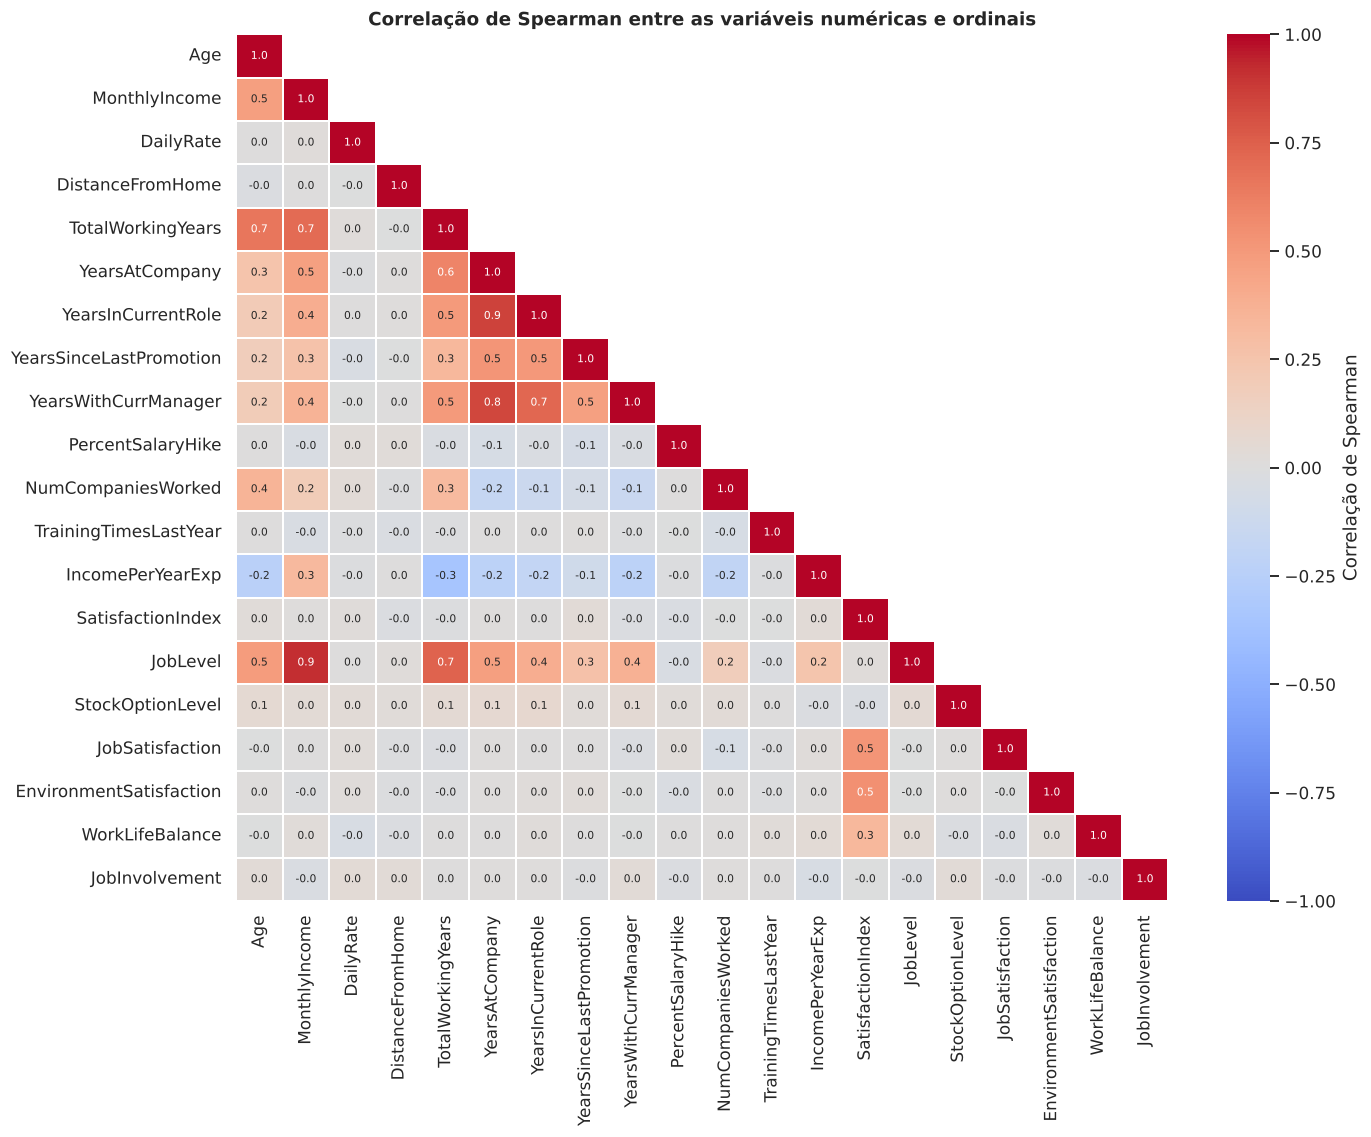

Pares mais correlacionados:


,var1,var2,rho,|rho|
0,MonthlyIncome,JobLevel,0.92,0.92
1,YearsAtCompany,YearsInCurrentRole,0.85,0.85
2,YearsAtCompany,YearsWithCurrManager,0.84,0.84
3,TotalWorkingYears,JobLevel,0.73,0.73
4,YearsInCurrentRole,YearsWithCurrManager,0.72,0.72
5,MonthlyIncome,TotalWorkingYears,0.71,0.71
6,Age,TotalWorkingYears,0.66,0.66
7,TotalWorkingYears,YearsAtCompany,0.59,0.59


Pares com correlação mais negativa:


,var1,var2,rho,|rho|
0,TotalWorkingYears,IncomePerYearExp,-0.34,0.34
1,Age,IncomePerYearExp,-0.24,0.24
2,YearsAtCompany,IncomePerYearExp,-0.22,0.22
3,YearsWithCurrManager,IncomePerYearExp,-0.22,0.22


Bloco carreira/renda (Age, TotalWorkingYears, JobLevel, MonthlyIncome, YearsAtCompany): correlação média = 0.58
Maior |rho| entre satisfação/envolvimento e o bloco de carreira = 0.04
Maior |rho| de DailyRate com qualquer outra variável = 0.04


In [44]:
checar_vars(*VARS_NUM_ORD)
corr = df[VARS_NUM_ORD].corr(method="spearman")
mascara = np.triu(np.ones_like(corr, dtype=bool), k=1)
fig, ax = plt.subplots(figsize=(13, 10.5))
sns.heatmap(corr, mask=mascara, cmap="coolwarm", vmin=-1, vmax=1, center=0, annot=True, fmt=".1f",
            annot_kws={"size": 7}, linewidths=0.3, ax=ax, cbar_kws={"label": "Correlação de Spearman"})
ax.set_title("Correlação de Spearman entre as variáveis numéricas e ordinais")
ax.grid(False)
plt.tight_layout()
plt.show()

iu = np.triu_indices_from(corr, k=1)
pares = pd.DataFrame({"var1": corr.index[iu[0]], "var2": corr.columns[iu[1]], "rho": corr.values[iu]})
pares["|rho|"] = pares["rho"].abs()
print("Pares mais correlacionados:")
display(pares.sort_values("|rho|", ascending=False).head(8).round(2).reset_index(drop=True))
print("Pares com correlação mais negativa:")
display(pares.sort_values("rho").head(4).round(2).reset_index(drop=True))
blocos = ["Age", "TotalWorkingYears", "JobLevel", "MonthlyIncome", "YearsAtCompany"]
sub = corr.loc[blocos, blocos].values[np.triu_indices(len(blocos), k=1)]
print(f"Bloco carreira/renda ({', '.join(blocos)}): correlação média = {sub.mean():.2f}")
sat = ["JobSatisfaction", "EnvironmentSatisfaction", "WorkLifeBalance", "JobInvolvement"]
print(f"Maior |rho| entre satisfação/envolvimento e o bloco de carreira = {corr.loc[sat, blocos].abs().values.max():.2f}")
outras = [c for c in VARS_NUM_ORD if c != "DailyRate"]
print(f"Maior |rho| de DailyRate com qualquer outra variável = {corr.loc['DailyRate', outras].abs().max():.2f}")

**Discussão:** O mapa mostra dois blocos. O bloco de carreira é fortemente correlacionado: MonthlyIncome–JobLevel (ρ = 0,92), YearsAtCompany–YearsInCurrentRole (0,85), YearsAtCompany–YearsWithCurrManager (0,84) e TotalWorkingYears–JobLevel (0,73), com correlação média de 0,58 dentro do bloco. Isso indica redundância (multicolinearidade) que importa em modelos lineares. Já as variáveis de satisfação e envolvimento são praticamente independentes desse bloco (|ρ| máximo de 0,04), e a DailyRate não se correlaciona com nada (|ρ| máximo de 0,04). A hipótese se confirma.

### Visualização 6: `MonthlyIncome` × `TotalWorkingYears` × `Attrition`
**Pergunta:** em que região "experiência × salário" se concentram as saídas?

**Hipótese:** a renda cresce com a experiência, e as saídas se concentram em quem tem pouca experiência e baixa renda (início de carreira).

**Escolha do gráfico:** duas variáveis numéricas -> dispersão (a cor mostra o alvo). Usamos transparência para lidar com sobreposição e plotamos os que saíram por cima, pois são minoria.

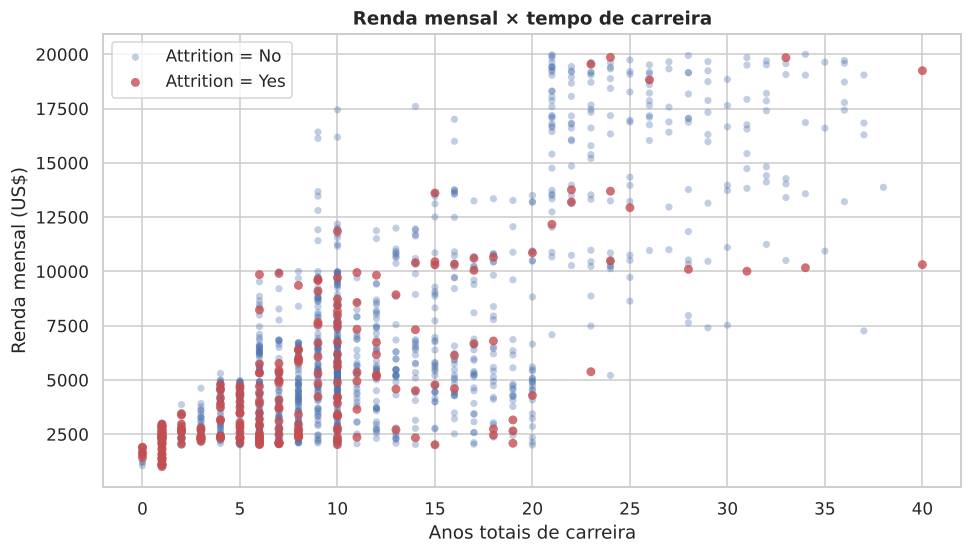

Spearman (experiência × renda): rho = 0.71 (p = 7.3e-226)
Taxa de saída com até 5 anos de carreira: 28.8% (n = 316) | com mais de 5 anos: 12.7% (n = 1154)
Entre quem tem até 5 anos de carreira e renda abaixo de US$ 3.000: taxa de saída = 34.6% (n = 208)


In [45]:
checar_vars("MonthlyIncome", "TotalWorkingYears", "Attrition")
fig, ax = plt.subplots(figsize=(9, 5.2))
for rot in ["No", "Yes"]:                                  # "Yes" por último: fica por cima
    m = df["Attrition"] == rot
    ax.scatter(df.loc[m, "TotalWorkingYears"], df.loc[m, "MonthlyIncome"], s=22 if rot == "No" else 34,
               alpha=0.35 if rot == "No" else 0.8, color=PAL[rot], label=f"Attrition = {rot}", edgecolor="none")
ax.set_xlabel("Anos totais de carreira")
ax.set_ylabel("Renda mensal (US$)")
ax.set_title("Renda mensal × tempo de carreira")
ax.legend()
plt.tight_layout()
plt.show()
rho, p = stats.spearmanr(df["TotalWorkingYears"], df["MonthlyIncome"])
print(f"Spearman (experiência × renda): rho = {rho:.2f} (p = {p:.1e})")
inicio = df["TotalWorkingYears"] <= 5
print(f"Taxa de saída com até 5 anos de carreira: {y_bin[inicio].mean():.1%} (n = {inicio.sum()}) | "
      f"com mais de 5 anos: {y_bin[~inicio].mean():.1%} (n = {(~inicio).sum()})")
print(f"Entre quem tem até 5 anos de carreira e renda abaixo de US$ 3.000: taxa de saída = "
      f"{y_bin[inicio & (df['MonthlyIncome'] < 3000)].mean():.1%} (n = {(inicio & (df['MonthlyIncome'] < 3000)).sum()})")

**Discussão:** A experiência e a renda têm correlação de Spearman de **0,71**, positiva e forte, mas a dispersão mostra que a mesma experiência rende salários muito diferentes (efeito do cargo). Quem tem até 5 anos de carreira sai a **28,8%**, contra 12,7% de quem tem mais; e entre quem tem até 5 anos **e** renda abaixo de US$ 3.000 (n = 208), a taxa sobe para **34,6%**, mais que o dobro da média. O perfil de maior risco é, portanto, o profissional jovem na carreira e com renda baixa.

### Visualização 7: `MaritalStatus` × `OverTime` × `Attrition`
**Pergunta:** o efeito da hora extra é o mesmo para solteiros, casados e divorciados?

**Hipótese:** o efeito é maior entre solteiros, que têm menos "amarras" familiares para permanecer e mais facilidade de mudar de emprego.

**Escolha do gráfico:** duas categóricas cruzadas e uma taxa como resultado -> mapa de calor com a taxa de saída e o tamanho de cada célula (n).

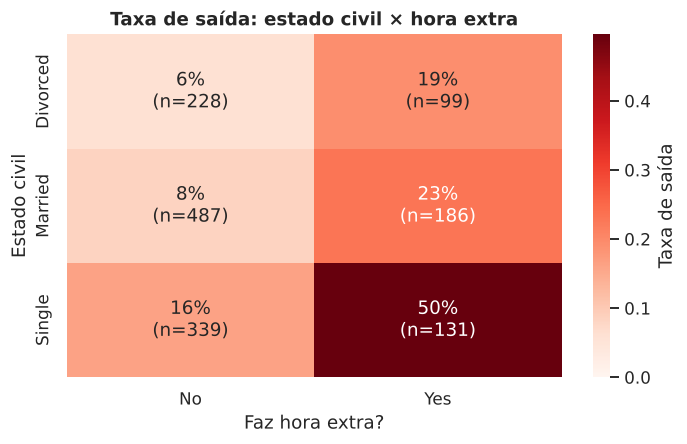

Aumento relativo da taxa de saída por causa da hora extra (com / sem):
MaritalStatus
Divorced    3.13
Married     2.75
Single      3.06


In [46]:
fig, ax = plt.subplots(figsize=(6.5, 4.2))
taxa, n = mapa_calor_taxa("MaritalStatus", "OverTime", ax, "Taxa de saída: estado civil × hora extra")
ax.set_xlabel("Faz hora extra?")
ax.set_ylabel("Estado civil")
plt.tight_layout()
plt.show()
print("Aumento relativo da taxa de saída por causa da hora extra (com / sem):")
print((taxa["Yes"] / taxa["No"]).round(2).to_string())

**Discussão:** A hora extra eleva a saída em todos os estados civis: solteiros de 16,2% para **49,6%**, casados de 8,4% para 23,1% e divorciados de 6,1% para 19,2%. A razão entre as taxas é parecida nos três grupos (cerca de 3,1x, 2,75x e 3,1x), ou seja, o efeito é **multiplicativo**, e não há interação forte. Em pontos percentuais, porém, o aumento é muito maior entre solteiros (33 pontos, contra 15 e 13), de modo que a hipótese de que o efeito seria maior para solteiros se confirma em termos absolutos, mas não em termos relativos.

### Visualização 8: `JobLevel` × `OverTime` × `Attrition`
**Pergunta:** a hora extra pesa igualmente em todos os níveis do cargo?

**Hipótese:** o efeito da hora extra é maior nos níveis mais baixos, onde a hora extra é menos valorizada e mais frequentemente vista como obrigação.

**Escolha do gráfico:** mapa de calor da taxa de saída (nível do cargo × hora extra), com n em cada célula.

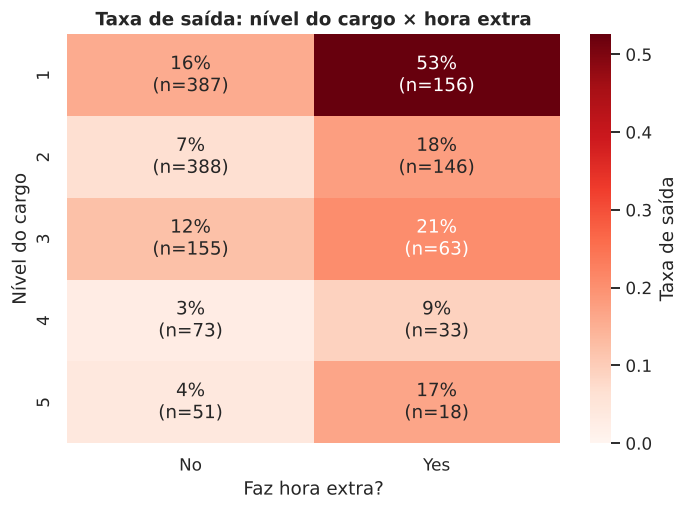

Diferença na taxa de saída (com hora extra - sem hora extra), em pontos percentuais:
JobLevel
1    36.8
2    11.1
3     8.4
4     6.4
5    12.7


In [47]:
fig, ax = plt.subplots(figsize=(6.5, 4.8))
taxa, n = mapa_calor_taxa("JobLevel", "OverTime", ax, "Taxa de saída: nível do cargo × hora extra")
ax.set_xlabel("Faz hora extra?")
ax.set_ylabel("Nível do cargo")
plt.tight_layout()
plt.show()
dif = (taxa["Yes"] - taxa["No"]) * 100
print("Diferença na taxa de saída (com hora extra - sem hora extra), em pontos percentuais:")
print(dif.round(1).to_string())

**Discussão:** A hipótese se confirma, e o efeito é bem concentrado: no nível 1, a hora extra aumenta a taxa de saída em **36,8 pontos percentuais** (53% contra 16%; n = 156 e 387). Nos demais níveis o aumento é bem menor: +11,1 (nível 2), +8,4 (nível 3), +6,4 (nível 4) e +12,7 (nível 5, apenas 18 pessoas com hora extra). A hora extra é, assim, um fator de risco sobretudo para quem está na base da pirâmide.

### Visualização 9: `AgeGroup` × `MaritalStatus` × `Attrition`
**Pergunta:** quais perfis demográficos concentram as saídas?

**Hipótese:** funcionários jovens e solteiros têm a maior taxa de saída; a taxa cai com a idade.

**Escolha do gráfico:** mapa de calor da taxa de saída por faixa etária (ordinal) e estado civil (nominal).

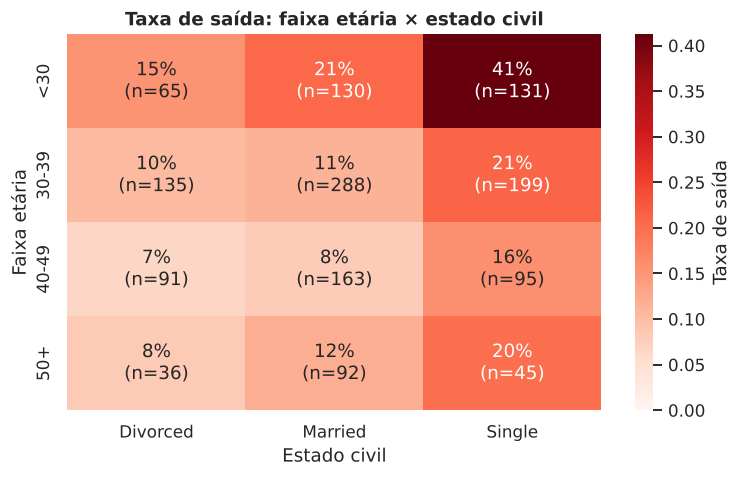

Maior taxa: ('<30', 'Single') = 41.2% (n = 131)
Taxa por faixa etária (todos os estados civis):
AgeGroup
<30      0.279
30-39    0.143
40-49    0.097
50+      0.133


In [48]:
fig, ax = plt.subplots(figsize=(7, 4.5))
taxa, n = mapa_calor_taxa("AgeGroup", "MaritalStatus", ax, "Taxa de saída: faixa etária × estado civil",
                          ordem_linhas=["<30", "30-39", "40-49", "50+"])
ax.set_xlabel("Estado civil")
ax.set_ylabel("Faixa etária")
plt.tight_layout()
plt.show()
print("Maior taxa:", taxa.stack().idxmax(), f"= {taxa.stack().max():.1%} (n = {int(n.stack()[taxa.stack().idxmax()])})")
print("Taxa por faixa etária (todos os estados civis):")
print((y_bin.groupby(df["AgeGroup"], observed=True).mean()).round(3).to_string())

**Discussão:** A taxa de saída é maior entre os mais jovens e entre os solteiros: o grupo **menores de 30 anos solteiros chega a 41,2%** (n = 131). A relação com a idade, porém, **não é monotônica**: <30 anos 27,9%, 30-39 anos 14,3%, 40-49 anos 9,7% e 50+ 13,3% (a taxa volta a subir depois dos 50). Entre os solteiros a taxa por faixa é 41%, 21%, 16% e 20%. A hipótese de que a idade reduz a saída vale até os 49 anos, mas não depois disso, onde os grupos são pequenos e mais incertos.

### Visualização 10: `DailyRate` × `MonthlyIncome` (comportamento não óbvio)
**Pergunta:** a "taxa diária" (`DailyRate`) tem relação com a renda mensal?

**Hipótese:** deveria ter uma relação positiva forte: quem tem taxa diária alta deveria ter renda mensal alta. Se isso não ocorrer, a variável não representa a remuneração real e carrega pouca informação útil.

**Escolha do gráfico:** duas numéricas -> dispersão com hexbin (muitos pontos sobrepostos) e correlações de Pearson e Spearman.

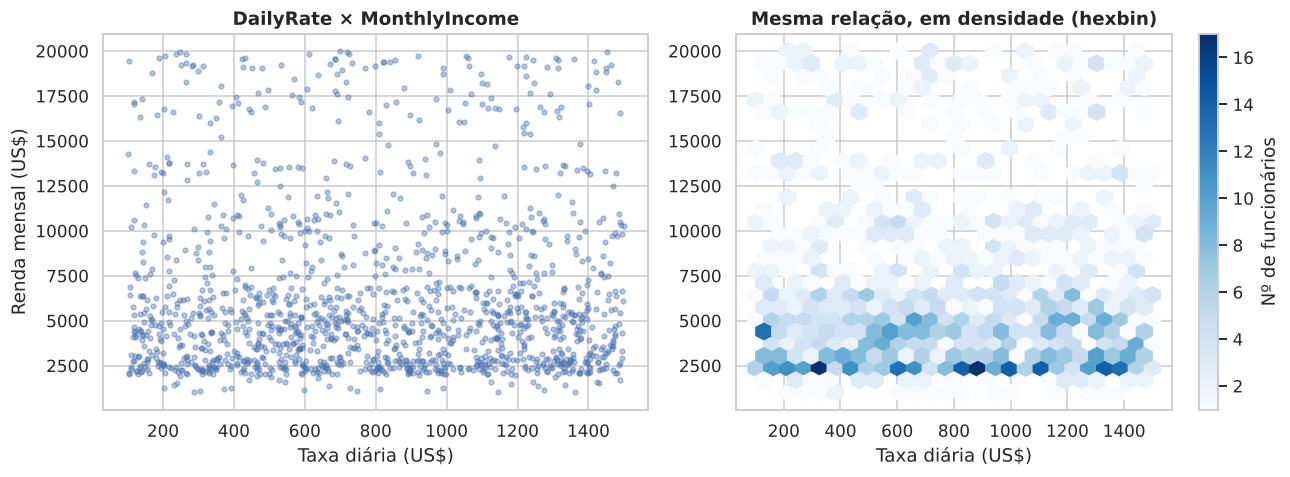

Pearson r = 0.008 (p = 0.77) | Spearman rho = 0.016 (p = 0.53)
Em comparação, experiência × renda: Spearman rho = 0.71


In [49]:
checar_vars("DailyRate", "MonthlyIncome")
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].scatter(df["DailyRate"], df["MonthlyIncome"], s=10, alpha=0.4, color="#4C72B0")
ax[0].set_title("DailyRate × MonthlyIncome")
ax[0].set_xlabel("Taxa diária (US$)")
ax[0].set_ylabel("Renda mensal (US$)")
hb = ax[1].hexbin(df["DailyRate"], df["MonthlyIncome"], gridsize=25, cmap="Blues", mincnt=1)
fig.colorbar(hb, ax=ax[1], label="Nº de funcionários")
ax[1].set_title("Mesma relação, em densidade (hexbin)")
ax[1].set_xlabel("Taxa diária (US$)")
plt.tight_layout()
plt.show()
r, pr = stats.pearsonr(df["DailyRate"], df["MonthlyIncome"])
rho, ps = stats.spearmanr(df["DailyRate"], df["MonthlyIncome"])
print(f"Pearson r = {r:.3f} (p = {pr:.2f}) | Spearman rho = {rho:.3f} (p = {ps:.2f})")
print(f"Em comparação, experiência × renda: Spearman rho = {stats.spearmanr(df['TotalWorkingYears'], df['MonthlyIncome'])[0]:.2f}")

**Discussão:** A hipótese de que cargos com maior renda mensal teriam maior taxa diária **não se confirma**: a correlação de Pearson é 0,008 (p = 0,77) e a de Spearman 0,016 (p = 0,53), ou seja, nula. Em comparação, experiência e renda têm ρ = 0,71. Isso reforça que `DailyRate` parece ser uma variável sem sentido de negócio (uniforme e independente de tudo), e não deve ser usada como indicador de remuneração. Essa é uma observação importante de qualidade de dados.

### Visualização 11: `SatisfactionIndex` × `OverTime` × `Attrition`
**Pergunta:** quem sai é menos satisfeito? A hora extra "explica" a insatisfação?

**Hipótese:** quem sai tem satisfação menor. Se a hora extra fosse a causa da insatisfação, a diferença entre quem sai e quem fica desapareceria dentro de cada grupo de hora extra.

**Escolha do gráfico:** numérica (índice) por duas categóricas -> boxplots agrupados (uma caixa para cada combinação).

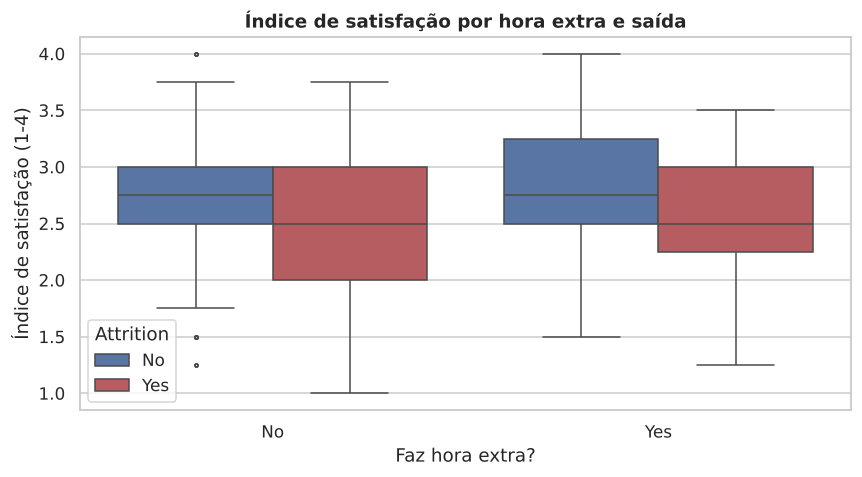

OverTime = No: média saíram = 2.46 | ficaram = 2.74 | Mann-Whitney p = 8.6e-07
OverTime = Yes: média saíram = 2.62 | ficaram = 2.86 | Mann-Whitney p = 1.3e-05
Correlação de Spearman (índice × saída) = -0.15 (p = 1.3e-08)


In [50]:
checar_vars("SatisfactionIndex", "OverTime", "Attrition")
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.boxplot(data=df, x="OverTime", y="SatisfactionIndex", hue="Attrition", palette=PAL, ax=ax, fliersize=2)
ax.set_title("Índice de satisfação por hora extra e saída")
ax.set_xlabel("Faz hora extra?")
ax.set_ylabel("Índice de satisfação (1-4)")
plt.tight_layout()
plt.show()
for ot, g in df.groupby("OverTime", observed=True):
    a, b = g.loc[g["Attrition"] == "Yes", "SatisfactionIndex"], g.loc[g["Attrition"] == "No", "SatisfactionIndex"]
    print(f"OverTime = {ot}: média saíram = {a.mean():.2f} | ficaram = {b.mean():.2f} | "
          f"Mann-Whitney p = {stats.mannwhitneyu(a, b).pvalue:.1e}")
rho, p = stats.spearmanr(df["SatisfactionIndex"], y_bin)
print(f"Correlação de Spearman (índice × saída) = {rho:.2f} (p = {p:.1e})")

**Discussão:** A hipótese se confirma: quem saiu tem satisfação média menor, e a diferença persiste dentro de cada grupo de hora extra: sem hora extra, **2,46 contra 2,74** (p ≈ 9e-7); com hora extra, **2,62 contra 2,86** (p ≈ 1e-5). A correlação de Spearman entre o índice e a saída é -0,15 (p ≈ 1e-8), um efeito pequeno, mas consistente. Curiosamente, quem faz hora extra relata satisfação média um pouco maior, de modo que a hora extra e a baixa satisfação são fatores de risco **independentes**, e não o mesmo fenômeno.

### Visualização 12: PCA das variáveis numéricas e ordinais
**Pergunta:** existe uma estrutura de poucas dimensões que resuma os funcionários? Ela separa quem sai de quem fica?

**Hipótese:** a primeira componente principal captura um eixo de "senioridade" (idade, experiência, cargo, renda), e quem sai se concentra no lado "júnior" desse eixo.

**Escolha do gráfico:** PCA (redução linear de dimensionalidade, calculada com `numpy`) sobre as 20 variáveis numéricas/ordinais padronizadas; dispersão das duas primeiras componentes com a cor do alvo, e variância explicada (scree plot).

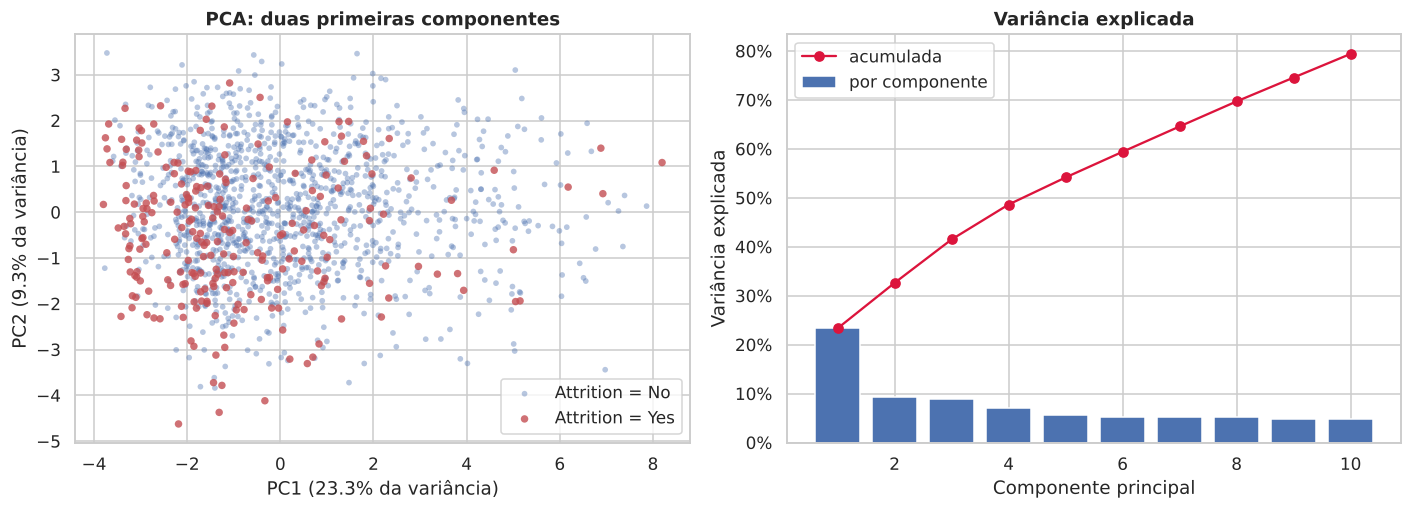

Variáveis com maior peso em PC1 (eixo 1):


,PC1,PC2
TotalWorkingYears,0.41,-0.01
YearsAtCompany,0.39,-0.02
JobLevel,0.38,0.06
MonthlyIncome,0.37,0.05
YearsInCurrentRole,0.34,-0.01
YearsWithCurrManager,0.33,-0.05


Variáveis com maior peso em PC2 (eixo 2):


,PC1,PC2
SatisfactionIndex,0.01,0.70
EnvironmentSatisfaction,0.00,0.46
JobSatisfaction,-0.01,0.43
WorkLifeBalance,0.01,0.31


PC1: média de quem saiu = -0.95 | de quem ficou = 0.18 | Mann-Whitney p = 2.0e-17
PC2: média de quem saiu = -0.48 | de quem ficou = 0.09 | Mann-Whitney p = 1.9e-08
Variância acumulada nas 2 primeiras componentes: 32.6% | nas 5 primeiras: 54.2%


In [51]:
checar_vars(*VARS_NUM_ORD)
# PCA "na mão" com numpy: padroniza as variáveis, calcula a matriz de correlação e seus autovetores (as componentes).
# Cada autovalor mede a variância explicada pela componente correspondente.
dados = df[VARS_NUM_ORD]
Z = ((dados - dados.mean()) / dados.std(ddof=0)).values
autovalores, autovetores = np.linalg.eigh(np.corrcoef(Z, rowvar=False))
ordem = np.argsort(autovalores)[::-1]                                    # da maior para a menor variância
autovalores, autovetores = autovalores[ordem], autovetores[:, ordem]
autovetores = autovetores * np.sign(autovetores[np.abs(autovetores).argmax(axis=0), range(autovetores.shape[1])])  # sinal: maior peso positivo
var_exp = autovalores / autovalores.sum()                                # fração da variância de cada componente
coords = Z @ autovetores                                                 # posição de cada funcionário nas componentes

fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
for rot in ["No", "Yes"]:
    m = (df["Attrition"] == rot).values
    ax[0].scatter(coords[m, 0], coords[m, 1], s=14 if rot == "No" else 24, alpha=0.4 if rot == "No" else 0.8,
                  color=PAL[rot], label=f"Attrition = {rot}", edgecolor="none")
ax[0].set_xlabel(f"PC1 ({var_exp[0]:.1%} da variância)")
ax[0].set_ylabel(f"PC2 ({var_exp[1]:.1%} da variância)")
ax[0].set_title("PCA: duas primeiras componentes")
ax[0].legend()
k = 10
ax[1].bar(range(1, k + 1), var_exp[:k], color="#4C72B0", label="por componente")
ax[1].plot(range(1, k + 1), np.cumsum(var_exp)[:k], marker="o", color="crimson", label="acumulada")
ax[1].set_xlabel("Componente principal")
ax[1].set_ylabel("Variância explicada")
ax[1].set_title("Variância explicada")
ax[1].yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax[1].legend()
plt.tight_layout()
plt.show()

carga = pd.DataFrame(autovetores[:, :2], index=VARS_NUM_ORD, columns=["PC1", "PC2"])
print("Variáveis com maior peso em PC1 (eixo 1):")
display(carga.reindex(carga["PC1"].abs().sort_values(ascending=False).index).head(6).round(2))
print("Variáveis com maior peso em PC2 (eixo 2):")
display(carga.reindex(carga["PC2"].abs().sort_values(ascending=False).index).head(4).round(2))
for i, nome in enumerate(["PC1", "PC2"]):
    a, b = coords[(df["Attrition"] == "Yes").values, i], coords[(df["Attrition"] == "No").values, i]
    print(f"{nome}: média de quem saiu = {a.mean():.2f} | de quem ficou = {b.mean():.2f} | Mann-Whitney p = {stats.mannwhitneyu(a, b).pvalue:.1e}")
print(f"Variância acumulada nas 2 primeiras componentes: {var_exp[:2].sum():.1%} | nas 5 primeiras: {var_exp[:5].sum():.1%}")

**Discussão:** A PCA com as variáveis numéricas e ordinais resume 32,6% da variância em dois componentes (e 54,2% em cinco), o que mostra que os dados são pouco redundantes fora do bloco de carreira. **PC1 (23,3%) é um eixo de senioridade** (TotalWorkingYears, YearsAtCompany, JobLevel e MonthlyIncome com cargas de 0,37 a 0,41); **PC2 (9,3%) é um eixo de satisfação** (SatisfactionIndex com carga de 0,70). Quem saiu tem PC1 médio de -0,95, contra +0,18 de quem ficou (p ≈ 2e-17), e PC2 de -0,48 contra +0,09 (p ≈ 2e-8): quem sai é menos sênior e menos satisfeito, mas as duas populações se sobrepõem bastante.

### Visualização 13: vizinhança dos funcionários (k vizinhos mais próximos)
**Pergunta:** funcionários parecidos em todas as variáveis numéricas/ordinais tendem a ter o mesmo destino? Quem sai forma um grupo próprio?

**Hipótese:** existe alguma tendência de "semelhante sai junto", mas quem sai **não** forma um aglomerado isolado, porque a saída depende de muitos fatores combinados.

**Escolha do gráfico:** barras agrupadas. Para cada funcionário, calculamos a distância (euclidiana, com as variáveis padronizadas) até todos os outros e olhamos os *k* mais próximos. As barras mostram a fração de vizinhos que saíram, separando quem saiu de quem ficou, para diferentes valores de *k*. A linha tracejada é a taxa-base da empresa: se os dois grupos tivessem a mesma vizinhança, as barras ficariam sobre ela.

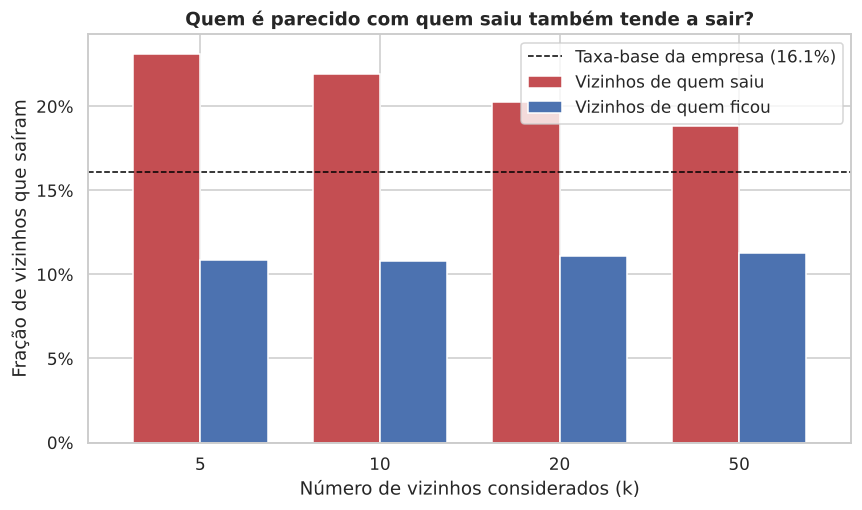

,Vizinhos de quem saiu,Vizinhos de quem ficou
k,,
5,23.1%,10.9%
10,21.9%,10.8%
20,20.3%,11.1%
50,18.9%,11.3%


Entre os 10 vizinhos mais próximos de quem saiu, 21.9% também saíram (taxa-base da empresa: 16.1%).
Entre os 10 vizinhos mais próximos de quem ficou, 10.8% saíram.


In [52]:
checar_vars(*VARS_NUM_ORD)
# matriz de distâncias entre todos os pares de funcionários (n x n), com numpy
dif = Z[:, None, :] - Z[None, :, :]
dist = np.sqrt((dif ** 2).sum(axis=2))
np.fill_diagonal(dist, np.inf)                       # um funcionário não é vizinho de si mesmo
ordem_viz = np.argsort(dist, axis=1)                 # vizinhos de cada funcionário, do mais perto ao mais longe
saiu = y_bin.values

ks = [5, 10, 20, 50]
linhas = []
for k in ks:
    frac = saiu[ordem_viz[:, :k]].mean(axis=1)       # fração de vizinhos que saíram
    linhas.append({"k": k, "Vizinhos de quem saiu": frac[saiu == 1].mean(), "Vizinhos de quem ficou": frac[saiu == 0].mean()})
viz = pd.DataFrame(linhas).set_index("k")

fig, ax = plt.subplots(figsize=(8, 4.8))
viz.plot(kind="bar", ax=ax, color=[PAL["Yes"], PAL["No"]], width=0.75)
ax.axhline(y_bin.mean(), color="black", ls="--", lw=1, label=f"Taxa-base da empresa ({y_bin.mean():.1%})")
ax.set_xlabel("Número de vizinhos considerados (k)")
ax.set_ylabel("Fração de vizinhos que saíram")
ax.set_title("Quem é parecido com quem saiu também tende a sair?")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
plt.xticks(rotation=0)
ax.legend(title="")
plt.tight_layout()
plt.show()
display((viz * 100).round(1).astype(str) + "%")
print(f"Entre os 10 vizinhos mais próximos de quem saiu, {viz.loc[10, 'Vizinhos de quem saiu']:.1%} também saíram "
      f"(taxa-base da empresa: {y_bin.mean():.1%}).")
print(f"Entre os 10 vizinhos mais próximos de quem ficou, {viz.loc[10, 'Vizinhos de quem ficou']:.1%} saíram.")

**Discussão:** Não há um grupo isolado de saídas, mas há alguma estrutura. Entre os 10 vizinhos mais próximos de quem saiu, **21,9%** também saíram, contra a taxa-base de 16,1% (1,4 vez maior); entre os vizinhos de quem ficou, só **10,8%** saíram. O padrão se repete para k = 5 (23,1% contra 10,9%), k = 20 (20,3% contra 11,1%) e k = 50 (18,9% contra 11,3%), e a fração diminui conforme k cresce, o que indica que a semelhança é local. Ou seja, funcionários parecidos tendem a ter o mesmo destino, mas mesmo os vizinhos de quem saiu ficam em maioria (cerca de 78%): a saída depende de muitos fatores combinados, e um modelo preditivo não deve esperar separação perfeita.

### Visualização 14: quais variáveis numéricas/ordinais mais distinguem quem sai de quem fica?
**Pergunta:** olhando todas as variáveis numéricas e ordinais ao mesmo tempo, quais têm maior poder de separar quem sai de quem fica, e quais, apesar de parecerem importantes, não separam nada?

**Hipótese:** as variáveis de carreira/renda (idade, experiência, nível, renda) têm o maior efeito; as de satisfação têm efeito menor; "distância de casa", "% de aumento" e "anos desde a última promoção" **não** têm efeito relevante, ao contrário da intuição de negócio.

**Escolha do gráfico:** barras horizontais com o tamanho de efeito de cada variável. Usamos a *probabilidade de superioridade* do teste de Mann-Whitney: probabilidade de que uma pessoa que **ficou** tenha valor maior que uma que **saiu** (0,5 = nenhuma diferença; quanto mais distante de 0,5, maior o efeito). Barras escuras = diferença estatisticamente significativa (p < 0,05, sem correção para múltiplos testes).

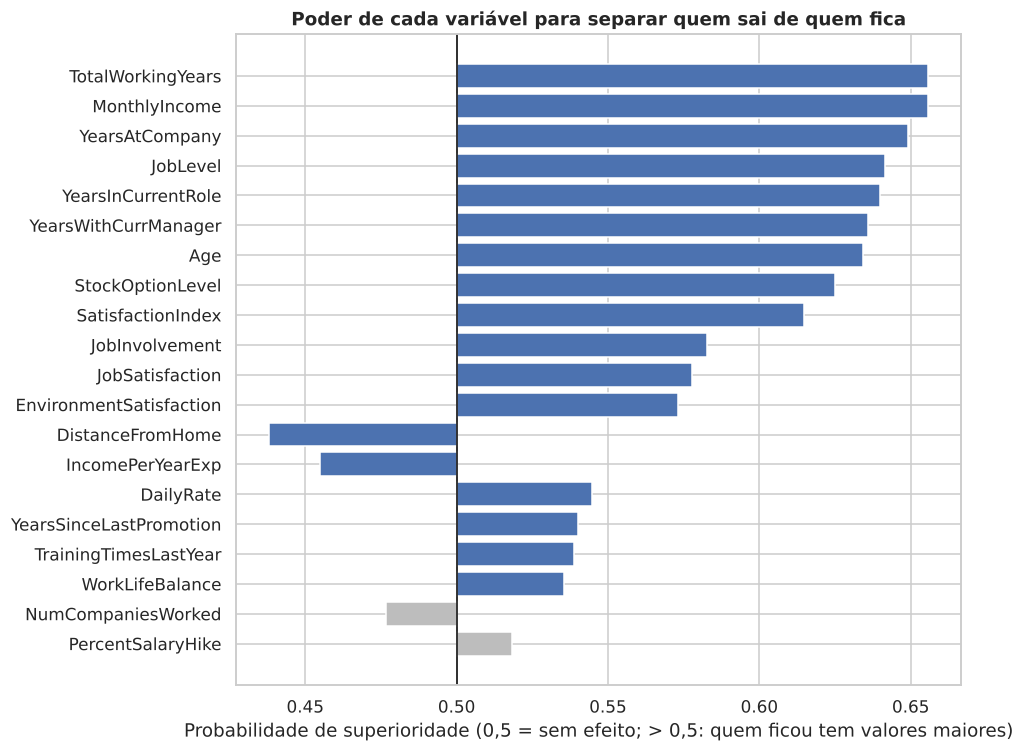

,prob_superioridade,p,|efeito|
variável,,,
TotalWorkingYears,0.656,2.4e-14,0.156
MonthlyIncome,0.656,3.0e-14,0.156
YearsAtCompany,0.649,2.9e-13,0.149
JobLevel,0.642,3.0e-13,0.142
YearsInCurrentRole,0.640,4.4e-12,0.140
YearsWithCurrManager,0.636,1.8e-11,0.136
Age,0.634,5.3e-11,0.134
StockOptionLevel,0.625,4.0e-11,0.125
SatisfactionIndex,0.615,1.5e-08,0.115


Taxa de saída por nº de empresas anteriores (relação não monotônica):
NumCompaniesWorked
0      0.117
1      0.188
2-4    0.110
5-9    0.218
Sem diferença significativa (p >= 0,05): ['PercentSalaryHike', 'NumCompaniesWorked']
Variáveis com efeito muito pequeno (|prob - 0,5| < 0,05) mesmo se significativas: ['WorkLifeBalance', 'TrainingTimesLastYear', 'YearsSinceLastPromotion', 'DailyRate', 'IncomePerYearExp']


In [53]:
checar_vars(*VARS_NUM_ORD, "Attrition")
sai = (df["Attrition"] == "Yes").values
linhas = []
for c in VARS_NUM_ORD:
    a, b = df.loc[~sai, c].values, df.loc[sai, c].values          # a = ficaram, b = saíram
    u = stats.mannwhitneyu(a, b)
    linhas.append({"variável": c, "prob_superioridade": u.statistic / (len(a) * len(b)), "p": u.pvalue})
efeito = pd.DataFrame(linhas).set_index("variável")
efeito["|efeito|"] = (efeito["prob_superioridade"] - 0.5).abs()
efeito = efeito.sort_values("|efeito|")

fig, ax = plt.subplots(figsize=(9, 7))
cores = [PAL["No"] if p < 0.05 else "#BDBDBD" for p in efeito["p"]]
ax.barh(efeito.index, efeito["prob_superioridade"] - 0.5, left=0.5, color=cores)
ax.axvline(0.5, color="black", lw=1)
ax.set_xlabel("Probabilidade de superioridade (0,5 = sem efeito; > 0,5: quem ficou tem valores maiores)")
ax.set_title("Poder de cada variável para separar quem sai de quem fica")
plt.tight_layout()
plt.show()
tab_ef = efeito.sort_values("|efeito|", ascending=False).copy()
tab_ef["p"] = tab_ef["p"].map(lambda v: f"{v:.1e}")
display(tab_ef.round(3))
print("Taxa de saída por nº de empresas anteriores (relação não monotônica):")
print(y_bin.groupby(pd.cut(df["NumCompaniesWorked"], [-1, 0, 1, 4, 9], labels=["0", "1", "2-4", "5-9"]), observed=True).mean().round(3).to_string())
sem_efeito = efeito[efeito["p"] >= 0.05].index.tolist()
print("Sem diferença significativa (p >= 0,05):", sem_efeito)
print("Variáveis com efeito muito pequeno (|prob - 0,5| < 0,05) mesmo se significativas:",
      efeito[(efeito["|efeito|"] < 0.05) & (efeito["p"] < 0.05)].index.tolist())

**Discussão:** Ordenando pelo tamanho do efeito (probabilidade de superioridade), as variáveis de **senioridade e renda lideram**: TotalWorkingYears e MonthlyIncome (0,656), YearsAtCompany (0,649), JobLevel (0,642), YearsInCurrentRole (0,640), YearsWithCurrManager (0,636), Age (0,634), StockOptionLevel (0,625) e SatisfactionIndex (0,615). A hipótese de que DistanceFromHome não teria efeito é **refutada**: o efeito é pequeno, mas significativo (0,44; p = 0,002), e quem sai mora um pouco mais longe. PercentSalaryHike e NumCompaniesWorked não têm diferença significativa; porém, NumCompaniesWorked tem relação **não monotônica** (0 empresas: 11,7%; 1: 18,8%; 2-4: 11,0%; 5-9: 21,8%), o que explica por que a informação mútua é intermediária enquanto o teste de Mann-Whitney não encontra diferença. WorkLifeBalance, TrainingTimesLastYear, YearsSinceLastPromotion, DailyRate e IncomePerYearExp são significativas, mas com efeito muito pequeno.

# Gráficos Finais (Visualização Eficaz de Dados)

Nesta seção, você deve **aprimorar 5 visualizações multivariadas** apresentadas na seção anterior do relatório.
O objetivo é melhorá-las para que possam ser apresentadas efetivamente a um público não familiarizado com o conjunto de dados ou com análise de dados.
**Portanto, certifique-se de que tamanho, cores, texturas e outros elementos visuais sejam adequados e transmitam a informação pretendida ao público.**

Para cada gráfico final, siga estas etapas:
1. Apresente o gráfico;
2. Forneça uma descrição da visualização, destacando as principais conclusões que podem ser extraídas dela.


**Dica**: consulte o checklist baseado no trabalho de Evergreen para garantir que suas visualizações sigam as melhores práticas de clareza e impacto.

### Princípios aplicados (checklist de Evergreen)

- **Texto:** o título diz a conclusão (não apenas o assunto), há subtítulo explicando a métrica, rótulos diretos nos elementos (sem depender de legendas) e fonte e tamanho da amostra no rodapé; fontes grandes o bastante para projeção.
- **Disposição:** categorias ordenadas pelo valor (e não alfabeticamente), eixo de leitura natural (barras horizontais para nomes longos).
- **Cor:** uma cor de destaque (vermelho = saída) para o que importa e cinza para o contexto; mesma convenção em todos os gráficos; contraste suficiente.
- **Linhas e ruído:** sem bordas, grades e eixos desnecessários; o rótulo do valor substitui o eixo.
- **Geral:** cada gráfico responde a uma única pergunta e dispensa explicação oral.

In [54]:
# seu código vai aqui
COR_DESTAQUE = "#C44E52"      # vermelho: o que queremos destacar (saída)
COR_CONTEXTO = "#BDBDBD"      # cinza: contexto
COR_TEXTO = "#333333"
FONTE = f"Fonte: IBM HR Analytics Employee Attrition & Performance (Kaggle; base fictícia). n = {len(df):,} funcionários."


def titulos_finais(fig, titulo, subtitulo):
    """Título que diz a conclusão (com quebra de linha automática) + subtítulo com a métrica + fonte no rodapé."""
    linhas = textwrap.wrap(titulo, int(fig.get_figwidth() * 6.6))
    fig.text(0.01, 0.975, "\n".join(linhas), ha="left", va="top", fontsize=16, fontweight="bold",
             color=COR_TEXTO, linespacing=1.15)
    y_sub = 0.975 - 0.052 * len(linhas) - 0.012
    fig.text(0.01, y_sub, subtitulo, ha="left", va="top", fontsize=11.5, color="#666666")
    fig.text(0.01, 0.01, FONTE, ha="left", va="bottom", fontsize=8.5, color="#888888")

### Gráfico final 1: hora extra e saída (aprimora a Visualização 1)
Pergunta do público: *"Hora extra faz as pessoas irem embora?"*

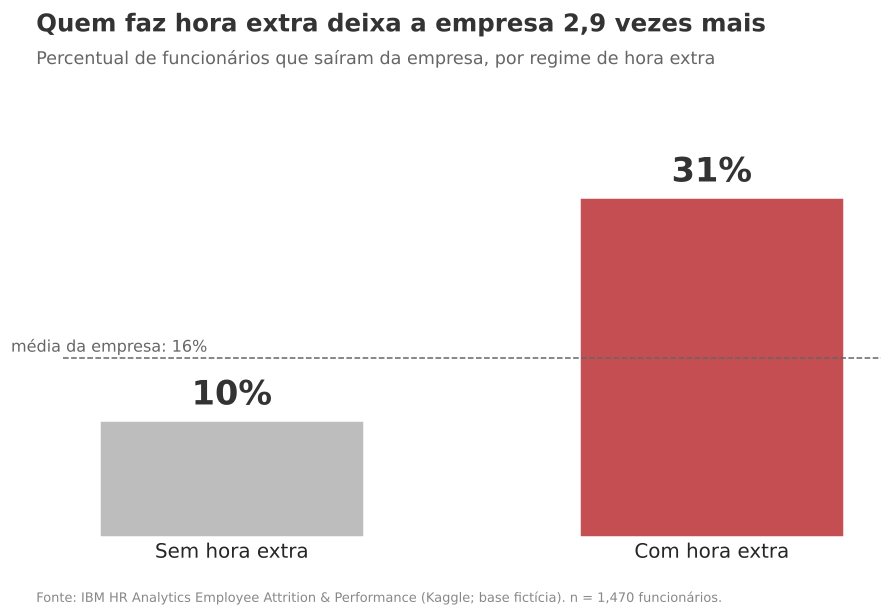

In [55]:
checar_vars("OverTime", "Attrition")
taxa_ot = y_bin.groupby(df["OverTime"], observed=True).mean()
razao = taxa_ot["Yes"] / taxa_ot["No"]

fig, ax = plt.subplots(figsize=(8, 5.6))
barras = ax.bar(["Sem hora extra", "Com hora extra"], [taxa_ot["No"], taxa_ot["Yes"]],
                color=[COR_CONTEXTO, COR_DESTAQUE], width=0.55)
for b in barras:
    ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.008, f"{b.get_height():.0%}",
            ha="center", va="bottom", fontsize=22, fontweight="bold", color=COR_TEXTO)
ax.axhline(y_bin.mean(), color="#666666", ls="--", lw=1)
ax.text(-0.46, y_bin.mean() + 0.006, f"média da empresa: {y_bin.mean():.0%}", ha="left", fontsize=10.5, color="#666666")
ax.set_ylim(0, taxa_ot.max() * 1.2)
ax.set_yticks([])
ax.tick_params(axis="x", labelsize=13, length=0)
sns.despine(left=True, bottom=True)
ax.grid(False)
fig.subplots_adjust(top=0.78, bottom=0.12, left=0.04, right=0.97)
titulos_finais(fig, f"Quem faz hora extra deixa a empresa {razao:.1f} vezes mais".replace(".", ","),
               "Percentual de funcionários que saíram da empresa, por regime de hora extra")
plt.show()

**Conclusão:** Quem faz hora extra deixa a empresa 2,9 vezes mais (30,5% contra 10,4%). É a variável categórica com maior associação com a saída e uma das poucas diretamente ajustáveis pela gestão. Recomendação: priorizar a revisão da carga de trabalho, começando pelos níveis iniciais (ver gráfico 4).

### Gráfico final 2: a função importa (aprimora a Visualização 2)
Pergunta do público: *"Onde a empresa mais perde gente?"*

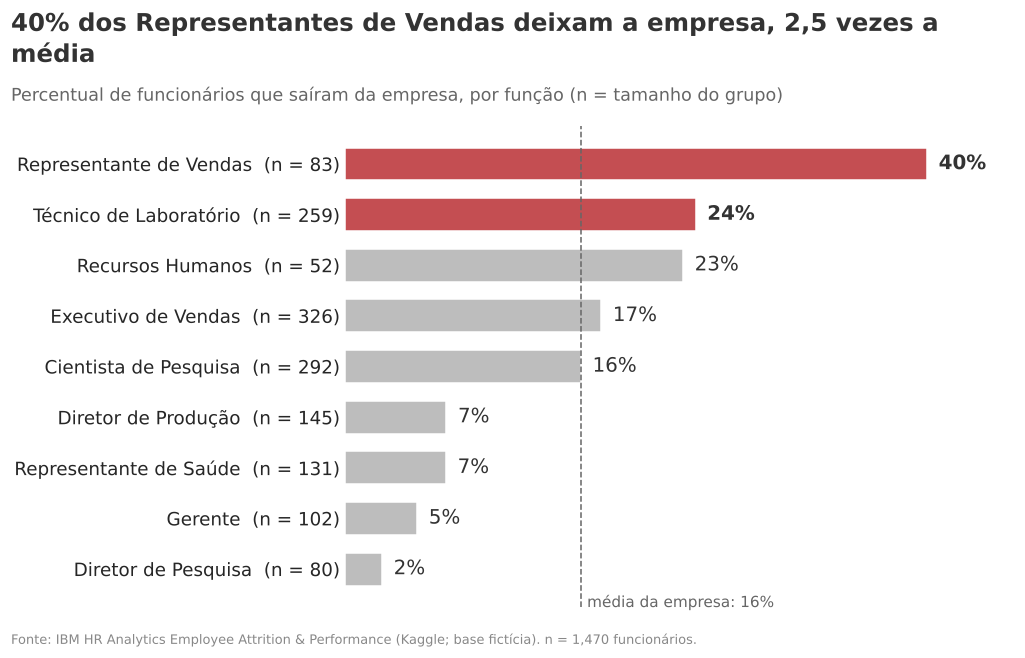

In [56]:
checar_vars("JobRole", "Attrition")
tx = y_bin.groupby(df["JobRole"], observed=True).agg(["mean", "size"]).sort_values("mean", ascending=True)
destaque = tx["mean"].nlargest(2).index
cores = [COR_DESTAQUE if i in destaque else COR_CONTEXTO for i in tx.index]
nomes_pt = {"Sales Representative": "Representante de Vendas", "Laboratory Technician": "Técnico de Laboratório",
            "Human Resources": "Recursos Humanos", "Sales Executive": "Executivo de Vendas",
            "Research Scientist": "Cientista de Pesquisa", "Manufacturing Director": "Diretor de Produção",
            "Healthcare Representative": "Representante de Saúde", "Manager": "Gerente",
            "Research Director": "Diretor de Pesquisa"}
plural_pt = {"Sales Representative": "Representantes de Vendas", "Laboratory Technician": "Técnicos de Laboratório",
             "Human Resources": "profissionais de RH", "Sales Executive": "Executivos de Vendas",
             "Research Scientist": "Cientistas de Pesquisa", "Manufacturing Director": "Diretores de Produção",
             "Healthcare Representative": "Representantes de Saúde", "Manager": "Gerentes",
             "Research Director": "Diretores de Pesquisa"}

fig, ax = plt.subplots(figsize=(9.5, 6))
ax.barh([f"{nomes_pt.get(str(i), str(i))}  (n = {n})" for i, n in zip(tx.index, tx["size"])], tx["mean"],
        color=cores, height=0.65)
for i, m_ in enumerate(tx["mean"]):
    ax.text(m_ + 0.008, i, f"{m_:.0%}", va="center", fontsize=13,
            fontweight="bold" if tx.index[i] in destaque else "normal", color=COR_TEXTO)
ax.axvline(y_bin.mean(), color="#666666", ls="--", lw=1)
ax.text(y_bin.mean() + 0.004, -0.75, f"média da empresa: {y_bin.mean():.0%}", fontsize=10, color="#666666")
ax.set_xlim(0, tx["mean"].max() * 1.15)
ax.set_xticks([])
ax.tick_params(axis="y", labelsize=12, length=0)
sns.despine(left=True, bottom=True)
ax.grid(False)
fig.subplots_adjust(top=0.80, bottom=0.07, left=0.33, right=0.97)
topo = tx.index[-1]
titulos_finais(fig, f"{tx['mean'].iloc[-1]:.0%} dos {plural_pt.get(str(topo), topo)} deixam a empresa, "
                    f"{tx['mean'].iloc[-1] / y_bin.mean():.1f} vezes a média".replace(".", ","),
               "Percentual de funcionários que saíram da empresa, por função (n = tamanho do grupo)")
plt.show()

**Conclusão:** A saída é concentrada em poucas funções: Representantes de Vendas (cerca de 40%), Técnicos de Laboratório (24%) e RH (23%) ficam acima da média de 16%, enquanto gestão e direção de pesquisa ficam abaixo de 5%. Recomendação: concentrar ações de retenção nas funções de entrada de Vendas e Laboratório, lembrando que RH tem apenas 52 pessoas.

### Gráfico final 3: o salário "explica" a saída? (aprimora a Visualização 4)
Pergunta do público: *"Quem sai ganha menos porque é mal pago ou porque está num cargo mais baixo?"*

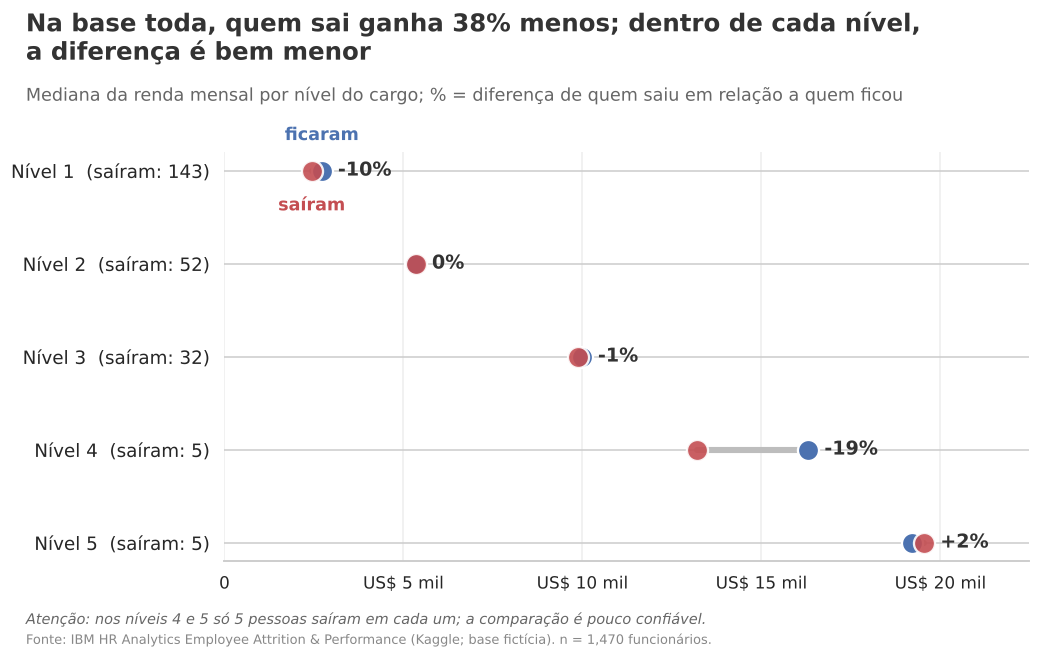

In [57]:
checar_vars("MonthlyIncome", "JobLevel", "Attrition")
med = df.groupby(["JobLevel", "Attrition"], observed=True)["MonthlyIncome"].median().unstack()
n_sai = df[df["Attrition"] == "Yes"].groupby("JobLevel").size()
geral = df.groupby("Attrition", observed=True)["MonthlyIncome"].median()
dif_geral = 100 * (geral["Yes"] / geral["No"] - 1)

fig, ax = plt.subplots(figsize=(9.5, 6))
pos = np.arange(len(med))
for i, nv in enumerate(med.index):
    ax.plot([med.loc[nv, "Yes"], med.loc[nv, "No"]], [i, i], color=COR_CONTEXTO, lw=4, zorder=1, solid_capstyle="round")
ax.scatter(med["No"], pos, s=190, color="#4C72B0", zorder=2, edgecolor="white", linewidth=1.5)
ax.scatter(med["Yes"], pos, s=190, color=COR_DESTAQUE, zorder=3, alpha=0.9, edgecolor="white", linewidth=1.5)
for i, nv in enumerate(med.index):
    d_pct = 100 * (med.loc[nv, "Yes"] / med.loc[nv, "No"] - 1)
    rot_pct = "0%" if abs(d_pct) < 0.5 else f"{d_pct:+.0f}%"
    ax.text(max(med.loc[nv]) + 450, i, rot_pct, va="center", fontsize=12.5, color=COR_TEXTO, fontweight="bold")
ax.annotate("ficaram", (med.loc[1, "No"], 0), xytext=(0, 20), textcoords="offset points", ha="center", color="#4C72B0", fontsize=11.5, fontweight="bold")
ax.annotate("saíram", (med.loc[1, "Yes"], 0), xytext=(0, -26), textcoords="offset points", ha="center", color=COR_DESTAQUE, fontsize=11.5, fontweight="bold")
ax.set_yticks(pos)
ax.set_yticklabels([f"Nível {nv}  (saíram: {n_sai.get(nv, 0)})" for nv in med.index], fontsize=12)
ax.invert_yaxis()
ax.xaxis.set_major_locator(mtick.MultipleLocator(5000))
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"US$ {v / 1000:.0f} mil" if v else "0"))
ax.tick_params(axis="x", labelsize=11)
ax.set_xlim(0, med.values.max() * 1.15)
sns.despine(left=True)
ax.grid(axis="x", color="#EEEEEE")
ax.set_axisbelow(True)
fig.subplots_adjust(top=0.76, bottom=0.14, left=0.2, right=0.97)
fig.text(0.01, 0.045, "Atenção: nos níveis 4 e 5 só 5 pessoas saíram em cada um; a comparação é pouco confiável.",
         fontsize=9.5, color="#666666", style="italic")
titulos_finais(fig, f"Na base toda, quem sai ganha {abs(dif_geral):.0f}% menos; dentro de cada nível, a diferença é bem menor",
               "Mediana da renda mensal por nível do cargo; % = diferença de quem saiu em relação a quem ficou")
plt.show()

**Conclusão:** Na base toda, quem sai ganha 38% menos, mas dentro de cada nível a diferença é pequena (cerca de 10% no nível 1 e perto de zero nos níveis 2 e 3). Os níveis 4 e 5 têm apenas 5 saídas cada e não permitem concluir. A 'renda baixa' é, em grande parte, 'cargo baixo': aumentar salário sem rever carreira tende a ter efeito limitado.

### Gráfico final 4: hora extra por nível do cargo (aprimora a Visualização 8)
Pergunta do público: *"Em quais cargos a hora extra é mais perigosa?"*

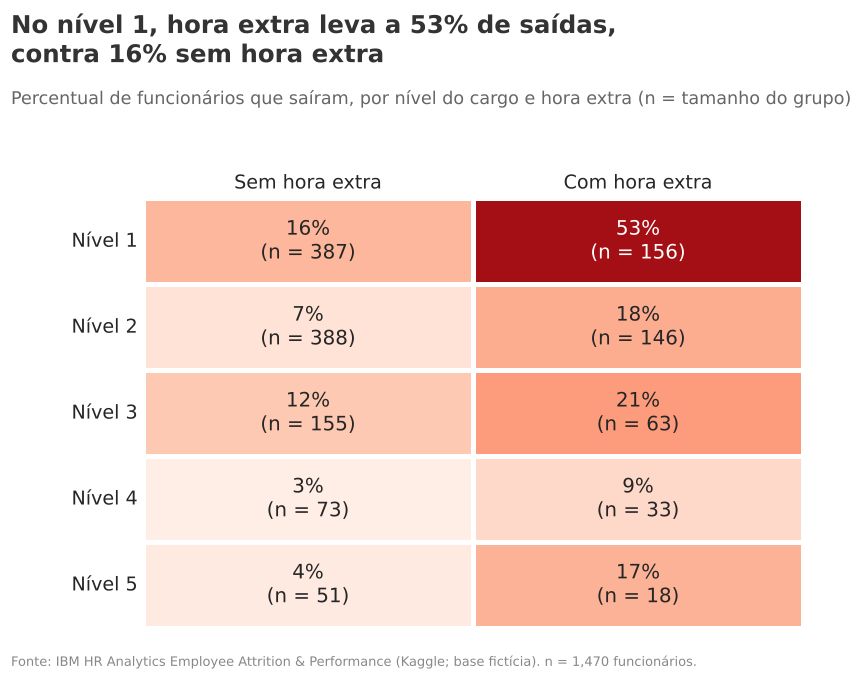

In [58]:
checar_vars("JobLevel", "OverTime", "Attrition")
g = y_bin.groupby([df["JobLevel"], df["OverTime"]], observed=True)
taxa = g.mean().unstack()
n = g.size().unstack()
notas = taxa.copy().astype(object)
for i in taxa.index:
    for j in taxa.columns:
        notas.loc[i, j] = f"{taxa.loc[i, j]:.0%}\n(n = {int(n.loc[i, j])})"
taxa_plot = taxa.rename(columns={"No": "Sem hora extra", "Yes": "Com hora extra"})
taxa_plot.index = [f"Nível {i}" for i in taxa_plot.index]

fig, ax = plt.subplots(figsize=(7.5, 6.2))
sns.heatmap(taxa_plot, annot=notas.values, fmt="", cmap="Reds", vmin=0, vmax=0.6, cbar=False, linewidths=3,
            linecolor="white", annot_kws={"fontsize": 13}, ax=ax)
ax.set_xlabel("")
ax.set_ylabel("")
ax.xaxis.tick_top()
ax.tick_params(axis="both", labelsize=12.5, length=0)
plt.setp(ax.get_yticklabels(), rotation=0)
fig.subplots_adjust(top=0.70, bottom=0.07, left=0.17, right=0.97)
titulos_finais(fig, f"No nível 1, hora extra leva a {taxa.loc[1, 'Yes']:.0%} de saídas, contra {taxa.loc[1, 'No']:.0%} sem hora extra",
               "Percentual de funcionários que saíram, por nível do cargo e hora extra (n = tamanho do grupo)")
plt.show()

**Conclusão:** No nível 1, hora extra leva a 53% de saídas contra 16% sem hora extra (+36,8 pontos), um efeito muito maior do que nos demais níveis (entre +6 e +13 pontos). A célula de maior risco é a de funcionários iniciantes com hora extra, onde estão 156 pessoas.

### Gráfico final 5: idade e estado civil (aprimora a Visualização 9)
Pergunta do público: *"Que perfil de funcionário sai mais?"*

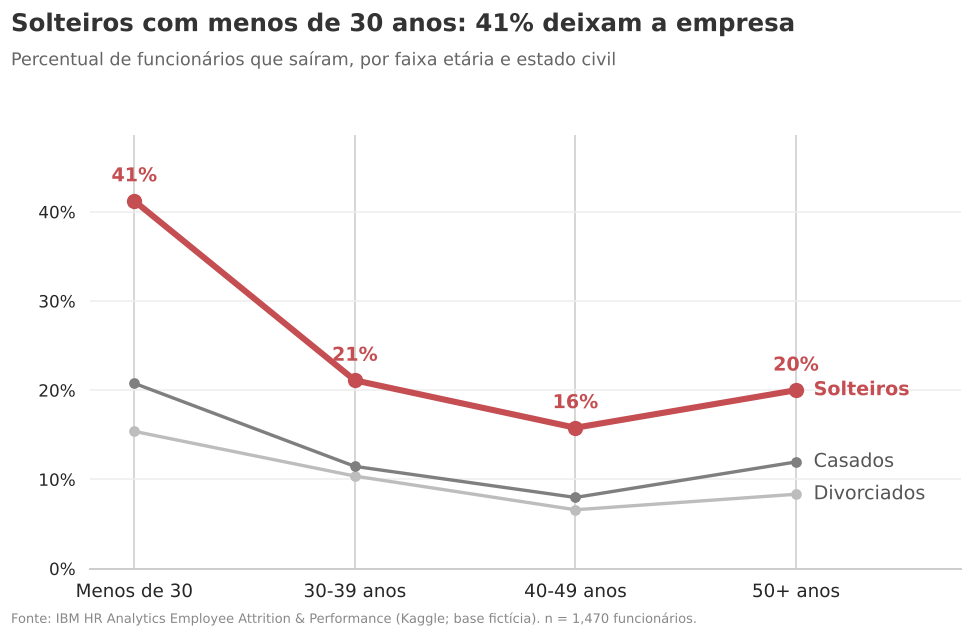

In [59]:
checar_vars("AgeGroup", "MaritalStatus", "Attrition")
ordem_idade = ["<30", "30-39", "40-49", "50+"]
taxa = y_bin.groupby([df["AgeGroup"], df["MaritalStatus"]], observed=True).mean().unstack().reindex(ordem_idade)
nomes_ec = {"Single": "Solteiros", "Married": "Casados", "Divorced": "Divorciados"}
cores_ec = {"Single": COR_DESTAQUE, "Married": "#7F7F7F", "Divorced": "#BDBDBD"}

fig, ax = plt.subplots(figsize=(9, 5.8))
x = np.arange(len(ordem_idade))
for ec in ["Divorced", "Married", "Single"]:                       # "Single" por último: fica por cima
    destaque = ec == "Single"
    ax.plot(x, taxa[ec].values, marker="o", lw=4 if destaque else 2.2, ms=9 if destaque else 6,
            color=cores_ec[ec], zorder=3 if destaque else 2)
    ax.text(x[-1] + 0.08, taxa[ec].values[-1], nomes_ec[ec], va="center", fontsize=12.5,
            color=cores_ec[ec] if destaque else "#555555", fontweight="bold" if destaque else "normal")
for xi, v in zip(x, taxa["Single"].values):
    ax.text(xi, v + 0.022, f"{v:.0%}", ha="center", fontsize=12.5, fontweight="bold", color=COR_DESTAQUE)
ax.set_xticks(x)
ax.set_xticklabels([f"{a} anos" if a != "<30" else "Menos de 30" for a in ordem_idade], fontsize=12)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
ax.set_ylim(0, taxa.values.max() * 1.18)
ax.set_xlim(-0.2, len(ordem_idade) - 1 + 0.75)
sns.despine(left=True)
ax.grid(axis="y", color="#EEEEEE")
ax.set_axisbelow(True)
fig.subplots_adjust(top=0.78, bottom=0.10, left=0.09, right=0.97)
titulos_finais(fig, f"Solteiros com menos de 30 anos: {taxa.loc['<30', 'Single']:.0%} deixam a empresa",
               "Percentual de funcionários que saíram, por faixa etária e estado civil")
plt.show()

**Conclusão:** Solteiros com menos de 30 anos têm 41% de saída (n = 131), o grupo de maior risco entre as combinações de idade e estado civil. A idade não é monotônica (a taxa volta a subir após os 50 anos, com poucos casos), mas o recorte jovem e solteiro merece atenção em programas de integração e carreira.

# Pipeline

Nesta etapa, o pré-processamento é montado com `pandas` e `numpy`: cada transformação é uma pequena função, e os parâmetros são aprendidos no treino e aplicados ao treino e ao teste. O pipeline contém as três famílias de transformação exigidas:

| Etapa | Técnica | Variáveis | Por quê |
|---|---|---|---|
| **Re-escala** | Mínimo-máximo: `(x - mín) / (máx - mín)` (para [0, 1]) | Variáveis ordinais e limitadas (satisfações, nível do cargo, opções de ações, % de aumento, treinamentos, `SatisfactionIndex`) | Já têm limites naturais; a re-escala preserva a ordem e a forma da distribuição. |
| **Padronização** | Z-score: `(x - média) / desvio` (média 0, desvio 1) | Variáveis contínuas aproximadamente simétricas (`Age`, `DailyRate`, `HourlyRate`, `MonthlyRate`, razões de carreira) | Coloca variáveis em unidades diferentes na mesma escala, para modelos baseados em distância ou gradiente. |
| **Normalização (distribuição)** | Logaritmo `log(1 + x)` seguido de Z-score | Variáveis fortemente assimétricas (`MonthlyIncome`, `TotalWorkingYears`, `IncomePerYearExp`, `YearsPerCompany`, `NumCompaniesWorked`, `DistanceFromHome`) | Reduz a assimetria (vista na análise univariada) e aproxima a distribuição de uma normal, sem excluir os valores extremos. |
| **Normalização (vetor)** | Norma L2 por linha: `x / raiz(soma dos x²)` | Perfil de tempo: `YearsAtCompany`, `YearsInCurrentRole`, `YearsSinceLastPromotion`, `YearsWithCurrManager` | Faz cada funcionário ter "vetor de tempo" de norma 1: preserva a *forma* do perfil de carreira (por exemplo, quem está há muito tempo sem promoção em relação ao resto) e remove a magnitude, que já é capturada por `TotalWorkingYears` e pelas razões de carreira. |
| **Codificação** | *One-hot* com `pd.get_dummies` | Variáveis categóricas (as binárias ficam com uma só coluna) | Modelos de ML precisam de entradas numéricas. |

**Cuidado com vazamento de dados (*data leakage*):** os parâmetros de cada transformação (mínimo/máximo, média/desvio, categorias) são aprendidos **somente no conjunto de treino** e apenas aplicados ao teste. Por isso a divisão treino/teste vem antes do ajuste, e é **estratificada** por causa do desbalanceamento das classes.

In [60]:
# crie nesta seção o pipeline com as etapas de pré-processamento necessárias
X = df.drop(columns=ALVO)
y = (df[ALVO] == "Yes").astype(int)

GRUPOS = {
    "rescala_minmax": ["Education", "EnvironmentSatisfaction", "JobInvolvement", "JobLevel", "JobSatisfaction",
                       "PerformanceRating", "RelationshipSatisfaction", "StockOptionLevel", "WorkLifeBalance",
                       "TrainingTimesLastYear", "PercentSalaryHike", "SatisfactionIndex"],
    "padronizacao": ["Age", "DailyRate", "HourlyRate", "MonthlyRate", "CompanyTenureRatio",
                     "ManagerStability", "PromotionRatio"],
    "normaliza_log": ["MonthlyIncome", "TotalWorkingYears", "IncomePerYearExp", "YearsPerCompany",
                             "NumCompaniesWorked", "DistanceFromHome"],
    "normaliza_l2": ["YearsAtCompany", "YearsInCurrentRole", "YearsSinceLastPromotion", "YearsWithCurrManager"],
    "categoricas": ["BusinessTravel", "Department", "EducationField", "JobRole", "MaritalStatus", "AgeGroup"],
    "binarias": ["Gender", "OverTime"],
    "passa_direto": ["LongCommute"],
}

# Todo atributo precisa ter exatamente um destino no pipeline
usadas = [c for cols in GRUPOS.values() for c in cols]
assert sorted(usadas) == sorted(X.columns), set(X.columns) ^ set(usadas)
print(f"{len(usadas)} atributos distribuídos em {len(GRUPOS)} grupos de transformação.")

# Divisão treino/teste ANTES de ajustar o pré-processamento (evita vazamento), estratificada pelo alvo:
# sorteamos 20% de cada classe (saíram / ficaram) para o teste, mantendo a proporção de saídas nos dois conjuntos.
rng = np.random.RandomState(RANDOM_STATE)
idx_teste = np.concatenate([rng.choice(g.index, size=round(len(g) * 0.2), replace=False) for _, g in y.groupby(y)])
X_teste, y_teste = X.loc[np.sort(idx_teste)], y.loc[np.sort(idx_teste)]
X_treino, y_treino = X.drop(index=idx_teste), y.drop(index=idx_teste)
print(f"Treino: {X_treino.shape[0]} linhas ({y_treino.mean():.1%} de saídas) | "
      f"Teste: {X_teste.shape[0]} linhas ({y_teste.mean():.1%} de saídas)")

# --- Passo 1: aprender os parâmetros SOMENTE no treino ---
def aprender_parametros(Xt):
    p = {}
    p["minmax"] = {"min": Xt[GRUPOS["rescala_minmax"]].min(), "max": Xt[GRUPOS["rescala_minmax"]].max()}
    p["zscore"] = {"media": Xt[GRUPOS["padronizacao"]].mean(), "desvio": Xt[GRUPOS["padronizacao"]].std(ddof=0)}
    logs = np.log1p(Xt[GRUPOS["normaliza_log"]])
    p["log"] = {"media": logs.mean(), "desvio": logs.std(ddof=0)}
    p["categorias"] = {c: sorted(Xt[c].astype(str).unique()) for c in GRUPOS["categoricas"] + GRUPOS["binarias"]}
    return p

# --- Passo 2: aplicar as transformações (no treino e no teste) com os parâmetros aprendidos ---
def aplicar_pipeline(Xn, p):
    partes = []
    g = GRUPOS["rescala_minmax"]                                           # re-escala: [0, 1]
    partes.append(((Xn[g] - p["minmax"]["min"]) / (p["minmax"]["max"] - p["minmax"]["min"])).add_prefix("rescala_minmax__"))
    g = GRUPOS["padronizacao"]                                             # padronização: média 0, desvio 1
    partes.append(((Xn[g] - p["zscore"]["media"]) / p["zscore"]["desvio"]).add_prefix("padronizacao__"))
    g = GRUPOS["normaliza_log"]                                            # log(1 + x) e depois z-score
    partes.append(((np.log1p(Xn[g]) - p["log"]["media"]) / p["log"]["desvio"]).add_prefix("normaliza_log__"))
    g = GRUPOS["normaliza_l2"]                                             # cada linha passa a ter norma 1
    norma = np.sqrt((Xn[g] ** 2).sum(axis=1)).replace(0, 1)                # linhas só com zeros continuam zero
    partes.append(Xn[g].div(norma, axis=0).add_prefix("normaliza_l2__"))
    for c in GRUPOS["categoricas"]:                                        # one-hot: uma coluna por categoria
        cat = pd.Categorical(Xn[c].astype(str), categories=p["categorias"][c])
        partes.append(pd.get_dummies(cat, prefix=c, dtype=int).set_index(Xn.index).add_prefix("categoricas__"))
    for c in GRUPOS["binarias"]:                                           # binárias: uma coluna (1 = segunda categoria)
        segunda = p["categorias"][c][1]
        partes.append(pd.DataFrame({f"{c}_{segunda}": (Xn[c].astype(str) == segunda).astype(int)}).add_prefix("binarias__"))
    partes.append(Xn[GRUPOS["passa_direto"]].astype(int).add_prefix("passa_direto__"))
    return pd.concat(partes, axis=1)

parametros = aprender_parametros(X_treino)
X_treino_t = aplicar_pipeline(X_treino, parametros)      # aprende no treino...
X_teste_t = aplicar_pipeline(X_teste, parametros)        # ...e apenas aplica no teste
print(f"Matriz transformada: treino {X_treino_t.shape} | teste {X_teste_t.shape}")
display(X_treino_t.head())

38 atributos distribuídos em 7 grupos de transformação.
Treino: 1176 linhas (16.2% de saídas) | Teste: 294 linhas (16.0% de saídas)
Matriz transformada: treino (1176, 60) | teste (294, 60)


,rescala_minmax__Education,rescala_minmax__EnvironmentSatisfaction,rescala_minmax__JobInvolvement,rescala_minmax__JobLevel,rescala_minmax__JobSatisfaction,rescala_minmax__PerformanceRating,rescala_minmax__RelationshipSatisfaction,rescala_minmax__StockOptionLevel,rescala_minmax__WorkLifeBalance,rescala_minmax__TrainingTimesLastYear,...,categoricas__MaritalStatus_Divorced,categoricas__MaritalStatus_Married,categoricas__MaritalStatus_Single,categoricas__AgeGroup_30-39,categoricas__AgeGroup_40-49,categoricas__AgeGroup_50+,categoricas__AgeGroup_<30,binarias__Gender_Male,binarias__OverTime_Yes,passa_direto__LongCommute
0,0.25,0.333333,0.666667,0.25,1.000000,0.0,0.000000,0.000000,0.000000,0.0,...,0,0,1,0,1,0,0,0,1,0
1,0.00,0.666667,0.333333,0.25,0.333333,1.0,1.000000,0.333333,0.666667,0.5,...,0,1,0,0,1,0,0,1,0,0
2,0.25,1.000000,0.333333,0.00,0.666667,0.0,0.333333,0.000000,0.666667,0.5,...,0,0,1,1,0,0,0,1,1,0
3,0.75,1.000000,0.666667,0.00,0.666667,0.0,0.666667,0.000000,0.666667,0.5,...,0,1,0,1,0,0,0,0,1,0
4,0.00,0.000000,0.666667,0.00,0.333333,0.0,1.000000,0.333333,0.666667,0.5,...,0,1,0,0,0,0,1,1,0,0


### Verificação do pipeline

Conferimos, por código, se cada etapa fez o que promete (essas verificações interrompem a execução se algo estiver errado):

In [61]:
tol = 1e-8
mm = X_treino_t.filter(like="rescala_minmax__")
assert mm.min().min() >= -tol and mm.max().max() <= 1 + tol, "MinMax fora de [0, 1] no treino"
print(f"Re-escala (MinMax): mínimo = {mm.min().min():.2f}, máximo = {mm.max().max():.2f}  (esperado: 0 e 1)")

sd = X_treino_t.filter(like="padronizacao__")
assert np.allclose(sd.mean(), 0, atol=1e-6) and np.allclose(sd.std(ddof=0), 1, atol=1e-6)
print(f"Padronização: média máxima em módulo = {sd.mean().abs().max():.1e}, desvio padrão entre {sd.std(ddof=0).min():.2f} e {sd.std(ddof=0).max():.2f}")

yj = X_treino_t.filter(like="normaliza_log__")
assert np.allclose(yj.mean(), 0, atol=1e-6) and np.allclose(yj.std(ddof=0), 1, atol=1e-6)
assim_antes = X_treino[GRUPOS["normaliza_log"]].apply(stats.skew)
assim_depois = yj.apply(stats.skew); assim_depois.index = assim_antes.index
print("Normalização (log + z-score), assimetria antes -> depois:")
display(pd.DataFrame({"antes": assim_antes, "depois": assim_depois}).round(2))

l2 = X_treino_t.filter(like="normaliza_l2__")
normas = np.linalg.norm(l2.values, axis=1)
assert np.all(np.isclose(normas, 1) | np.isclose(normas, 0))
print(f"Normalização L2: norma de cada linha = 1 em {np.isclose(normas, 1).sum()} funcionários "
      f"(os {np.isclose(normas, 0).sum()} sem nenhum ano de empresa/cargo ficam com vetor zero, por definição)")

assert not X_treino_t.isna().any().any() and not X_teste_t.isna().any().any()
print("Sem valores ausentes após a transformação. Pipeline verificado.")

Re-escala (MinMax): mínimo = 0.00, máximo = 1.00  (esperado: 0 e 1)
Padronização: média máxima em módulo = 2.6e-16, desvio padrão entre 1.00 e 1.00
Normalização (log + z-score), assimetria antes -> depois:


,antes,depois
MonthlyIncome,1.36,0.29
TotalWorkingYears,1.11,-0.63
IncomePerYearExp,1.07,-0.31
YearsPerCompany,3.07,0.34
NumCompaniesWorked,1.00,0.08
DistanceFromHome,0.96,-0.01


Normalização L2: norma de cada linha = 1 em 1144 funcionários (os 32 sem nenhum ano de empresa/cargo ficam com vetor zero, por definição)
Sem valores ausentes após a transformação. Pipeline verificado.


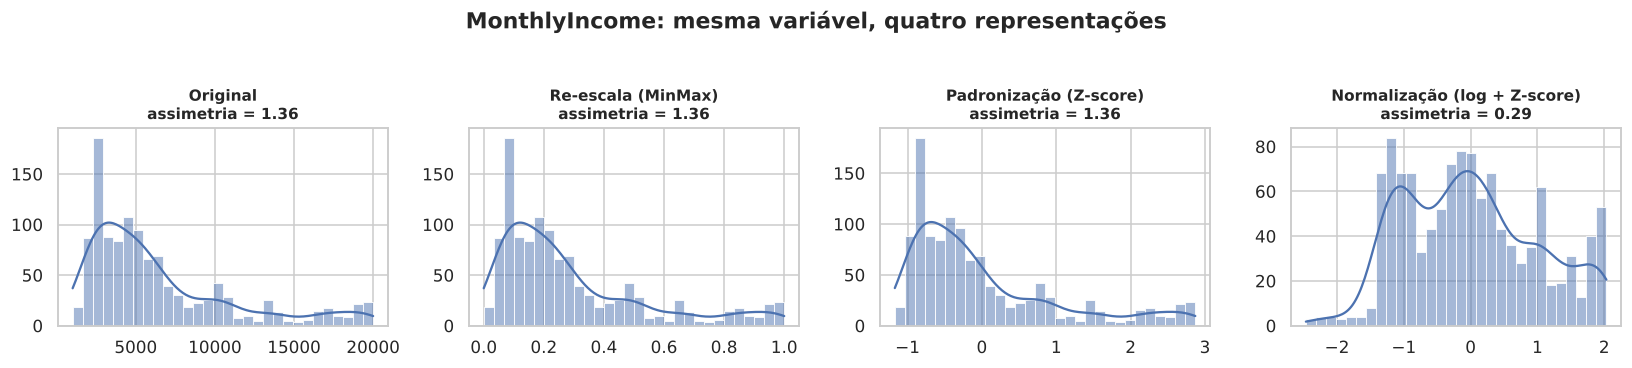

In [62]:
# Efeito de cada técnica sobre a mesma variável (MonthlyIncome, no conjunto de treino)
renda = X_treino["MonthlyIncome"]
versoes = {
    "Original": renda.values,
    "Re-escala (MinMax)": ((renda - renda.min()) / (renda.max() - renda.min())).values,
    "Padronização (Z-score)": ((renda - renda.mean()) / renda.std(ddof=0)).values,
    "Normalização (log + Z-score)": ((np.log1p(renda) - np.log1p(renda).mean()) / np.log1p(renda).std(ddof=0)).values,
}
fig, eixos = plt.subplots(1, 4, figsize=(15, 3.2))
for ax, (nome, v) in zip(eixos, versoes.items()):
    sns.histplot(v, bins=30, kde=True, ax=ax, color="#4C72B0")
    ax.set_title(f"{nome}\nassimetria = {stats.skew(v):.2f}", fontsize=10)
    ax.set_xlabel("")
    ax.set_ylabel("")
plt.suptitle("MonthlyIncome: mesma variável, quatro representações", y=1.04, fontweight="bold")
plt.tight_layout()
plt.show()

A re-escala e a padronização **mudam a escala, mas mantêm a forma** (a assimetria é idêntica à original). Somente a transformação logarítmica altera a forma e reduz a assimetria, o que é útil para modelos que supõem distribuições mais próximas da normal.

In [63]:
# Teste de sanidade: o pré-processamento preservou a informação sobre a saída?
# Correlação de cada variável transformada (treino) com Attrition e comparação treino x teste.
corr = X_treino_t.apply(lambda col: col.corr(y_treino)).sort_values(key=np.abs, ascending=False)
print("Variáveis transformadas mais correlacionadas com Attrition (treino):")
display(corr.head(8).round(3).to_frame("correlação"))

tx_treino = y_treino.groupby(X_treino["OverTime"]).mean()
tx_teste = y_teste.groupby(X_teste["OverTime"]).mean()
print("Taxa de saída por OverTime (treino x teste):")
display(pd.DataFrame({"treino": tx_treino, "teste": tx_teste}).round(3))
dif = (X_teste_t.filter(like="padronizacao__").mean() - X_treino_t.filter(like="padronizacao__").mean()).abs().max()
print(f"Diferença máxima entre as médias padronizadas de teste e treino: {dif:.2f} desvios (pequena = o teste é parecido com o treino).")

Variáveis transformadas mais correlacionadas com Attrition (treino):


,correlação
binarias__OverTime_Yes,0.258
normaliza_log__TotalWorkingYears,-0.228
normaliza_log__YearsPerCompany,-0.224
normaliza_log__MonthlyIncome,-0.192
categoricas__AgeGroup_<30,0.170
rescala_minmax__JobLevel,-0.169
padronizacao__Age,-0.161
normaliza_l2__YearsInCurrentRole,-0.159


Taxa de saída por OverTime (treino x teste):


,treino,teste
OverTime,,
No,0.102,0.114
Yes,0.313,0.274


Diferença máxima entre as médias padronizadas de teste e treino: 0.08 desvios (pequena = o teste é parecido com o treino).


**Leitura:** o pipeline roda de ponta a ponta e as variáveis transformadas continuam relacionadas à saída (por exemplo, `OverTime`, `JobLevel` e `MonthlyIncome` aparecem entre as mais correlacionadas), o que indica que as transformações não destruíram a informação. A divisão estratificada mantém a proporção de saídas parecida entre treino e teste, e como os parâmetros vieram só do treino, o teste não vaza para o ajuste. A modelagem preditiva fica fora do escopo deste projeto.

# Entrega

Para entregar este trabalho, siga as seguintes instruções:
1. Execute todo este código, garantindo que todas as células tenham sido executadas sem erros.
2. Exporte uma cópia deste código em formato Python puro (*.py*)
3. Guarde uma cópia da base de dados em formato *.csv* ou *.parquet*
4. Compacte os arquivos em um único arquivo *.zip* e envie na atividade no AVA/Canvas.

In [64]:
# Arquivos para a entrega: a base tratada (CSV) já foi salva na seção "Carregue os dados".
# No Google Colab, esta célula baixa o CSV para o seu computador (fora do Colab, apenas confirma o arquivo).
assert os.path.exists("ibm_hr_attrition_tratado.csv")
print("Base tratada:", "ibm_hr_attrition_tratado.csv", f"({len(pd.read_csv('ibm_hr_attrition_tratado.csv'))} linhas)")
try:
    from google.colab import files
    files.download("ibm_hr_attrition_tratado.csv")
except ImportError:
    pass
# Para exportar o .py no Colab: menu Arquivo > Fazer download > Fazer download do .py

Base tratada: ibm_hr_attrition_tratado.csv (1470 linhas)
